# [0.1] Project imports


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# [0.2] Master project path

In [2]:

PROJECT_ROOT = Path(
    r"D:\DS Projects\Adaptive Market Risk Intelligence System"
)

# DATA
DATA_DIR = PROJECT_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

# OUTPUT
OUTPUT_DIR = PROJECT_ROOT / "output"
FIGURES_DIR = OUTPUT_DIR / "figures"

EXPLORATORY_DIR = FIGURES_DIR / "exploratory"
RESEARCH_DIR = FIGURES_DIR / "research"

EXPLORATORY_NIFTY_DIR = EXPLORATORY_DIR / "nifty"
RESEARCH_NIFTY_DIR = RESEARCH_DIR / "nifty"

LINKEDIN_DIR = OUTPUT_DIR / "linkedin"
MODELS_DIR = OUTPUT_DIR / "models"
TABLES_DIR = OUTPUT_DIR / "tables"

# Create required directories
for directory in [
    RAW_DATA_DIR,
    PROCESSED_DATA_DIR,
    EXPLORATORY_NIFTY_DIR,
    RESEARCH_NIFTY_DIR,
    LINKEDIN_DIR,
    MODELS_DIR,
    TABLES_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

# [0.3] Verify project paths

In [3]:
print("PROJECT_ROOT:", PROJECT_ROOT)
print("RAW_DATA_DIR:", RAW_DATA_DIR)
print("PROCESSED_DATA_DIR:", PROCESSED_DATA_DIR)
print("EXPLORATORY_NIFTY_DIR:", EXPLORATORY_NIFTY_DIR)
print("RESEARCH_NIFTY_DIR:", RESEARCH_NIFTY_DIR)
print("LINKEDIN_DIR:", LINKEDIN_DIR)
print("MODELS_DIR:", MODELS_DIR)
print("TABLES_DIR:", TABLES_DIR)

PROJECT_ROOT: D:\DS Projects\Adaptive Market Risk Intelligence System
RAW_DATA_DIR: D:\DS Projects\Adaptive Market Risk Intelligence System\data\raw
PROCESSED_DATA_DIR: D:\DS Projects\Adaptive Market Risk Intelligence System\data\processed
EXPLORATORY_NIFTY_DIR: D:\DS Projects\Adaptive Market Risk Intelligence System\output\figures\exploratory\nifty
RESEARCH_NIFTY_DIR: D:\DS Projects\Adaptive Market Risk Intelligence System\output\figures\research\nifty
LINKEDIN_DIR: D:\DS Projects\Adaptive Market Risk Intelligence System\output\linkedin
MODELS_DIR: D:\DS Projects\Adaptive Market Risk Intelligence System\output\models
TABLES_DIR: D:\DS Projects\Adaptive Market Risk Intelligence System\output\tables


# [0.101] NIFTY 50 download function

In [4]:
# [02.01] NIFTY 50 download function

def download_nifty_data(
    start_date: str,
    end_date: str,
    output_path: Path = RAW_DATA_DIR / "nifty50_yfinance.csv",
) -> pd.DataFrame:

    data = yf.download(
        "^NSEI",
        start=start_date,
        end=end_date,
        interval="1d",
        auto_adjust=False,
        progress=False,
    )

    if data.empty:
        raise ValueError("No NIFTY data was downloaded.")

    output_file = Path(output_path)
    output_file.parent.mkdir(parents=True, exist_ok=True)

    data.to_csv(output_file)

    return data

In [5]:
# [02.01] NIFTY 50 download function

def download_nifty_data(
    start_date: str,
    end_date: str,
    output_path: Path = RAW_DATA_DIR / "nifty50_yfinance.csv",
) -> pd.DataFrame:

    data = yf.download(
        "^NSEI",
        start=start_date,
        end=end_date,
        interval="1d",
        auto_adjust=False,
        progress=False,
    )

    if data.empty:
        raise ValueError("No NIFTY data was downloaded.")

    output_file = Path(output_path)
    output_file.parent.mkdir(parents=True, exist_ok=True)

    data.to_csv(output_file)

    return data

# 01 — Data Exploration

## Adaptive Market Regime & Volatility Intelligence System

### Objective
Understand, inspect, and validate the raw financial-market data before
cleaning, feature engineering, statistical modelling, and machine learning.

### Research principle
No modelling before understanding the data.

## 1. Environment Check

In [6]:
import sys
import pandas as pd
import numpy as np

print("Python:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python: d:\DS Projects\Adaptive Market Risk Intelligence System\.venv\Scripts\python.exe
Pandas: 3.0.6
NumPy: 2.5.3


#### Testing for Small sample data
##### Nifty data for complete Aug session

In [7]:
import yfinance as yf

In [8]:
nifty = yf.download(
    "^NSEI",
    start="2026-08-01",
    end="2026-09-01",
    interval="1d"
)

nifty.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,^NSEI,^NSEI,^NSEI,^NSEI,^NSEI
Date,,,,,
2026-08-03,24774.300781,24774.300781,24515.150391,24572.699219,342300
2026-08-04,24614.900391,24703.900391,24427.949219,24703.900391,296500
2026-08-05,24624.650391,24677.599609,24497.949219,24669.199219,355500
2026-08-06,24636.000000,24677.050781,24604.150391,24641.000000,344000
2026-08-07,24570.650391,24630.400391,24522.750000,24538.900391,254800


In [9]:
print("Shape:", nifty.shape)

print("\nColumns:")
print(nifty.columns)

print("\nData types:")
print(nifty.dtypes)

print("\nIndex:")
print(nifty.index)

Shape: (21, 5)

Columns:
MultiIndex([( 'Close', '^NSEI'),
            (  'High', '^NSEI'),
            (   'Low', '^NSEI'),
            (  'Open', '^NSEI'),
            ('Volume', '^NSEI')],
           names=['Price', 'Ticker'])

Data types:
Price   Ticker
Close   ^NSEI     float64
High    ^NSEI     float64
Low     ^NSEI     float64
Open    ^NSEI     float64
Volume  ^NSEI       int64
dtype: object

Index:
DatetimeIndex(['2026-08-03', '2026-08-04', '2026-08-05', '2026-08-06',
               '2026-08-07', '2026-08-10', '2026-08-11', '2026-08-12',
               '2026-08-13', '2026-08-14', '2026-08-17', '2026-08-18',
               '2026-08-19', '2026-08-20', '2026-08-21', '2026-08-24',
               '2026-08-25', '2026-08-26', '2026-08-27', '2026-08-28',
               '2026-08-31'],
              dtype='datetime64[s]', name='Date', freq=None)


In [10]:
nifty.describe()

Price,Close,High,Low,Open,Volume
Ticker,^NSEI,^NSEI,^NSEI,^NSEI,^NSEI
count,21.000000,21.000000,21.000000,21.000000,21.000000
mean,24361.273996,24426.835751,24276.671410,24385.587984,298609.523810
std,209.745800,194.137330,183.441314,189.350370,102595.447778
min,24078.300781,24128.699219,23993.599609,24117.550781,225400.000000
25%,24207.750000,24284.050781,24144.300781,24225.449219,244800.000000
50%,24334.550781,24378.599609,24226.949219,24343.449219,269500.000000
75%,24570.650391,24620.949219,24429.250000,24572.699219,317600.000000
max,24774.300781,24774.300781,24604.150391,24703.900391,710900.000000


##### 2. Price Returns

Raw price levels are not directly suitable for most volatility and
risk modelling. We therefore transform prices into returns.

We calculate both simple returns and log returns so that we can compare
their behavior and use the appropriate representation in later models.

In [11]:
# Extract the NIFTY closing price series
close = nifty[("Close", "^NSEI")]

# Simple return
simple_return = close.pct_change()

# Log return
log_return = np.log(close / close.shift(1))

# Combine them for inspection
returns = pd.DataFrame({
    "Close": close,
    "Simple_Return": simple_return,
    "Log_Return": log_return
})

returns.head()

,Close,Simple_Return,Log_Return
Date,,,
2026-08-03,24774.300781,NaN,NaN
2026-08-04,24614.900391,-0.006434,-0.006455
2026-08-05,24624.650391,0.000396,0.000396
2026-08-06,24636.000000,0.000461,0.000461
2026-08-07,24570.650391,-0.002653,-0.002656


In [12]:
returns.describe()

,Close,Simple_Return,Log_Return
count,21.000000,20.000000,20.000000
mean,24361.273996,-0.001414,-0.001420
std,209.745800,0.003486,0.003487
min,24078.300781,-0.006434,-0.006455
25%,24207.750000,-0.004095,-0.004103
50%,24334.550781,-0.001551,-0.001552
75%,24570.650391,0.000479,0.000479
max,24774.300781,0.006377,0.006357


In [13]:
daily_volatility = returns["Simple_Return"].std()

print("Daily volatility:", daily_volatility)
print("Daily volatility (%):", daily_volatility * 100)

Daily volatility: 0.0034856235477015154
Daily volatility (%): 0.3485623547701515


In [14]:
rolling_volatility_5d = returns["Simple_Return"].rolling(window=5).std()

rolling_volatility_5d.head(10)

Date
2026-08-03         NaN
2026-08-04         NaN
2026-08-05         NaN
2026-08-06         NaN
2026-08-07         NaN
2026-08-10    0.003052
2026-08-11    0.002330
2026-08-12    0.002161
2026-08-13    0.001859
2026-08-14    0.001834
Name: Simple_Return, dtype: float64

In [15]:
returns["Simple_Return"].std()

np.float64(0.0034856235477015154)

In [16]:
returns["Simple_Return"].rolling(window=5).std()

Date
2026-08-03         NaN
2026-08-04         NaN
2026-08-05         NaN
2026-08-06         NaN
2026-08-07         NaN
2026-08-10    0.003052
2026-08-11    0.002330
2026-08-12    0.002161
2026-08-13    0.001859
2026-08-14    0.001834
2026-08-17    0.001429
2026-08-18    0.001782
2026-08-19    0.001669
2026-08-20    0.004568
2026-08-21    0.004672
2026-08-24    0.004516
2026-08-25    0.004028
2026-08-26    0.004670
2026-08-27    0.004154
2026-08-28    0.004624
2026-08-31    0.004864
Name: Simple_Return, dtype: float64

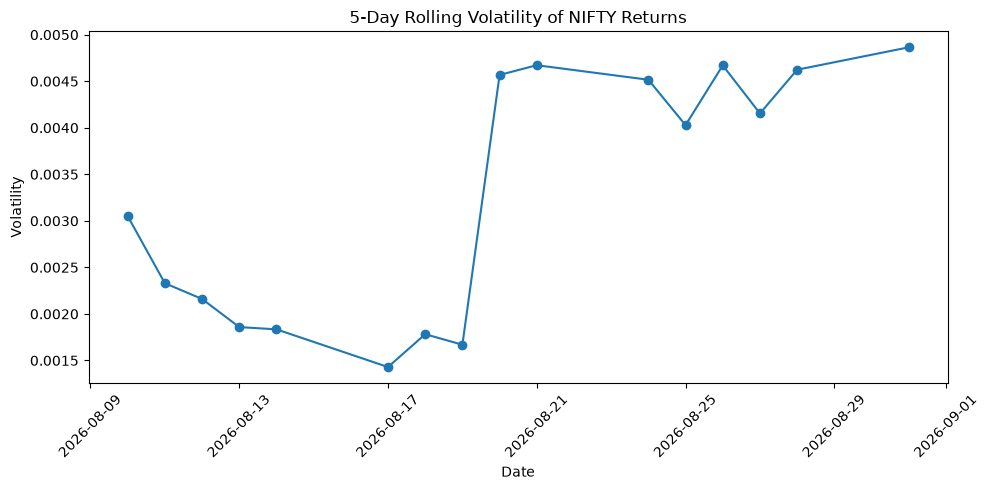

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5)) #overall canvas where plot be made

#now actual plot designing from basically its index what would be what data should be present everything
plt.plot(
    returns.index,
    rolling_volatility_5d,
    marker="o" #for marking
)

plt.title("5-Day Rolling Volatility of NIFTY Returns")
plt.xlabel("Date")
plt.ylabel("Volatility")

plt.xticks(rotation=45) #for fixing or readablity adjustment
plt.tight_layout()  #adjusting spacing
plt.show()

In [18]:
five_returns = returns.loc[
    "2026-08-10":"2026-08-14",
    "Simple_Return"
]

five_returns

Date
2026-08-10    0.000535
2026-08-11   -0.004560
2026-08-12   -0.001461
2026-08-13   -0.001641
2026-08-14   -0.001224
Name: Simple_Return, dtype: float64

In [19]:
five_returns.mean()

np.float64(-0.0016700404799946168)

In [20]:
five_returns.std()

np.float64(0.0018343115714468514)

In [21]:
returns["Squared_Return"] = returns["Simple_Return"] ** 2

In [22]:
lambda_ = 0.94

returns["EWMA_Variance"] = np.nan
valid_returns = returns["Simple_Return"].dropna()

In [23]:
initial_variance = valid_returns.iloc[:5].var()

initial_date = valid_returns.index[4]

returns.loc[initial_date, "EWMA_Variance"] = initial_variance

print("Initial date:", initial_date)
print("Initial variance:", initial_variance)

Initial date: 2026-08-10 00:00:00
Initial variance: 9.312179701354635e-06


In [24]:
returns[["Simple_Return", "EWMA_Variance"]].head(10)

,Simple_Return,EWMA_Variance
Date,,
2026-08-03,NaN,NaN
2026-08-04,-0.006434,NaN
2026-08-05,0.000396,NaN
2026-08-06,0.000461,NaN
2026-08-07,-0.002653,NaN
2026-08-10,0.000535,0.000009
2026-08-11,-0.004560,NaN
2026-08-12,-0.001461,NaN
2026-08-13,-0.001641,NaN


In [25]:
for i in range(5, len(returns)):

    previous_date = returns.index[i - 1]
    current_date = returns.index[i]

    previous_variance = returns.loc[
        previous_date, "EWMA_Variance"
    ]

    previous_return = returns.loc[
        previous_date, "Simple_Return"
    ]

    if pd.notna(previous_variance) and pd.notna(previous_return):
        returns.loc[current_date, "EWMA_Variance"] = (
            lambda_ * previous_variance
            + (1 - lambda_) * previous_return**2
        )

In [26]:
returns["EWMA_Volatility"] = np.sqrt(
    returns["EWMA_Variance"]
)

returns[
    ["Simple_Return", "EWMA_Variance", "EWMA_Volatility"]
].loc["2026-08-10":]

,Simple_Return,EWMA_Variance,EWMA_Volatility
Date,,,
2026-08-10,0.000535,0.000009,0.003052
2026-08-11,-0.004560,0.000009,0.002962
2026-08-12,-0.001461,0.000009,0.003081
2026-08-13,-0.001641,0.000009,0.003008
2026-08-14,-0.001224,0.000009,0.002944
2026-08-17,-0.003216,0.000008,0.002870
2026-08-18,-0.005466,0.000008,0.002892
2026-08-19,-0.003171,0.000010,0.003107
2026-08-20,0.006377,0.000010,0.003111


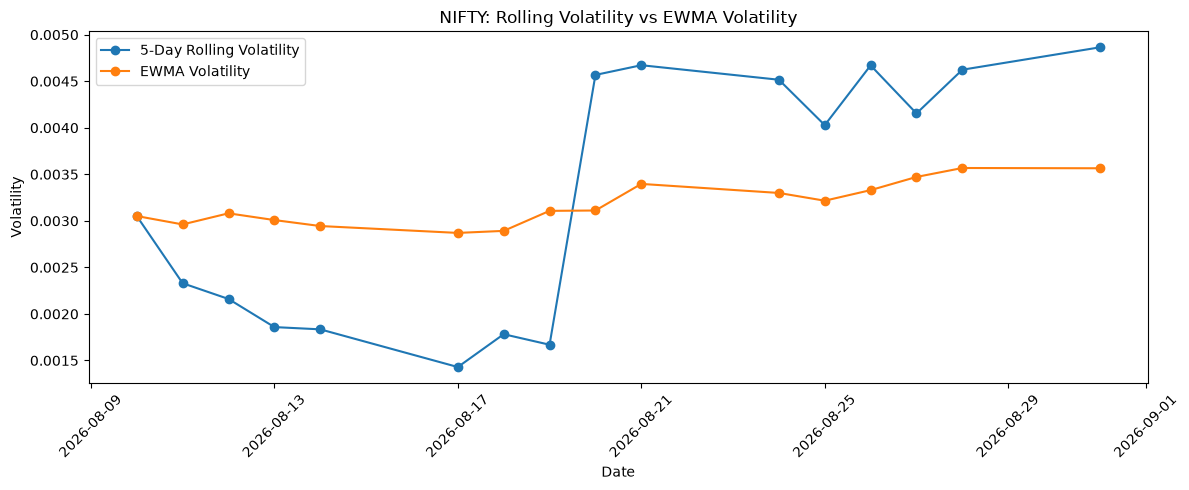

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(
    returns.index,
    rolling_volatility_5d,
    label="5-Day Rolling Volatility",
    marker="o"
)

plt.plot(
    returns.index,
    returns["EWMA_Volatility"],
    label="EWMA Volatility",
    marker="o"
)

plt.title("NIFTY: Rolling Volatility vs EWMA Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
import arch

print("arch version:", arch.__version__)

arch version: 8.0.0


In [29]:
import sys
print(sys.executable)

import scipy
print("SciPy:", scipy.__version__)

import arch
print("arch:", arch.__version__)

d:\DS Projects\Adaptive Market Risk Intelligence System\.venv\Scripts\python.exe
SciPy: 1.18.1
arch: 8.0.0


In [30]:
from arch import arch_model

garch_returns = returns["Simple_Return"].dropna() * 100

garch_returns.head()

Date
2026-08-04   -0.643410
2026-08-05    0.039610
2026-08-06    0.046090
2026-08-07   -0.265261
2026-08-10    0.053521
Name: Simple_Return, dtype: float64

In [31]:
garch_model = arch_model(
    garch_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

In [32]:
garch_result = garch_model.fit(disp="off")

In [33]:
print(garch_result.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:          Simple_Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -6.53793
Distribution:                  Normal   AIC:                           21.0759
Method:            Maximum Likelihood   BIC:                           25.0588
                                        No. Observations:                   20
Date:                Sat, Sep 26 2026   Df Residuals:                       19
Time:                        22:10:51   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu            -0.1467  7.586e-02     -1.933  5.318e-02 [ -0.295,

In [34]:
garch_result.params

mu         -1.466797e-01
omega       2.213654e-03
alpha[1]    1.937164e-14
beta[1]     1.000000e+00
Name: params, dtype: float64

In [35]:
alpha = garch_result.params["alpha[1]"]
beta = garch_result.params["beta[1]"]

persistence = alpha + beta

print("Alpha:", alpha)
print("Beta:", beta)
print("Alpha + Beta:", persistence)

Alpha: 1.937164185694276e-14
Beta: 0.9999999999999736
Alpha + Beta: 0.9999999999999929


In [36]:
garch_volatility = garch_result.conditional_volatility

garch_volatility

Date
2026-08-04    0.323061
2026-08-05    0.326469
2026-08-06    0.329842
2026-08-07    0.333180
2026-08-10    0.336486
2026-08-11    0.339759
2026-08-12    0.343002
2026-08-13    0.346213
2026-08-14    0.349396
2026-08-17    0.352549
2026-08-18    0.355675
2026-08-19    0.358773
2026-08-20    0.361845
2026-08-21    0.364891
2026-08-24    0.367912
2026-08-25    0.370908
2026-08-26    0.373880
2026-08-27    0.376829
2026-08-28    0.379755
2026-08-31    0.382659
Name: cond_vol, dtype: float64

In [37]:
persistence = alpha + beta

In [38]:
volatility_comparison = pd.DataFrame({
    "Rolling_5D": rolling_volatility_5d * 100,
    "EWMA": returns["EWMA_Volatility"] * 100,
    "GARCH": garch_volatility
})

volatility_comparison

,Rolling_5D,EWMA,GARCH
Date,,,
2026-08-03,NaN,NaN,NaN
2026-08-04,NaN,NaN,0.323061
2026-08-05,NaN,NaN,0.326469
2026-08-06,NaN,NaN,0.329842
2026-08-07,NaN,NaN,0.333180
2026-08-10,0.305159,0.305159,0.336486
2026-08-11,0.232971,0.296153,0.339759
2026-08-12,0.216070,0.308091,0.343002
2026-08-13,0.185852,0.300841,0.346213


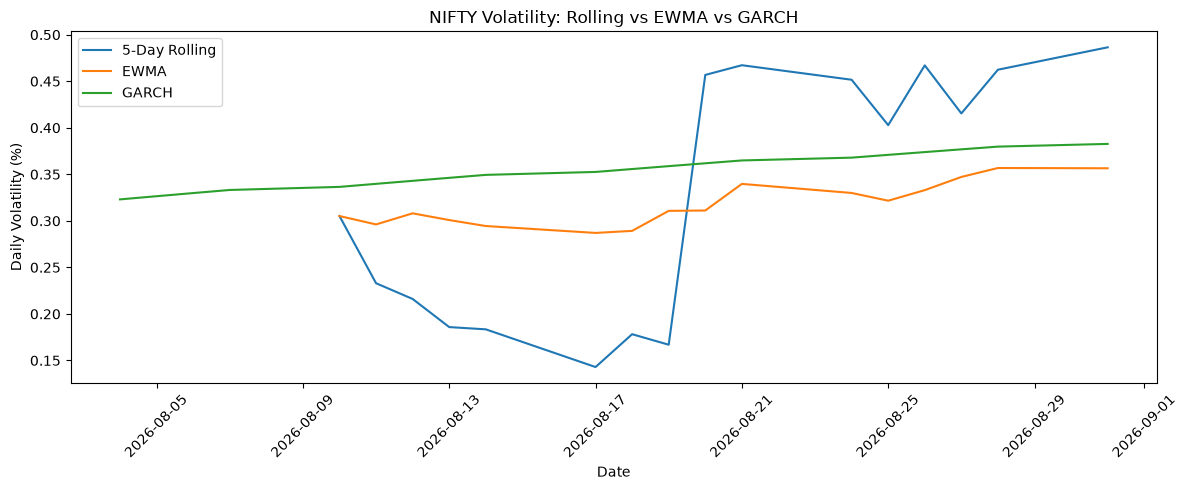

In [39]:
plt.figure(figsize=(12, 5))

plt.plot(
    volatility_comparison.index,
    volatility_comparison["Rolling_5D"],
    label="5-Day Rolling"
)

plt.plot(
    volatility_comparison.index,
    volatility_comparison["EWMA"],
    label="EWMA"
)

plt.plot(
    volatility_comparison.index,
    volatility_comparison["GARCH"],
    label="GARCH"
)

plt.title("NIFTY Volatility: Rolling vs EWMA vs GARCH")
plt.xlabel("Date")
plt.ylabel("Daily Volatility (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [40]:
volatility_comparison = pd.DataFrame({
    "Rolling_5D": rolling_volatility_5d * 100,
    "EWMA": returns["EWMA_Volatility"] * 100,
    "GARCH": garch_volatility
})

volatility_comparison

,Rolling_5D,EWMA,GARCH
Date,,,
2026-08-03,NaN,NaN,NaN
2026-08-04,NaN,NaN,0.323061
2026-08-05,NaN,NaN,0.326469
2026-08-06,NaN,NaN,0.329842
2026-08-07,NaN,NaN,0.333180
2026-08-10,0.305159,0.305159,0.336486
2026-08-11,0.232971,0.296153,0.339759
2026-08-12,0.216070,0.308091,0.343002
2026-08-13,0.185852,0.300841,0.346213


In [41]:
volatility_comparison.loc[
    "2026-08-19":"2026-08-21"
]

,Rolling_5D,EWMA,GARCH
Date,,,
2026-08-19,0.166900,0.310731,0.358773
2026-08-20,0.456780,0.311118,0.361845
2026-08-21,0.467215,0.339686,0.364891


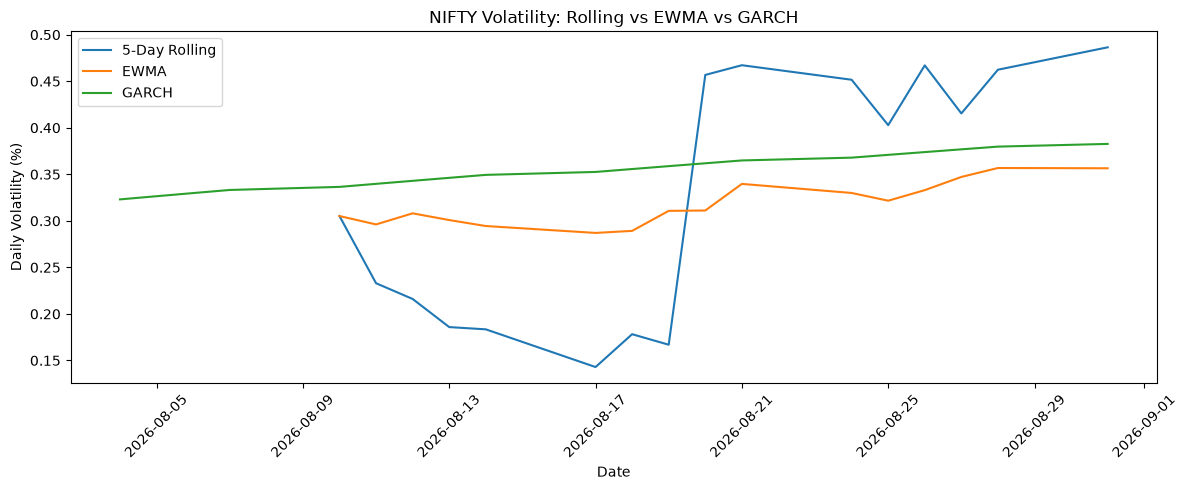

In [42]:
plt.figure(figsize=(12, 5))

plt.plot(
    volatility_comparison.index,
    volatility_comparison["Rolling_5D"],
    label="5-Day Rolling"
)

plt.plot(
    volatility_comparison.index,
    volatility_comparison["EWMA"],
    label="EWMA"
)

plt.plot(
    volatility_comparison.index,
    volatility_comparison["GARCH"],
    label="GARCH"
)

plt.title("NIFTY Volatility: Rolling vs EWMA vs GARCH")
plt.xlabel("Date")
plt.ylabel("Daily Volatility (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [43]:
import numpy as np
from scipy.stats import norm

In [44]:
def black_scholes_call(S, K, T, r, sigma):

    d1 = (
        np.log(S / K)
        + (r + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    call_price = (
        S * norm.cdf(d1)
        - K * np.exp(-r * T) * norm.cdf(d2)
    )

    return call_price

In [45]:
price = black_scholes_call(
    S=25000,
    K=25000,
    T=30/365,
    r=0.06,
    sigma=0.20
)

print(price)

633.981073884901


In [46]:
volatilities = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35]

for sigma in volatilities:
    price = black_scholes_call(
        S=25000,
        K=25000,
        T=30/365,
        r=0.06,
        sigma=sigma
    )

    print(
        f"Volatility: {sigma:.0%} | "
        f"Option Price: ₹{price:.2f}"
    )

Volatility: 10% | Option Price: ₹350.92
Volatility: 15% | Option Price: ₹492.11
Volatility: 20% | Option Price: ₹633.98
Volatility: 25% | Option Price: ₹776.10
Volatility: 30% | Option Price: ₹918.32
Volatility: 35% | Option Price: ₹1060.58


In [47]:
from scipy.optimize import brentq

In [48]:
def iv_objective(sigma):
    model_price = black_scholes_call(
        S=25000,
        K=25000,
        T=30/365,
        r=0.06,
        sigma=sigma
    )

    return model_price - 700

In [49]:
implied_volatility = brentq(
    iv_objective,
    0.01,
    2.00
)

print("Implied Volatility:", implied_volatility)
print(
    "Implied Volatility (%):",
    implied_volatility * 100
)

Implied Volatility: 0.2232334750035197
Implied Volatility (%): 22.32334750035197


In [50]:
from pathlib import Path
import os
import sys

print("Current working directory:")
print(os.getcwd())

print("\nNotebook-visible files:")
print(list(Path(".").iterdir())[:10])

print("\nPython import paths:")
for path in sys.path:
    print(path)

Current working directory:
d:\DS Projects\Adaptive Market Risk Intelligence System\Notebooks

Notebook-visible files:
[WindowsPath('01_data_exploration.ipynb')]

Python import paths:
C:\Users\user\AppData\Local\Programs\Python\Python313\python313.zip
C:\Users\user\AppData\Local\Programs\Python\Python313\DLLs
C:\Users\user\AppData\Local\Programs\Python\Python313\Lib
C:\Users\user\AppData\Local\Programs\Python\Python313
d:\DS Projects\Adaptive Market Risk Intelligence System\.venv

d:\DS Projects\Adaptive Market Risk Intelligence System\.venv\Lib\site-packages
D:\DS Projects\Adaptive Market Risk Intelligence System\src


In [51]:
from pathlib import Path

project_root = Path(r"D:\DS Projects\Adaptive Market Risk Intelligence System")

print("src exists:", (project_root / "src").exists())
print("ingestion exists:", (project_root / "src" / "ingestion").exists())
print("nifty.py exists:", (project_root / "src" / "ingestion" / "nifty.py").exists())
print("__init__.py in src:", (project_root / "src" / "__init__.py").exists())
print("__init__.py in ingestion:", (project_root / "src" / "ingestion" / "__init__.py").exists())

src exists: True
ingestion exists: True
nifty.py exists: True
__init__.py in src: False
__init__.py in ingestion: True


In [52]:
from ingestion.nifty import download_nifty_data

print("Import successful!")

Import successful!


### Real Data Validation

In [53]:
nifty = download_nifty_data(
    start_date="2018-01-01",
    end_date="2026-09-23"
)

print("Shape:", nifty.shape)

print("\nFirst 5 rows:")
print(nifty.head())

print("\nLast 5 rows:")
print(nifty.tail())

Shape: (2150, 6)

First 5 rows:
Price          Adj Close         Close          High           Low  \
Ticker             ^NSEI         ^NSEI         ^NSEI         ^NSEI   
Date                                                                 
2018-01-02  10442.200195  10442.200195  10495.200195  10404.650391   
2018-01-03  10443.200195  10443.200195  10503.599609  10429.549805   
2018-01-04  10504.799805  10504.799805  10513.000000  10441.450195   
2018-01-05  10558.849609  10558.849609  10566.099609  10520.099609   
2018-01-08  10623.599609  10623.599609  10631.200195  10588.549805   

Price               Open  Volume  
Ticker             ^NSEI   ^NSEI  
Date                              
2018-01-02  10477.549805  153400  
2018-01-03  10482.650391  167300  
2018-01-04  10469.400391  174900  
2018-01-05  10534.250000  180900  
2018-01-08  10591.700195  169000  

Last 5 rows:
Price          Adj Close         Close          High           Low  \
Ticker             ^NSEI         ^NSEI     

In [54]:
print("Shape:", nifty.shape)

print("\nColumn structure:")
print(nifty.columns)

print("\nIndex:")
print(nifty.index)

print("\nData types:")
print(nifty.dtypes)

Shape: (2150, 6)

Column structure:
MultiIndex([('Adj Close', '^NSEI'),
            (    'Close', '^NSEI'),
            (     'High', '^NSEI'),
            (      'Low', '^NSEI'),
            (     'Open', '^NSEI'),
            (   'Volume', '^NSEI')],
           names=['Price', 'Ticker'])

Index:
DatetimeIndex(['2018-01-02', '2018-01-03', '2018-01-04', '2018-01-05',
               '2018-01-08', '2018-01-09', '2018-01-10', '2018-01-11',
               '2018-01-12', '2018-01-15',
               ...
               '2026-09-08', '2026-09-09', '2026-09-10', '2026-09-11',
               '2026-09-15', '2026-09-16', '2026-09-17', '2026-09-18',
               '2026-09-21', '2026-09-22'],
              dtype='datetime64[s]', name='Date', length=2150, freq=None)

Data types:
Price      Ticker
Adj Close  ^NSEI     float64
Close      ^NSEI     float64
High       ^NSEI     float64
Low        ^NSEI     float64
Open       ^NSEI     float64
Volume     ^NSEI       int64
dtype: object


In [55]:
print("Start date:", nifty.index.min())
print("End date:", nifty.index.max())
print("Number of observations:", len(nifty))

Start date: 2018-01-02 00:00:00
End date: 2026-09-22 00:00:00
Number of observations: 2150


In [56]:
print("Duplicate dates:", nifty.index.duplicated().sum())

Duplicate dates: 0


In [57]:
print(nifty.isna().sum())

Price      Ticker
Adj Close  ^NSEI     0
Close      ^NSEI     0
High       ^NSEI     0
Low        ^NSEI     0
Open       ^NSEI     0
Volume     ^NSEI     0
dtype: int64


In [58]:
zero_volume = nifty[nifty[("Volume", "^NSEI")] == 0]

print("Zero-volume observations:", len(zero_volume))
print(zero_volume)

Zero-volume observations: 27
Price          Adj Close         Close          High           Low  \
Ticker             ^NSEI         ^NSEI         ^NSEI         ^NSEI   
Date                                                                 
2018-04-27  10692.299805  10692.299805  10719.799805  10647.549805   
2018-05-21  10516.700195  10516.700195  10621.700195  10505.799805   
2018-07-06  10772.650391  10772.650391  10816.349609  10735.049805   
2018-07-13  11018.900391  11018.900391  11071.349609  10999.750000   
2018-08-10  11429.500000  11429.500000  11478.750000  11419.650391   
2018-09-11  11287.500000  11287.500000  11479.400391  11274.000000   
2018-09-24  10967.400391  10967.400391  11170.150391  10943.599609   
2018-10-10  10460.099609  10460.099609  10482.349609  10318.250000   
2018-10-25  10124.900391  10124.900391  10166.599609  10079.299805   
2018-11-06  10530.000000  10530.000000  10600.250000  10491.450195   
2018-11-15  10616.700195  10616.700195  10646.500000  10557.5

In [59]:
close = nifty[("Close", "^NSEI")]
high = nifty[("High", "^NSEI")]
low = nifty[("Low", "^NSEI")]
open_price = nifty[("Open", "^NSEI")]

print("High < Low:", (high < low).sum())
print("High < Open:", (high < open_price).sum())
print("High < Close:", (high < close).sum())
print("Low > Open:", (low > open_price).sum())
print("Low > Close:", (low > close).sum())

High < Low: 0
High < Open: 0
High < Close: 0
Low > Open: 0
Low > Close: 0


In [60]:
missing_adj_close = nifty[nifty[("Adj Close", "^NSEI")].isna()]

print("Missing Adj Close observations:", len(missing_adj_close))
print(missing_adj_close)

Missing Adj Close observations: 0
Empty DataFrame
Columns: [(Adj Close, ^NSEI), (Close, ^NSEI), (High, ^NSEI), (Low, ^NSEI), (Open, ^NSEI), (Volume, ^NSEI)]
Index: []


In [61]:
missing_adj_close = nifty[nifty[("Adj Close", "^NSEI")].isna()]

print("Missing Adj Close observations:", len(missing_adj_close))
print(missing_adj_close)

Missing Adj Close observations: 0
Empty DataFrame
Columns: [(Adj Close, ^NSEI), (Close, ^NSEI), (High, ^NSEI), (Low, ^NSEI), (Open, ^NSEI), (Volume, ^NSEI)]
Index: []


In [62]:
print("Missing Close values:", nifty[("Close", "^NSEI")].isna().sum())

Missing Close values: 0


In [63]:
missing_adj_close = nifty[nifty[("Adj Close", "^NSEI")].isna()]

print("Missing Adj Close observations:", len(missing_adj_close))
print(missing_adj_close)
print("Missing Close values:", nifty[("Close", "^NSEI")].isna().sum())

Missing Adj Close observations: 0
Empty DataFrame
Columns: [(Adj Close, ^NSEI), (Close, ^NSEI), (High, ^NSEI), (Low, ^NSEI), (Open, ^NSEI), (Volume, ^NSEI)]
Index: []
Missing Close values: 0


In [64]:
clean_nifty = pd.DataFrame({
    "Date": nifty.index,
    "Open": nifty[("Open", "^NSEI")].values,
    "High": nifty[("High", "^NSEI")].values,
    "Low": nifty[("Low", "^NSEI")].values,
    "Close": nifty[("Close", "^NSEI")].values,
    "Volume": nifty[("Volume", "^NSEI")].values
})

clean_nifty.head()

,Date,Open,High,Low,Close,Volume
0,2018-01-02,10477.549805,10495.200195,10404.650391,10442.200195,153400
1,2018-01-03,10482.650391,10503.599609,10429.549805,10443.200195,167300
2,2018-01-04,10469.400391,10513.000000,10441.450195,10504.799805,174900
3,2018-01-05,10534.250000,10566.099609,10520.099609,10558.849609,180900
4,2018-01-08,10591.700195,10631.200195,10588.549805,10623.599609,169000


In [65]:
clean_nifty = clean_nifty.dropna(subset=["Close"]).copy()

In [66]:
clean_nifty = clean_nifty.reset_index(drop=True)

In [67]:
print("Shape:", clean_nifty.shape)
print("\nMissing values:")
print(clean_nifty.isna().sum())

print("\nDate range:")
print(clean_nifty["Date"].min(), "to", clean_nifty["Date"].max())

print("\nLast 5 observations:")
print(clean_nifty.tail())

Shape: (2150, 6)

Missing values:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Date range:
2018-01-02 00:00:00 to 2026-09-22 00:00:00

Last 5 observations:
           Date          Open          High           Low         Close  \
2145 2026-09-16  23201.599609  23284.750000  23116.099609  23217.599609   
2146 2026-09-17  23195.250000  23363.550781  23193.650391  23270.599609   
2147 2026-09-18  23334.699219  23389.150391  23286.599609  23346.400391   
2148 2026-09-21  23330.199219  23466.800781  23314.800781  23414.300781   
2149 2026-09-22  23454.050781  23489.000000  23285.750000  23329.000000   

      Volume  
2145  261600  
2146  259700  
2147  375300  
2148  213600  
2149  244100  


In [68]:
from pathlib import Path

# ============================================================
# SAVE CLEANED NIFTY DATA
# ============================================================

output_path = PROCESSED_DATA_DIR / "nifty50_clean.csv"

output_path.parent.mkdir(parents=True, exist_ok=True)

clean_nifty.to_csv(
    output_path,
    index=False
)

print("Saved cleaned NIFTY data to:")
print(output_path)

Saved cleaned NIFTY data to:
D:\DS Projects\Adaptive Market Risk Intelligence System\data\processed\nifty50_clean.csv


In [69]:
import numpy as np

clean_nifty["Simple_Return"] = (
    clean_nifty["Close"].pct_change()
)

clean_nifty["Log_Return"] = (
    np.log(
        clean_nifty["Close"] /
        clean_nifty["Close"].shift(1)
    )
)

In [70]:
import numpy as np

clean_nifty["Simple_Return"] = (
    clean_nifty["Close"].pct_change()
)

clean_nifty["Log_Return"] = (
    np.log(
        clean_nifty["Close"] /
        clean_nifty["Close"].shift(1)
    )
)

In [71]:
print("Simple return missing:",
      clean_nifty["Simple_Return"].isna().sum())

print("Log return missing:",
      clean_nifty["Log_Return"].isna().sum())

Simple return missing: 1
Log return missing: 1


In [72]:
print(
    clean_nifty[
        ["Date", "Close", "Simple_Return", "Log_Return"]
    ].head(10)
)

        Date         Close  Simple_Return  Log_Return
0 2018-01-02  10442.200195            NaN         NaN
1 2018-01-03  10443.200195       0.000096    0.000096
2 2018-01-04  10504.799805       0.005899    0.005881
3 2018-01-05  10558.849609       0.005145    0.005132
4 2018-01-08  10623.599609       0.006132    0.006114
5 2018-01-09  10637.000000       0.001261    0.001261
6 2018-01-10  10632.200195      -0.000451   -0.000451
7 2018-01-11  10651.200195       0.001787    0.001785
8 2018-01-12  10681.250000       0.002821    0.002817
9 2018-01-15  10741.549805       0.005645    0.005630


In [73]:
print(
    clean_nifty[
        ["Simple_Return", "Log_Return"]
    ].describe()
)

       Simple_Return   Log_Return
count    2149.000000  2149.000000
mean        0.000431     0.000374
std         0.010631     0.010699
min        -0.129805    -0.139038
25%        -0.004498    -0.004508
50%         0.000625     0.000624
75%         0.005955     0.005937
max         0.087632     0.084003


In [74]:
largest_moves = clean_nifty[
    ["Date", "Close", "Simple_Return"]
].sort_values(
    "Simple_Return"
)

print("Largest negative returns:")
print(largest_moves.head(10))

print("\nLargest positive returns:")
print(largest_moves.tail(10))

Largest negative returns:
           Date         Close  Simple_Return
542  2020-03-23   7610.250000      -0.129805
535  2020-03-12   9590.150391      -0.083019
537  2020-03-16   9197.400391      -0.076121
1579 2024-06-04  21884.500000      -0.059294
567  2020-05-04   9293.500000      -0.057445
539  2020-03-18   8468.799805      -0.055565
533  2020-03-09  10451.450195      -0.048956
1021 2022-02-24  16247.950195      -0.047781
547  2020-03-30   8281.099609      -0.043781
549  2020-04-01   8253.799805      -0.040005

Largest positive returns:
           Date         Close  Simple_Return
1810 2025-05-12  24924.699219       0.038183
548  2020-03-31   8597.750000       0.038238
545  2020-03-26   8641.450195       0.038904
553  2020-04-09   9111.900391       0.041509
756  2021-02-01  14281.200195       0.047424
419  2019-09-20  11274.200195       0.053191
541  2020-03-20   8745.450195       0.058329
544  2020-03-25   8317.849609       0.066247
551  2020-04-07   8792.200195       0.087632
0 

In [75]:
clean_nifty["Squared_Return"] = (
    clean_nifty["Simple_Return"] ** 2
)

clean_nifty["Absolute_Return"] = (
    clean_nifty["Simple_Return"].abs()
)

In [76]:
print(
    clean_nifty[
        [
            "Date",
            "Simple_Return",
            "Absolute_Return",
            "Squared_Return"
        ]
    ].head(10)
)

        Date  Simple_Return  Absolute_Return  Squared_Return
0 2018-01-02            NaN              NaN             NaN
1 2018-01-03       0.000096         0.000096    9.170985e-09
2 2018-01-04       0.005899         0.005899    3.479275e-05
3 2018-01-05       0.005145         0.005145    2.647358e-05
4 2018-01-08       0.006132         0.006132    3.760506e-05
5 2018-01-09       0.001261         0.001261    1.591078e-06
6 2018-01-10      -0.000451         0.000451    2.036146e-07
7 2018-01-11       0.001787         0.001787    3.193456e-06
8 2018-01-12       0.002821         0.002821    7.959508e-06
9 2018-01-15       0.005645         0.005645    3.187041e-05


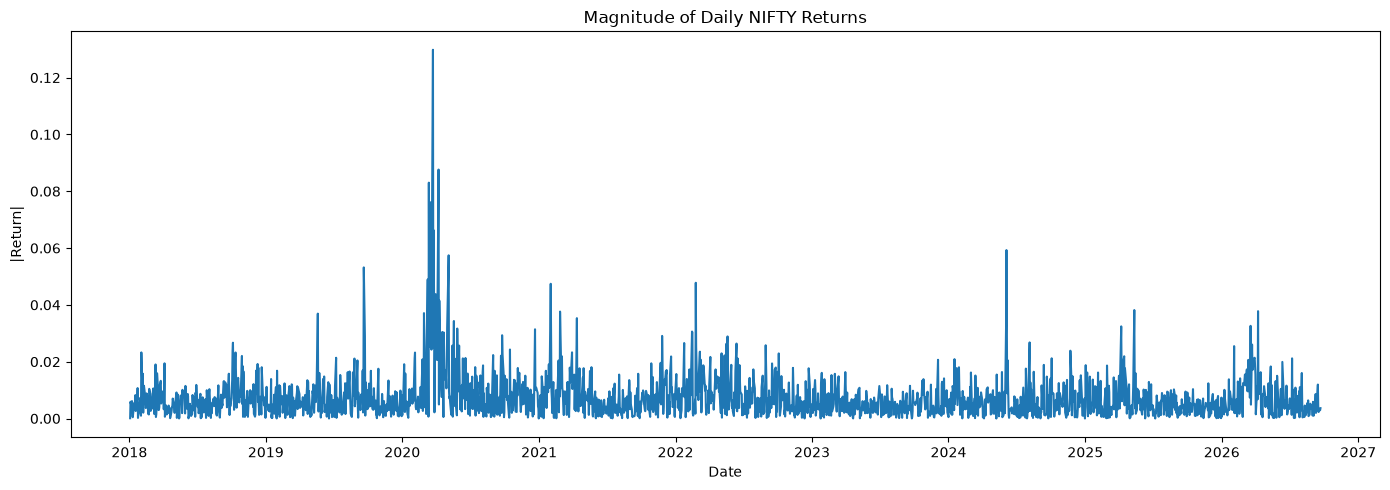

In [77]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    clean_nifty["Date"],
    clean_nifty["Absolute_Return"]
)

plt.title("Magnitude of Daily NIFTY Returns")
plt.xlabel("Date")
plt.ylabel("|Return|")

plt.tight_layout()
plt.show()

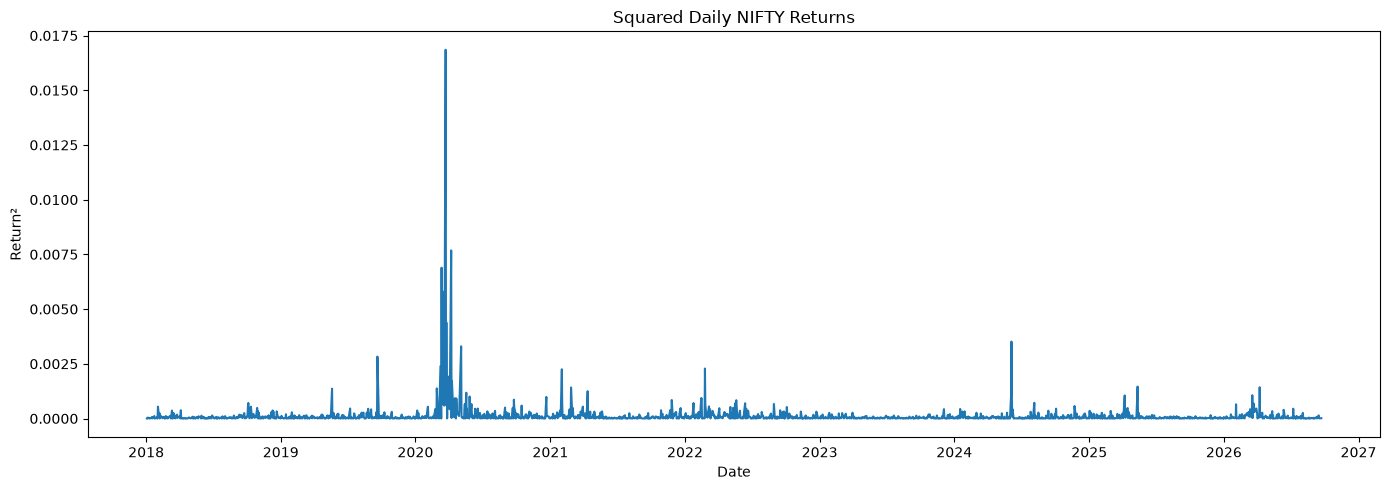

In [78]:
plt.figure(figsize=(14, 5))

plt.plot(
    clean_nifty["Date"],
    clean_nifty["Squared_Return"]
)

plt.title("Squared Daily NIFTY Returns")
plt.xlabel("Date")
plt.ylabel("Return²")

plt.tight_layout()
plt.show()

In [79]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=clean_nifty["Date"],
        y=clean_nifty["Simple_Return"] * 100,
        mode="lines",
        name="Daily Return"
    )
)

fig.add_hline(
    y=0,
    line_dash="dash"
)

fig.update_layout(
    title="NIFTY 50 Daily Returns — 2018 to 2026",
    xaxis_title="Date",
    yaxis_title="Daily Return (%)",
    hovermode="x unified",
    height=600
)

fig.show()

In [80]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=clean_nifty["Date"],
        y=clean_nifty["Absolute_Return"] * 100,
        mode="lines",
        name="Absolute Return"
    )
)

fig.update_layout(
    title="NIFTY 50 Daily Return Magnitude — 2018 to 2026",
    xaxis_title="Date",
    yaxis_title="Absolute Return (%)",
    hovermode="x unified",
    height=600
)

fig.show()

In [81]:
crisis_2020 = clean_nifty[
    (clean_nifty["Date"] >= "2020-03-01") &
    (clean_nifty["Date"] <= "2020-05-31")
].copy()

In [82]:
fig = go.Figure()

fig.add_trace(
    go.Bar(
        x=crisis_2020["Date"],
        y=crisis_2020["Simple_Return"] * 100,
        name="Daily Return"
    )
)

fig.add_hline(
    y=0,
    line_dash="dash"
)

fig.update_layout(
    title="NIFTY 50 Daily Returns — March to May 2020",
    xaxis_title="Date",
    yaxis_title="Daily Return (%)",
    hovermode="x unified",
    height=600
)

fig.show()

In [83]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=crisis_2020["Date"],
        y=crisis_2020["Close"],
        mode="lines",
        name="NIFTY Close"
    )
)

fig.update_layout(
    title="NIFTY 50 Price — March to May 2020",
    xaxis_title="Date",
    yaxis_title="NIFTY Level",
    hovermode="x unified",
    height=500
)

fig.show()

In [84]:
clean_nifty["Rolling_Vol_5D"] = (
    clean_nifty["Log_Return"]
    .rolling(window=5)
    .std()
)

clean_nifty["Rolling_Vol_5D_Annualized"] = (
    clean_nifty["Rolling_Vol_5D"] * np.sqrt(252)
)

In [85]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=clean_nifty["Date"],
        y=clean_nifty["Rolling_Vol_5D_Annualized"] * 100,
        mode="lines",
        name="5-Day Rolling Volatility"
    )
)

fig.update_layout(
    title="NIFTY 50 — 5-Day Rolling Annualized Volatility",
    xaxis_title="Date",
    yaxis_title="Annualized Volatility (%)",
    hovermode="x unified",
    height=600
)

fig.show()

In [86]:
lambda_ewma = 0.94

clean_nifty["EWMA_Variance"] = np.nan

initial_variance = clean_nifty["Log_Return"].var()

clean_nifty.loc[1, "EWMA_Variance"] = initial_variance

for i in range(2, len(clean_nifty)):
    previous_variance = clean_nifty.loc[i - 1, "EWMA_Variance"]
    previous_return = clean_nifty.loc[i - 1, "Log_Return"]

    clean_nifty.loc[i, "EWMA_Variance"] = (
        lambda_ewma * previous_variance
        + (1 - lambda_ewma) * previous_return**2
    )

clean_nifty["EWMA_Volatility"] = np.sqrt(
    clean_nifty["EWMA_Variance"]
)

clean_nifty["EWMA_Volatility_Annualized"] = (
    clean_nifty["EWMA_Volatility"] * np.sqrt(252)
)

In [87]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=clean_nifty["Date"],
        y=clean_nifty["EWMA_Volatility_Annualized"] * 100,
        mode="lines",
        name="EWMA Volatility"
    )
)

fig.update_layout(
    title="NIFTY 50 — EWMA Annualized Volatility",
    xaxis_title="Date",
    yaxis_title="Annualized Volatility (%)",
    hovermode="x unified",
    height=600
)

fig.show()

In [88]:
from pathlib import Path

# ============================================================
# EXPLORATORY NIFTY OUTPUT DIRECTORY
# ============================================================

output_dir = EXPLORATORY_NIFTY_DIR

output_dir.mkdir(parents=True, exist_ok=True)

print("Exploratory NIFTY output folder:")
print(output_dir)

Exploratory NIFTY output folder:
D:\DS Projects\Adaptive Market Risk Intelligence System\output\figures\exploratory\nifty


In [89]:
fig.write_html(
    EXPLORATORY_NIFTY_DIR / "daily_returns.html"
)

fig.show()

In [90]:
fig.write_html(
    EXPLORATORY_NIFTY_DIR / "daily_returns.html"
)

fig.show()

In [91]:
fig.write_html(
    EXPLORATORY_NIFTY_DIR / "daily_returns.html"
)

In [92]:
from arch import arch_model

garch_returns = clean_nifty["Log_Return"].dropna() * 100

garch_model = arch_model(
    garch_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="normal"
)

garch_result = garch_model.fit(
    disp="off"
)

print(garch_result.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:             Log_Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -2768.36
Distribution:                  Normal   AIC:                           5544.71
Method:            Maximum Likelihood   BIC:                           5567.40
                                        No. Observations:                 2149
Date:                Sat, Sep 26 2026   Df Residuals:                     2148
Time:                        22:10:58   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu             0.0591  1.903e-02      3.104  1.908e-03 [2.

In [93]:
garch_volatility = garch_result.conditional_volatility

clean_nifty.loc[
    garch_volatility.index,
    "GARCH_Volatility"
] = garch_volatility

clean_nifty["GARCH_Volatility_Annualized"] = (
    clean_nifty["GARCH_Volatility"] / 100 * np.sqrt(252)
)

In [94]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=clean_nifty["Date"],
        y=clean_nifty["GARCH_Volatility_Annualized"] * 100,
        mode="lines",
        name="GARCH Volatility"
    )
)

fig.update_layout(
    title="NIFTY 50 — GARCH(1,1) Annualized Conditional Volatility",
    xaxis_title="Date",
    yaxis_title="Annualized Volatility (%)",
    hovermode="x unified",
    height=600
)

fig.show()

In [95]:
standardized_residuals = garch_result.std_resid.dropna()

print("Number of standardized residuals:", len(standardized_residuals))
print("\nFirst 5 standardized residuals:")
print(standardized_residuals.head())

Number of standardized residuals: 2149

First 5 standardized residuals:
1   -0.073773
2    0.822976
3    0.704844
4    0.864800
5    0.104156
Name: std_resid, dtype: float64


In [96]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=clean_nifty.loc[
            standardized_residuals.index, "Date"
        ],
        y=standardized_residuals,
        mode="lines",
        name="Standardized Residual"
    )
)

fig.add_hline(y=0, line_dash="dash")

fig.update_layout(
    title="GARCH Standardized Residuals",
    xaxis_title="Date",
    yaxis_title="Standardized Residual",
    hovermode="x unified",
    height=600
)

fig.show()

In [97]:
fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=clean_nifty.loc[
            standardized_residuals.index, "Date"
        ],
        y=standardized_residuals**2,
        mode="lines",
        name="Squared Standardized Residual"
    )
)

fig.update_layout(
    title="Squared GARCH Standardized Residuals",
    xaxis_title="Date",
    yaxis_title="Squared Standardized Residual",
    hovermode="x unified",
    height=600
)

fig.show()

In [98]:
from statsmodels.stats.diagnostic import acorr_ljungbox

In [99]:
lb_residuals = acorr_ljungbox(
    standardized_residuals,
    lags=[10, 20],
    return_df=True
)

print("Ljung-Box test — standardized residuals")
print(lb_residuals)

Ljung-Box test — standardized residuals
      lb_stat  lb_pvalue
10  12.238612   0.269405
20  19.047088   0.518767


In [100]:
lb_squared = acorr_ljungbox(
    standardized_residuals**2,
    lags=[10, 20],
    return_df=True
)

print("\nLjung-Box test — squared standardized residuals")
print(lb_squared)


Ljung-Box test — squared standardized residuals
      lb_stat  lb_pvalue
10  10.264993   0.417560
20  17.686123   0.608076


In [101]:
print("Standardized residual statistics:")
print(standardized_residuals.describe())

Standardized residual statistics:
count    2149.000000
mean       -0.035325
std         0.998943
min        -4.874530
25%        -0.614889
50%         0.003278
75%         0.626590
max         5.060780
Name: std_resid, dtype: float64


In [102]:
from scipy.stats import skew, kurtosis

residual_skewness = skew(standardized_residuals)
residual_kurtosis = kurtosis(
    standardized_residuals,
    fisher=False
)

print("Skewness:", residual_skewness)
print("Kurtosis:", residual_kurtosis)

Skewness: -0.32146152358833846
Kurtosis: 4.7550878612955385


In [103]:
fig = go.Figure()

fig.add_trace(
    go.Histogram(
        x=standardized_residuals,
        nbinsx=60,
        name="Standardized Residuals"
    )
)

fig.update_layout(
    title="Distribution of GARCH Standardized Residuals",
    xaxis_title="Standardized Residual",
    yaxis_title="Frequency",
    height=600
)

fig.show()

In [104]:
garch_t_model = arch_model(
    garch_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
)

garch_t_result = garch_t_model.fit(
    disp="off"
)

print(garch_t_result.summary())

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -2718.90
Distribution:      Standardized Student's t   AIC:                           5447.80
Method:                  Maximum Likelihood   BIC:                           5476.17
                                              No. Observations:                 2149
Date:                      Sat, Sep 26 2026   Df Residuals:                     2148
Time:                              22:10:59   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

In [105]:
standardized_residuals_t = garch_t_result.std_resid.dropna()

lb_residuals_t = acorr_ljungbox(
    standardized_residuals_t,
    lags=[10, 20],
    return_df=True
)

lb_squared_t = acorr_ljungbox(
    standardized_residuals_t**2,
    lags=[10, 20],
    return_df=True
)

print("Student-t GARCH — standardized residuals")
print(lb_residuals_t)

print("\nStudent-t GARCH — squared standardized residuals")
print(lb_squared_t)

Student-t GARCH — standardized residuals
      lb_stat  lb_pvalue
10  11.962436   0.287578
20  18.430387   0.559079

Student-t GARCH — squared standardized residuals
      lb_stat  lb_pvalue
10  14.577458   0.148243
20  22.417017   0.318317


In [106]:
forecast_data = clean_nifty[
    ["Date", "Log_Return", "Simple_Return"]
].dropna().copy()

forecast_data = forecast_data.reset_index(drop=True)

train_end_date = "2023-12-31"

train_data = forecast_data[
    forecast_data["Date"] <= train_end_date
].copy()

test_data = forecast_data[
    forecast_data["Date"] > train_end_date
].copy()

print("Training period:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nTesting period:")
print(test_data["Date"].min(), "to", test_data["Date"].max())

print("\nTraining observations:", len(train_data))
print("Testing observations:", len(test_data))

Training period:
2018-01-03 00:00:00 to 2023-12-29 00:00:00

Testing period:
2024-01-01 00:00:00 to 2026-09-22 00:00:00

Training observations: 1476
Testing observations: 673


In [107]:
forecast_data["Historical_Volatility_20D"] = (
    forecast_data["Log_Return"]
    .rolling(20)
    .std()
)

In [108]:
lambda_ewma = 0.94

forecast_data["EWMA_Variance"] = np.nan

initial_variance = train_data["Log_Return"].var()

first_valid_index = forecast_data.index[
    forecast_data["Log_Return"].notna()
][0]

forecast_data.loc[first_valid_index, "EWMA_Variance"] = initial_variance

for i in range(first_valid_index + 1, len(forecast_data)):
    previous_variance = forecast_data.loc[
        i - 1, "EWMA_Variance"
    ]

    previous_return = forecast_data.loc[
        i - 1, "Log_Return"
    ]

    forecast_data.loc[i, "EWMA_Variance"] = (
        lambda_ewma * previous_variance
        + (1 - lambda_ewma) * previous_return**2
    )

forecast_data["EWMA_Volatility"] = np.sqrt(
    forecast_data["EWMA_Variance"]
)

In [109]:
forecast_data = clean_nifty[
    ["Date", "Log_Return", "Simple_Return"]
].dropna().copy()

forecast_data = forecast_data.reset_index(drop=True)

train_end_date = "2023-12-31"

train_data = forecast_data[
    forecast_data["Date"] <= train_end_date
].copy()

test_data = forecast_data[
    forecast_data["Date"] > train_end_date
].copy()

print("Training period:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nTesting period:")
print(test_data["Date"].min(), "to", test_data["Date"].max())

print("\nTraining observations:", len(train_data))
print("Testing observations:", len(test_data))

Training period:
2018-01-03 00:00:00 to 2023-12-29 00:00:00

Testing period:
2024-01-01 00:00:00 to 2026-09-22 00:00:00

Training observations: 1476
Testing observations: 673


In [110]:
forecast_data["Realized_Volatility_1D"] = (
    forecast_data["Log_Return"].abs()
)
print(
    forecast_data[
        ["Date", "Log_Return", "Realized_Volatility_1D"]
    ].head(10)
)

        Date  Log_Return  Realized_Volatility_1D
0 2018-01-03    0.000096                0.000096
1 2018-01-04    0.005881                0.005881
2 2018-01-05    0.005132                0.005132
3 2018-01-08    0.006114                0.006114
4 2018-01-09    0.001261                0.001261
5 2018-01-10   -0.000451                0.000451
6 2018-01-11    0.001785                0.001785
7 2018-01-12    0.002817                0.002817
8 2018-01-15    0.005630                0.005630
9 2018-01-16   -0.003834                0.003834


In [111]:
forecast_data["Historical_Volatility_20D"] = (
    forecast_data["Log_Return"]
    .rolling(window=20)
    .std()
)

In [112]:
check = forecast_data[
    [
        "Date",
        "Log_Return",
        "Historical_Volatility_20D",
        "Realized_Volatility_1D"
    ]
].copy()

check["Forecast_For_Next_Day"] = (
    check["Historical_Volatility_20D"]
)

check["Actual_Next_Day"] = (
    check["Realized_Volatility_1D"].shift(-1)
)

print(check.tail(10))

           Date  Log_Return  Historical_Volatility_20D  \
2139 2026-09-08   -0.006076                   0.003569   
2140 2026-09-09   -0.008652                   0.003887   
2141 2026-09-10    0.001974                   0.003992   
2142 2026-09-11   -0.003401                   0.004002   
2143 2026-09-15   -0.012017                   0.004582   
2144 2026-09-16    0.004273                   0.004760   
2145 2026-09-17    0.002280                   0.004843   
2146 2026-09-18    0.003252                   0.004615   
2147 2026-09-21    0.002904                   0.004701   
2148 2026-09-22   -0.003650                   0.004719   

      Realized_Volatility_1D  Forecast_For_Next_Day  Actual_Next_Day  
2139                0.006076               0.003569         0.008652  
2140                0.008652               0.003887         0.001974  
2141                0.001974               0.003992         0.003401  
2142                0.003401               0.004002         0.012017  
2143  

In [113]:
from arch import arch_model

# Training returns only
train_returns = train_data["Log_Return"] * 100

garch_oos_model = arch_model(
    train_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
)

garch_oos_result = garch_oos_model.fit(disp="off")

print(garch_oos_result.summary())

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -1935.88
Distribution:      Standardized Student's t   AIC:                           3881.76
Method:                  Maximum Likelihood   BIC:                           3908.24
                                              No. Observations:                 1476
Date:                      Sat, Sep 26 2026   Df Residuals:                     1475
Time:                              22:11:00   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

In [114]:
params = garch_oos_result.params

mu = params["mu"]
omega = params["omega"]
alpha = params["alpha[1]"]
beta = params["beta[1]"]

print("mu:", mu)
print("omega:", omega)
print("alpha:", alpha)
print("beta:", beta)
print("alpha + beta:", alpha + beta)

mu: 0.09955410387134064
omega: 0.026594067281686663
alpha: 0.09680964130832649
beta: 0.8770782935998263
alpha + beta: 0.9738879349081527


In [115]:
import numpy as np

# Variance from the final training observation
last_train_variance = (
    garch_oos_result.conditional_volatility.iloc[-1] ** 2
)

garch_forecasts = []

previous_variance = last_train_variance

for _, row in test_data.iterrows():

    # Forecast for today's return, using information available yesterday
    forecast_variance = (
        omega
        + alpha * (
            (row["Log_Return"] * 100 - mu) ** 2
        )
        + beta * previous_variance
    )

    forecast_volatility = np.sqrt(forecast_variance)

    garch_forecasts.append(forecast_volatility)

    # After today's return becomes known,
    # update the variance for the next forecast
    previous_variance = forecast_variance

In [116]:
garch_forecasts = []

previous_variance = last_train_variance

for _, row in test_data.iterrows():

    # Forecast today's volatility using yesterday's information
    forecast_variance = (
        omega
        + alpha * previous_variance
    )

    forecast_volatility = np.sqrt(forecast_variance)

    garch_forecasts.append(forecast_volatility)

    # Now observe today's return
    current_return = row["Log_Return"] * 100

    # Update variance for the next day
    previous_variance = (
        omega
        + alpha * (current_return - mu) ** 2
        + beta * previous_variance
    )

In [117]:
test_data = test_data.copy()

test_data["GARCH_T_Volatility"] = garch_forecasts

test_data["GARCH_T_Volatility"] = (
    test_data["GARCH_T_Volatility"] / 100
)

print(
    test_data[
        [
            "Date",
            "Log_Return",
            "GARCH_T_Volatility"
        ]
    ].head(10)
)

           Date  Log_Return  GARCH_T_Volatility
1476 2024-01-01    0.000483            0.002923
1477 2024-01-02   -0.003506            0.002843
1478 2024-01-03   -0.006875            0.002804
1479 2024-01-04    0.006543            0.002839
1480 2024-01-05    0.002407            0.002818
1481 2024-01-08   -0.009152            0.002751
1482 2024-01-09    0.001479            0.002862
1483 2024-01-10    0.003422            0.002787
1484 2024-01-11    0.001317            0.002730
1485 2024-01-12    0.011362            0.002669


In [118]:
print(garch_oos_result.summary())

print(
    test_data[
        ["Date", "Log_Return", "GARCH_T_Volatility"]
    ].head(10)
)

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -1935.88
Distribution:      Standardized Student's t   AIC:                           3881.76
Method:                  Maximum Likelihood   BIC:                           3908.24
                                              No. Observations:                 1476
Date:                      Sat, Sep 26 2026   Df Residuals:                     1475
Time:                              22:11:00   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

In [119]:
# Last observed training return
last_train_return = train_data["Log_Return"].iloc[-1] * 100

# Last conditional variance estimated by the fitted GARCH model
previous_variance = (
    garch_oos_result.conditional_volatility.iloc[-1] ** 2
)

garch_forecasts = []

for _, row in test_data.iterrows():

    # Forecast variance for the current test day
    forecast_variance = (
        omega
        + alpha * (last_train_return - mu) ** 2
        + beta * previous_variance
    )

    forecast_volatility = np.sqrt(forecast_variance)

    garch_forecasts.append(forecast_volatility / 100)

    # After observing today's actual return,
    # update the state for tomorrow's forecast
    current_return = row["Log_Return"] * 100

    previous_variance = forecast_variance
    last_train_return = current_return

In [120]:
test_data["GARCH_T_Volatility"] = garch_forecasts

print(
    test_data[
        ["Date", "Log_Return", "GARCH_T_Volatility"]
    ].head(10)
)

           Date  Log_Return  GARCH_T_Volatility
1476 2024-01-01    0.000483            0.007547
1477 2024-01-02   -0.003506            0.007256
1478 2024-01-03   -0.006875            0.007127
1479 2024-01-04    0.006543            0.007294
1480 2024-01-05    0.002407            0.007232
1481 2024-01-08   -0.009152            0.006981
1482 2024-01-09    0.001479            0.007441
1483 2024-01-10    0.003422            0.007159
1484 2024-01-11    0.001317            0.006941
1485 2024-01-12    0.011362            0.006702


In [121]:
evaluation = test_data[
    ["Date", "Log_Return", "GARCH_T_Volatility"]
].copy()

evaluation["Actual_Volatility"] = (
    evaluation["Log_Return"].abs()
)

evaluation.head(10)

,Date,Log_Return,GARCH_T_Volatility,Actual_Volatility
1476,2024-01-01,0.000483,0.007547,0.000483
1477,2024-01-02,-0.003506,0.007256,0.003506
1478,2024-01-03,-0.006875,0.007127,0.006875
1479,2024-01-04,0.006543,0.007294,0.006543
1480,2024-01-05,0.002407,0.007232,0.002407
1481,2024-01-08,-0.009152,0.006981,0.009152
1482,2024-01-09,0.001479,0.007441,0.001479
1483,2024-01-10,0.003422,0.007159,0.003422
1484,2024-01-11,0.001317,0.006941,0.001317
1485,2024-01-12,0.011362,0.006702,0.011362


In [122]:
historical_forecast = forecast_data[
    [
        "Date",
        "Historical_Volatility_20D"
    ]
].copy()

evaluation = evaluation.merge(
    historical_forecast,
    on="Date",
    how="left"
)

print(evaluation.head(10))

        Date  Log_Return  GARCH_T_Volatility  Actual_Volatility  \
0 2024-01-01    0.000483            0.007547           0.000483   
1 2024-01-02   -0.003506            0.007256           0.003506   
2 2024-01-03   -0.006875            0.007127           0.006875   
3 2024-01-04    0.006543            0.007294           0.006543   
4 2024-01-05    0.002407            0.007232           0.002407   
5 2024-01-08   -0.009152            0.006981           0.009152   
6 2024-01-09    0.001479            0.007441           0.001479   
7 2024-01-10    0.003422            0.007159           0.003422   
8 2024-01-11    0.001317            0.006941           0.001317   
9 2024-01-12    0.011362            0.006702           0.011362   

   Historical_Volatility_20D  
0                   0.007284  
1                   0.006246  
2                   0.006411  
3                   0.006488  
4                   0.006438  
5                   0.006883  
6                   0.006883  
7             

In [123]:
historical_forecast = forecast_data[
    ["Date", "Historical_Volatility_20D"]
].copy()

historical_forecast["Historical_Next_Day"] = (
    historical_forecast["Historical_Volatility_20D"].shift(1)
)

historical_forecast = historical_forecast[
    ["Date", "Historical_Next_Day"]
]

In [124]:
evaluation = test_data[
    [
        "Date",
        "Log_Return",
        "GARCH_T_Volatility"
    ]
].copy()

evaluation["Actual_Volatility"] = (
    evaluation["Log_Return"].abs()
)

evaluation = evaluation.merge(
    historical_forecast,
    on="Date",
    how="left"
)

evaluation = evaluation.dropna(
    subset=[
        "GARCH_T_Volatility",
        "Historical_Next_Day",
        "Actual_Volatility"
    ]
).copy()

print(
    evaluation[
        [
            "Date",
            "GARCH_T_Volatility",
            "Historical_Next_Day",
            "Actual_Volatility"
        ]
    ].head(10)
)

        Date  GARCH_T_Volatility  Historical_Next_Day  Actual_Volatility
0 2024-01-01            0.007547             0.007280           0.000483
1 2024-01-02            0.007256             0.007284           0.003506
2 2024-01-03            0.007127             0.006246           0.006875
3 2024-01-04            0.007294             0.006411           0.006543
4 2024-01-05            0.007232             0.006488           0.002407
5 2024-01-08            0.006981             0.006438           0.009152
6 2024-01-09            0.007441             0.006883           0.001479
7 2024-01-10            0.007159             0.006883           0.003422
8 2024-01-11            0.006941             0.006767           0.001317
9 2024-01-12            0.006702             0.006766           0.011362


In [125]:
evaluation = evaluation.rename(
    columns={
        "GARCH_T_Volatility": "GARCH_T_OneStep_Forecast",
        "Historical_Next_Day": "Historical_OneStep_Forecast"
    }
)

In [126]:
evaluation = evaluation.rename(
    columns={
        "GARCH_T_Volatility": "GARCH_T_OneStep_Forecast",
        "Historical_Next_Day": "Historical_OneStep_Forecast"
    }
)

In [127]:
print(
    evaluation[
        [
            "Date",
            "GARCH_T_OneStep_Forecast",
            "Historical_OneStep_Forecast",
            "Actual_Volatility"
        ]
    ].head(10)
)

        Date  GARCH_T_OneStep_Forecast  Historical_OneStep_Forecast  \
0 2024-01-01                  0.007547                     0.007280   
1 2024-01-02                  0.007256                     0.007284   
2 2024-01-03                  0.007127                     0.006246   
3 2024-01-04                  0.007294                     0.006411   
4 2024-01-05                  0.007232                     0.006488   
5 2024-01-08                  0.006981                     0.006438   
6 2024-01-09                  0.007441                     0.006883   
7 2024-01-10                  0.007159                     0.006883   
8 2024-01-11                  0.006941                     0.006767   
9 2024-01-12                  0.006702                     0.006766   

   Actual_Volatility  
0           0.000483  
1           0.003506  
2           0.006875  
3           0.006543  
4           0.002407  
5           0.009152  
6           0.001479  
7           0.003422  
8          

In [128]:
evaluation["GARCH_Error"] = (
    evaluation["GARCH_T_OneStep_Forecast"]
    - evaluation["Actual_Volatility"]
)

evaluation["Historical_Error"] = (
    evaluation["Historical_OneStep_Forecast"]
    - evaluation["Actual_Volatility"]
)

evaluation["GARCH_Absolute_Error"] = (
    evaluation["GARCH_Error"].abs()
)

evaluation["Historical_Absolute_Error"] = (
    evaluation["Historical_Error"].abs()
)

In [129]:
print(
    evaluation[
        [
            "Date",
            "GARCH_T_OneStep_Forecast",
            "Historical_OneStep_Forecast",
            "Actual_Volatility",
            "GARCH_Absolute_Error",
            "Historical_Absolute_Error"
        ]
    ].head(10)
)

        Date  GARCH_T_OneStep_Forecast  Historical_OneStep_Forecast  \
0 2024-01-01                  0.007547                     0.007280   
1 2024-01-02                  0.007256                     0.007284   
2 2024-01-03                  0.007127                     0.006246   
3 2024-01-04                  0.007294                     0.006411   
4 2024-01-05                  0.007232                     0.006488   
5 2024-01-08                  0.006981                     0.006438   
6 2024-01-09                  0.007441                     0.006883   
7 2024-01-10                  0.007159                     0.006883   
8 2024-01-11                  0.006941                     0.006767   
9 2024-01-12                  0.006702                     0.006766   

   Actual_Volatility  GARCH_Absolute_Error  Historical_Absolute_Error  
0           0.000483              0.007064                   0.006797  
1           0.003506              0.003749                   0.003777  
2 

In [130]:
garch_mae = evaluation["GARCH_Absolute_Error"].mean()
historical_mae = evaluation["Historical_Absolute_Error"].mean()

garch_rmse = np.sqrt(
    (evaluation["GARCH_Error"] ** 2).mean()
)

historical_rmse = np.sqrt(
    (evaluation["Historical_Error"] ** 2).mean()
)

model_comparison = pd.DataFrame({
    "Model": [
        "Historical 20D",
        "GARCH-t"
    ],
    "MAE": [
        historical_mae,
        garch_mae
    ],
    "RMSE": [
        historical_rmse,
        garch_rmse
    ],
    "MAE_%": [
        historical_mae * 100,
        garch_mae * 100
    ],
    "RMSE_%": [
        historical_rmse * 100,
        garch_rmse * 100
    ]
})

print(model_comparison)

            Model       MAE      RMSE     MAE_%    RMSE_%
0  Historical 20D  0.004923  0.006564  0.492256  0.656388
1         GARCH-t  0.004966  0.006359  0.496598  0.635945


In [131]:
mae_improvement = (
    (historical_mae - garch_mae)
    / historical_mae
) * 100

rmse_improvement = (
    (historical_rmse - garch_rmse)
    / historical_rmse
) * 100

print(f"MAE improvement: {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")

MAE improvement: -0.88%
RMSE improvement: 3.11%


In [132]:
lambda_ewma = 0.94

# Initial variance based only on training data
previous_variance = (
    train_data["Log_Return"].var()
)

ewma_forecasts = []

for _, row in test_data.iterrows():

    # Forecast today's volatility
    forecast_volatility = np.sqrt(
        previous_variance
    )

    ewma_forecasts.append(
        forecast_volatility
    )

    # Observe today's return
    current_return = row["Log_Return"]

    # Update variance for next trading day
    previous_variance = (
        lambda_ewma * previous_variance
        + (1 - lambda_ewma) * current_return**2
    )

test_data["EWMA_OneStep_Forecast"] = ewma_forecasts

In [133]:
evaluation = evaluation.merge(
    test_data[
        [
            "Date",
            "EWMA_OneStep_Forecast"
        ]
    ],
    on="Date",
    how="left"
)

print(
    evaluation[
        [
            "Date",
            "Historical_OneStep_Forecast",
            "EWMA_OneStep_Forecast",
            "GARCH_T_OneStep_Forecast",
            "Actual_Volatility"
        ]
    ].head(10)
)

        Date  Historical_OneStep_Forecast  EWMA_OneStep_Forecast  \
0 2024-01-01                     0.007280               0.011568   
1 2024-01-02                     0.007284               0.011216   
2 2024-01-03                     0.006246               0.010908   
3 2024-01-04                     0.006411               0.010709   
4 2024-01-05                     0.006488               0.010506   
5 2024-01-08                     0.006438               0.010203   
6 2024-01-09                     0.006883               0.010143   
7 2024-01-10                     0.006883               0.009840   
8 2024-01-11                     0.006767               0.009577   
9 2024-01-12                     0.006766               0.009291   

   GARCH_T_OneStep_Forecast  Actual_Volatility  
0                  0.007547           0.000483  
1                  0.007256           0.003506  
2                  0.007127           0.006875  
3                  0.007294           0.006543  
4     

In [134]:
evaluation["EWMA_Error"] = (
    evaluation["EWMA_OneStep_Forecast"]
    - evaluation["Actual_Volatility"]
)

evaluation["EWMA_Absolute_Error"] = (
    evaluation["EWMA_Error"].abs()
)

In [135]:
ewma_mae = (
    evaluation["EWMA_Absolute_Error"]
    .mean()
)

ewma_rmse = np.sqrt(
    (
        evaluation["EWMA_Error"] ** 2
    ).mean()
)

print("EWMA MAE:", ewma_mae)
print("EWMA RMSE:", ewma_rmse)

print("EWMA MAE (%):", ewma_mae * 100)
print("EWMA RMSE (%):", ewma_rmse * 100)

EWMA MAE: 0.004923945891875731
EWMA RMSE: 0.006418738256370729
EWMA MAE (%): 0.4923945891875731
EWMA RMSE (%): 0.6418738256370728


In [136]:
import plotly.graph_objects as go
from pathlib import Path

# ---------------------------------------------------------
# 1. Prepare data
# ---------------------------------------------------------

plot_data = evaluation.copy()

plot_data["Date"] = pd.to_datetime(plot_data["Date"])

# Convert volatility from decimal to percentage
plot_data["Actual_Volatility_Pct"] = (
    plot_data["Actual_Volatility"] * 100
)

plot_data["Historical_20D_Pct"] = (
    plot_data["Historical_OneStep_Forecast"] * 100
)

plot_data["EWMA_Pct"] = (
    test_data.loc[
        test_data["Date"].isin(plot_data["Date"]),
        "EWMA_OneStep_Forecast"
    ].values * 100
)

plot_data["GARCH_t_Pct"] = (
    plot_data["GARCH_T_OneStep_Forecast"] * 100
)

# Sort chronologically
plot_data = plot_data.sort_values("Date").reset_index(drop=True)


# ---------------------------------------------------------
# 2. Create figure
# ---------------------------------------------------------

fig = go.Figure()


# Actual volatility
fig.add_trace(
    go.Scatter(
        x=plot_data["Date"],
        y=plot_data["Actual_Volatility_Pct"],
        mode="lines",
        name="Actual Volatility",
        line=dict(
            width=1.2
        ),
        opacity=0.65
    )
)


# Historical 20D
fig.add_trace(
    go.Scatter(
        x=plot_data["Date"],
        y=plot_data["Historical_20D_Pct"],
        mode="lines",
        name="Historical 20D",
        line=dict(
            width=2
        )
    )
)


# EWMA
fig.add_trace(
    go.Scatter(
        x=plot_data["Date"],
        y=plot_data["EWMA_Pct"],
        mode="lines",
        name="EWMA (λ=0.94)",
        line=dict(
            width=2
        )
    )
)


# GARCH-t
fig.add_trace(
    go.Scatter(
        x=plot_data["Date"],
        y=plot_data["GARCH_t_Pct"],
        mode="lines",
        name="GARCH-t",
        line=dict(
            width=2.5
        )
    )
)


# ---------------------------------------------------------
# 3. Layout
# ---------------------------------------------------------

fig.update_layout(
    title=dict(
        text=(
            "NIFTY 50 Volatility Forecasting — "
            "Out-of-Sample Evaluation"
        ),
        x=0.5,
        xanchor="center",
        font=dict(
            size=22
        )
    ),

    xaxis=dict(
        title="Date",
        showgrid=True,
        rangeslider=dict(
            visible=True
        )
    ),

    yaxis=dict(
        title="Daily Volatility (%)",
        showgrid=True
    ),

    hovermode="x unified",

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="center",
        x=0.5
    ),

    template="plotly_white",

    height=650,

    margin=dict(
        l=70,
        r=40,
        t=110,
        b=70
    )
)


# ---------------------------------------------------------
# 4. Add OOS period annotation
# ---------------------------------------------------------

fig.add_annotation(
    x=0.01,
    y=1.08,
    xref="paper",
    yref="paper",
    text=(
        "Training: 2018–2023  |  "
        "Out-of-sample: 2024–2026"
    ),
    showarrow=False,
    font=dict(
        size=13
    )
)


# ---------------------------------------------------------
# 5. Save interactive HTML
# ---------------------------------------------------------

html_path = (
    EXPLORATORY_NIFTY_DIR /
    "oos_volatility_forecast_comparison.html"
)

fig.write_html(html_path)


# ---------------------------------------------------------
# 6. Display
# ---------------------------------------------------------

fig.show()

print(f"Saved interactive chart to:")
print(html_path)

Saved interactive chart to:
D:\DS Projects\Adaptive Market Risk Intelligence System\output\figures\exploratory\nifty\oos_volatility_forecast_comparison.html


In [137]:
print("test_data columns:")
print(test_data.columns.tolist())

print("\nEvaluation columns:")
print(evaluation.columns.tolist())

test_data columns:
['Date', 'Log_Return', 'Simple_Return', 'GARCH_T_Volatility', 'EWMA_OneStep_Forecast']

Evaluation columns:
['Date', 'Log_Return', 'GARCH_T_OneStep_Forecast', 'Actual_Volatility', 'Historical_OneStep_Forecast', 'GARCH_Error', 'Historical_Error', 'GARCH_Absolute_Error', 'Historical_Absolute_Error', 'EWMA_OneStep_Forecast', 'EWMA_Error', 'EWMA_Absolute_Error']


In [138]:
# ============================================================
# Recreate EWMA one-step-ahead forecasts
# ============================================================

lambda_ewma = 0.94

# Start with variance estimated only from the training period
previous_variance = train_data["Log_Return"].var()

ewma_forecasts = []

for _, row in test_data.iterrows():

    # Forecast volatility for the current day
    forecast_volatility = np.sqrt(previous_variance)

    ewma_forecasts.append(forecast_volatility)

    # After observing today's return,
    # update variance for the next day's forecast
    current_return = row["Log_Return"]

    previous_variance = (
        lambda_ewma * previous_variance
        + (1 - lambda_ewma) * current_return**2
    )

# Store forecasts
test_data["EWMA_OneStep_Forecast"] = ewma_forecasts

print("EWMA forecasts created.")
print(
    test_data[
        ["Date", "Log_Return", "EWMA_OneStep_Forecast"]
    ].head(10)
)

EWMA forecasts created.
           Date  Log_Return  EWMA_OneStep_Forecast
1476 2024-01-01    0.000483               0.011568
1477 2024-01-02   -0.003506               0.011216
1478 2024-01-03   -0.006875               0.010908
1479 2024-01-04    0.006543               0.010709
1480 2024-01-05    0.002407               0.010506
1481 2024-01-08   -0.009152               0.010203
1482 2024-01-09    0.001479               0.010143
1483 2024-01-10    0.003422               0.009840
1484 2024-01-11    0.001317               0.009577
1485 2024-01-12    0.011362               0.009291


In [139]:
# ============================================================
# SELF-CONTAINED LINKEDIN VISUALIZATION DATASET
# Rebuilds EWMA + visualization data from scratch
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Copy the OOS test data
# ------------------------------------------------------------

linkedin_data = test_data[
    ["Date", "Log_Return"]
].copy()

linkedin_data["Date"] = pd.to_datetime(linkedin_data["Date"])

linkedin_data = (
    linkedin_data
    .sort_values("Date")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. Actual volatility proxy
# ------------------------------------------------------------

linkedin_data["Actual_Volatility"] = (
    linkedin_data["Log_Return"].abs()
)

# ------------------------------------------------------------
# 3. Historical 20D one-step-ahead forecast
# ------------------------------------------------------------

historical_source = forecast_data[
    ["Date", "Historical_Volatility_20D"]
].copy()

historical_source["Date"] = pd.to_datetime(
    historical_source["Date"]
)

historical_source = (
    historical_source
    .sort_values("Date")
    .reset_index(drop=True)
)

# Shift so that forecast for t uses information available
# through t-1
historical_source["Historical_OneStep_Forecast"] = (
    historical_source["Historical_Volatility_20D"].shift(1)
)

linkedin_data = linkedin_data.merge(
    historical_source[
        ["Date", "Historical_OneStep_Forecast"]
    ],
    on="Date",
    how="left"
)

# ------------------------------------------------------------
# 4. Rebuild EWMA one-step-ahead forecasts
# ------------------------------------------------------------

lambda_ewma = 0.94

# Training-period variance only
previous_variance = (
    train_data["Log_Return"].var()
)

ewma_forecasts = []

for _, row in linkedin_data.iterrows():

    # Forecast for today's volatility
    forecast_volatility = np.sqrt(
        previous_variance
    )

    ewma_forecasts.append(
        forecast_volatility
    )

    # Observe today's return
    current_return = row["Log_Return"]

    # Update variance for tomorrow
    previous_variance = (
        lambda_ewma * previous_variance
        + (1 - lambda_ewma) * current_return**2
    )

linkedin_data["EWMA_OneStep_Forecast"] = (
    ewma_forecasts
)

# ------------------------------------------------------------
# 5. Recover GARCH-t forecasts
# ------------------------------------------------------------

# The GARCH forecast was previously stored in evaluation.
# Merge it directly instead of depending on test_data.

garch_source = evaluation[
    ["Date", "GARCH_T_OneStep_Forecast"]
].copy()

garch_source["Date"] = pd.to_datetime(
    garch_source["Date"]
)

linkedin_data = linkedin_data.merge(
    garch_source,
    on="Date",
    how="left"
)

# ------------------------------------------------------------
# 6. Convert to percentage units for plotting
# ------------------------------------------------------------

linkedin_data["Actual_Volatility_Pct"] = (
    linkedin_data["Actual_Volatility"] * 100
)

linkedin_data["Historical_20D_Pct"] = (
    linkedin_data["Historical_OneStep_Forecast"] * 100
)

linkedin_data["EWMA_Pct"] = (
    linkedin_data["EWMA_OneStep_Forecast"] * 100
)

linkedin_data["GARCH_t_Pct"] = (
    linkedin_data["GARCH_T_OneStep_Forecast"] * 100
)

# ------------------------------------------------------------
# 7. Remove rows that cannot be evaluated
# ------------------------------------------------------------

linkedin_data = linkedin_data.dropna(
    subset=[
        "Actual_Volatility_Pct",
        "Historical_20D_Pct",
        "EWMA_Pct",
        "GARCH_t_Pct"
    ]
).copy()

linkedin_data = (
    linkedin_data
    .sort_values("Date")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 8. Final validation
# ------------------------------------------------------------

print("=" * 60)
print("LINKEDIN DATASET VALIDATION")
print("=" * 60)

print("\nShape:")
print(linkedin_data.shape)

print("\nDate range:")
print(
    linkedin_data["Date"].min(),
    "→",
    linkedin_data["Date"].max()
)

print("\nColumns:")
print(linkedin_data.columns.tolist())

print("\nMissing values:")
print(
    linkedin_data[
        [
            "Actual_Volatility_Pct",
            "Historical_20D_Pct",
            "EWMA_Pct",
            "GARCH_t_Pct"
        ]
    ].isna().sum()
)

print("\nFirst 5 observations:")
print(
    linkedin_data[
        [
            "Date",
            "Actual_Volatility_Pct",
            "Historical_20D_Pct",
            "EWMA_Pct",
            "GARCH_t_Pct"
        ]
    ].head()
)

LINKEDIN DATASET VALIDATION

Shape:
(673, 10)

Date range:
2024-01-01 00:00:00 → 2026-09-22 00:00:00

Columns:
['Date', 'Log_Return', 'Actual_Volatility', 'Historical_OneStep_Forecast', 'EWMA_OneStep_Forecast', 'GARCH_T_OneStep_Forecast', 'Actual_Volatility_Pct', 'Historical_20D_Pct', 'EWMA_Pct', 'GARCH_t_Pct']

Missing values:
Actual_Volatility_Pct    0
Historical_20D_Pct       0
EWMA_Pct                 0
GARCH_t_Pct              0
dtype: int64

First 5 observations:
        Date  Actual_Volatility_Pct  Historical_20D_Pct  EWMA_Pct  GARCH_t_Pct
0 2024-01-01               0.048306            0.727971  1.156755     0.754733
1 2024-01-02               0.350628            0.728364  1.121578     0.725569
2 2024-01-03               0.687545            0.624619  1.090797     0.712708
3 2024-01-04               0.654302            0.641110  1.070892     0.729441
4 2024-01-05               0.240728            0.648762  1.050566     0.723233


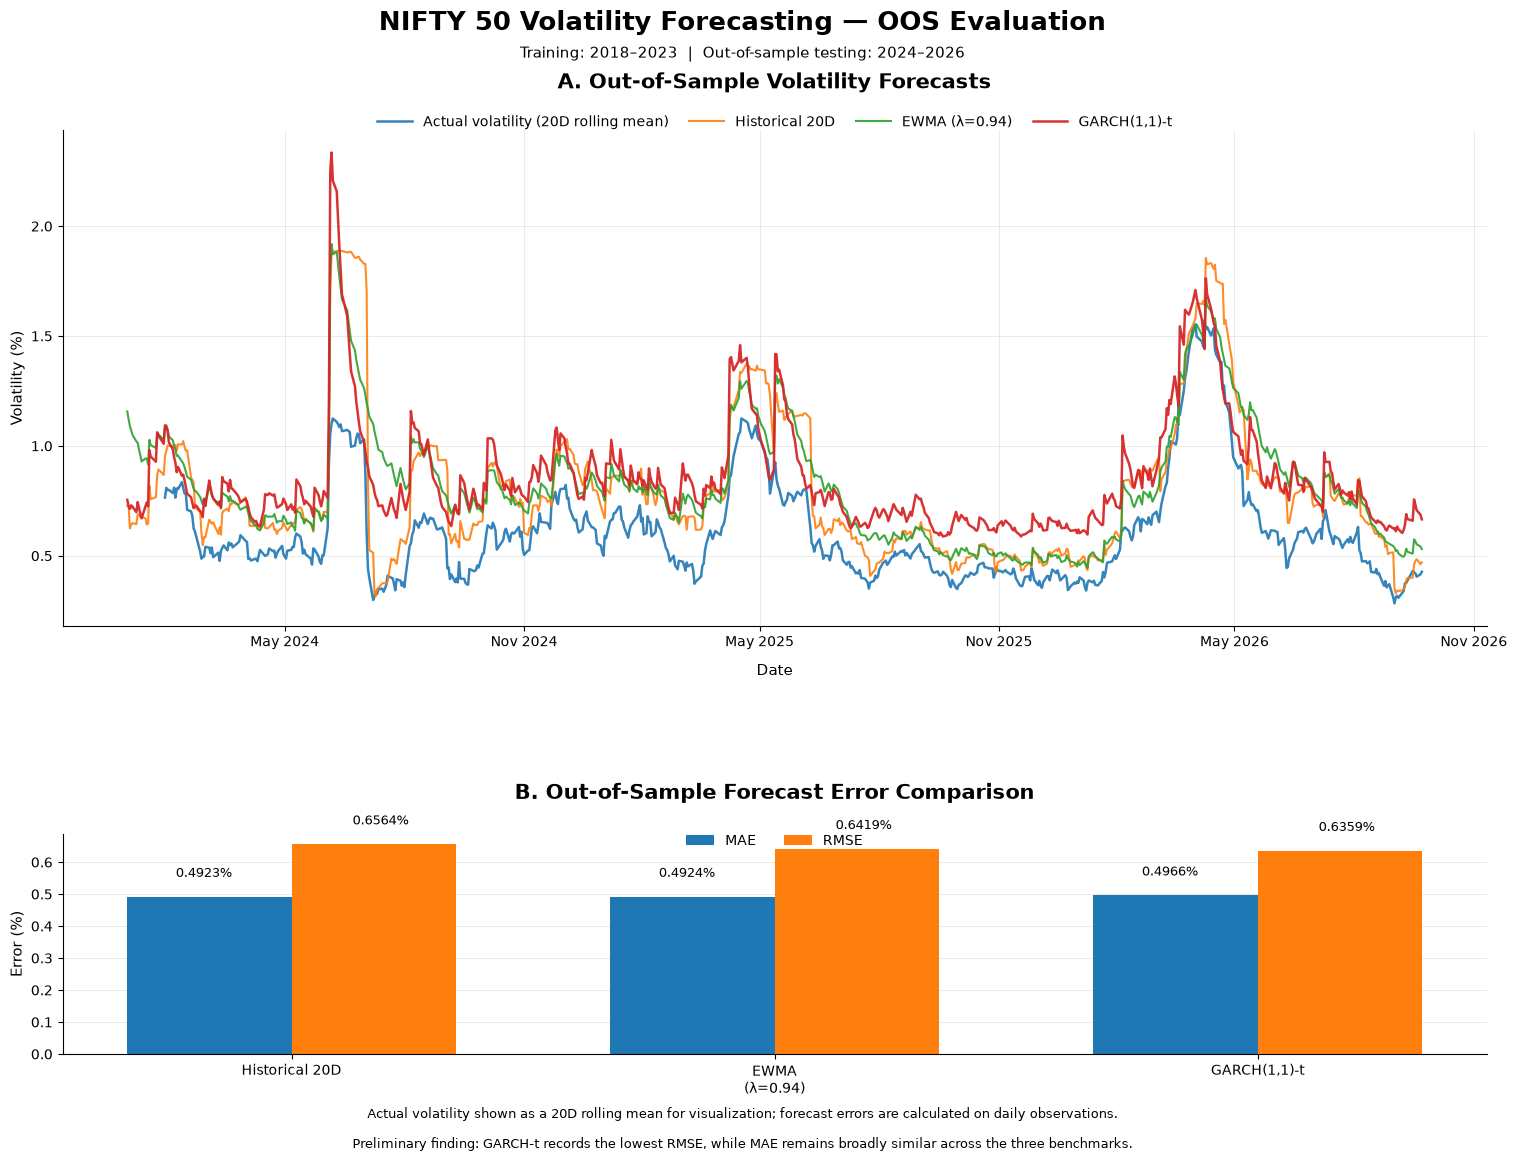

FINAL LINKEDIN FIGURE GENERATED

Observations: 673
Date range: 2024-01-01 → 2026-09-22

OOS PERFORMANCE
Historical 20D : MAE 0.4923% | RMSE 0.6564%
EWMA (λ=0.94)  : MAE 0.4924% | RMSE 0.6419%
GARCH-t        : MAE 0.4966% | RMSE 0.6359%

Saved to:
D:\DS Projects\Adaptive Market Risk Intelligence System\output\figures\research\nifty\nifty_volatility_oos_linkedin_final.png


In [140]:
# ============================================================
# LINKEDIN — FINAL CLEAN OOS VOLATILITY FIGURE
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# ============================================================
# 1. VALIDATE DATA
# ============================================================

required_columns = [
    "Date",
    "Actual_Volatility",
    "Historical_OneStep_Forecast",
    "EWMA_OneStep_Forecast",
    "GARCH_T_OneStep_Forecast",
]

missing_columns = [
    col for col in required_columns
    if col not in linkedin_data.columns
]

if missing_columns:
    raise ValueError(
        f"linkedin_data is missing required columns: {missing_columns}"
    )


# ============================================================
# 2. PREPARE DATA
# ============================================================

plot_data = linkedin_data[
    required_columns
].copy()

plot_data["Date"] = pd.to_datetime(plot_data["Date"])

plot_data = (
    plot_data
    .sort_values("Date")
    .dropna(subset=required_columns)
    .reset_index(drop=True)
)

if plot_data.empty:
    raise ValueError("No valid observations available for plotting.")


# ============================================================
# 3. CONVERT TO PERCENT
# ============================================================

plot_data["Actual_Pct"] = (
    plot_data["Actual_Volatility"] * 100
)

plot_data["Historical_Pct"] = (
    plot_data["Historical_OneStep_Forecast"] * 100
)

plot_data["EWMA_Pct"] = (
    plot_data["EWMA_OneStep_Forecast"] * 100
)

plot_data["GARCH_t_Pct"] = (
    plot_data["GARCH_T_OneStep_Forecast"] * 100
)


# ============================================================
# 4. SMOOTH ACTUAL VOLATILITY FOR DISPLAY ONLY
# ============================================================

plot_data["Actual_20D_Rolling_Pct"] = (
    plot_data["Actual_Pct"]
    .rolling(window=20)
    .mean()
)


# ============================================================
# 5. CALCULATE OOS METRICS
# ============================================================

actual = plot_data["Actual_Volatility"]

historical = plot_data["Historical_OneStep_Forecast"]
ewma = plot_data["EWMA_OneStep_Forecast"]
garch = plot_data["GARCH_T_OneStep_Forecast"]


def calculate_metrics(forecast, actual):

    error = forecast - actual

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))

    return mae * 100, rmse * 100


historical_mae, historical_rmse = calculate_metrics(
    historical,
    actual
)

ewma_mae, ewma_rmse = calculate_metrics(
    ewma,
    actual
)

garch_mae, garch_rmse = calculate_metrics(
    garch,
    actual
)


# ============================================================
# 6. FIGURE
# ============================================================

fig, axes = plt.subplots(
    2,
    1,
    figsize=(16, 12),
    gridspec_kw={
        "height_ratios": [2.25, 1],
        "hspace": 0.58
    }
)


# ============================================================
# PANEL A
# ============================================================

ax = axes[0]


ax.plot(
    plot_data["Date"],
    plot_data["Actual_20D_Rolling_Pct"],
    linewidth=1.8,
    label="Actual volatility (20D rolling mean)",
    alpha=0.90
)

ax.plot(
    plot_data["Date"],
    plot_data["Historical_Pct"],
    linewidth=1.5,
    label="Historical 20D",
    alpha=0.90
)

ax.plot(
    plot_data["Date"],
    plot_data["EWMA_Pct"],
    linewidth=1.5,
    label="EWMA (λ=0.94)",
    alpha=0.90
)

ax.plot(
    plot_data["Date"],
    plot_data["GARCH_t_Pct"],
    linewidth=1.8,
    label="GARCH(1,1)-t",
    alpha=0.95
)


# ------------------------------------------------------------
# Panel A title
# ------------------------------------------------------------

ax.set_title(
    "A. Out-of-Sample Volatility Forecasts",
    fontsize=15,
    fontweight="bold",
    pad=30
)


# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------

ax.set_ylabel(
    "Volatility (%)",
    fontsize=11
)

ax.set_xlabel(
    "Date",
    fontsize=11,
    labelpad=10
)


# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.055),
    ncol=4,
    frameon=False,
    fontsize=10,
    columnspacing=1.5,
    handlelength=2.5
)


# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

ax.grid(
    True,
    alpha=0.25,
    linewidth=0.7
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# ------------------------------------------------------------
# Date formatting
# ------------------------------------------------------------

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=6)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

plt.setp(
    ax.get_xticklabels(),
    rotation=0,
    ha="center"
)


# ============================================================
# PANEL B
# ============================================================

ax = axes[1]


models = [
    "Historical 20D",
    "EWMA\n(λ=0.94)",
    "GARCH(1,1)-t"
]

mae_values = [
    historical_mae,
    ewma_mae,
    garch_mae
]

rmse_values = [
    historical_rmse,
    ewma_rmse,
    garch_rmse
]

x = np.arange(len(models))

width = 0.34


bars_mae = ax.bar(
    x - width / 2,
    mae_values,
    width,
    label="MAE"
)

bars_rmse = ax.bar(
    x + width / 2,
    rmse_values,
    width,
    label="RMSE"
)


# ------------------------------------------------------------
# Panel B title
# ------------------------------------------------------------

ax.set_title(
    "B. Out-of-Sample Forecast Error Comparison",
    fontsize=15,
    fontweight="bold",
    pad=25
)


ax.set_ylabel(
    "Error (%)",
    fontsize=11
)

ax.set_xticks(x)

ax.set_xticklabels(
    models,
    fontsize=10
)


# ------------------------------------------------------------
# Panel B legend
# ------------------------------------------------------------

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.055),
    ncol=2,
    frameon=False,
    fontsize=10
)


# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

ax.grid(
    axis="y",
    alpha=0.25,
    linewidth=0.7
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# ============================================================
# BAR VALUE LABELS — SEPARATE MAE AND RMSE LABEL POSITIONS
# ============================================================

# MAE labels: slightly higher above the bars
for bar in bars_mae:

    height = bar.get_height()

    ax.annotate(
        f"{height:.4f}%",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        xytext=(-4, 12),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )


# RMSE labels: slightly higher and shifted right
for bar in bars_rmse:

    height = bar.get_height()

    ax.annotate(
        f"{height:.4f}%",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        xytext=(5, 12),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

# ============================================================
# MAIN FIGURE TITLE
# ============================================================
# SHORTENED TO KEEP IT ON ONE LINE

fig.text(
    0.5,
    0.975,
    "NIFTY 50 Volatility Forecasting — OOS Evaluation",
    ha="center",
    va="top",
    fontsize=19,
    fontweight="bold"
)


# ============================================================
# SUBTITLE
# ============================================================

fig.text(
    0.5,
    0.945,
    "Training: 2018–2023  |  Out-of-sample testing: 2024–2026",
    ha="center",
    va="top",
    fontsize=11
)


# ============================================================
# RESEARCH NOTES
# ============================================================

fig.text(
    0.5,
    0.055,
    "Actual volatility shown as a 20D rolling mean for visualization; "
    "forecast errors are calculated on daily observations.",
    ha="center",
    va="center",
    fontsize=9
)

fig.text(
    0.5,
    0.030,
    "Preliminary finding: GARCH-t records the lowest RMSE, "
    "while MAE remains broadly similar across the three benchmarks.",
    ha="center",
    va="center",
    fontsize=9
)


# ============================================================
# FINAL LAYOUT
# ============================================================

plt.subplots_adjust(
    top=0.875,
    bottom=0.105,
    left=0.075,
    right=0.965,
    hspace=0.58
)


# ============================================================
# SAVE
# ============================================================

output_path = (
    RESEARCH_NIFTY_DIR
    / "nifty_volatility_oos_linkedin_final.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)


# ============================================================
# DISPLAY
# ============================================================

plt.show()


# ============================================================
# VALIDATION OUTPUT
# ============================================================

print("=" * 65)
print("FINAL LINKEDIN FIGURE GENERATED")
print("=" * 65)

print(f"\nObservations: {len(plot_data):,}")

print(
    f"Date range: "
    f"{plot_data['Date'].min().date()} → "
    f"{plot_data['Date'].max().date()}"
)

print("\nOOS PERFORMANCE")

print(
    f"Historical 20D : "
    f"MAE {historical_mae:.4f}% | "
    f"RMSE {historical_rmse:.4f}%"
)

print(
    f"EWMA (λ=0.94)  : "
    f"MAE {ewma_mae:.4f}% | "
    f"RMSE {ewma_rmse:.4f}%"
)

print(
    f"GARCH-t        : "
    f"MAE {garch_mae:.4f}% | "
    f"RMSE {garch_rmse:.4f}%"
)

print("\nSaved to:")
print(output_path)

In [141]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

returns = clean_nifty["Log_Return"].dropna()

squared_returns = returns ** 2

absolute_returns = returns.abs()

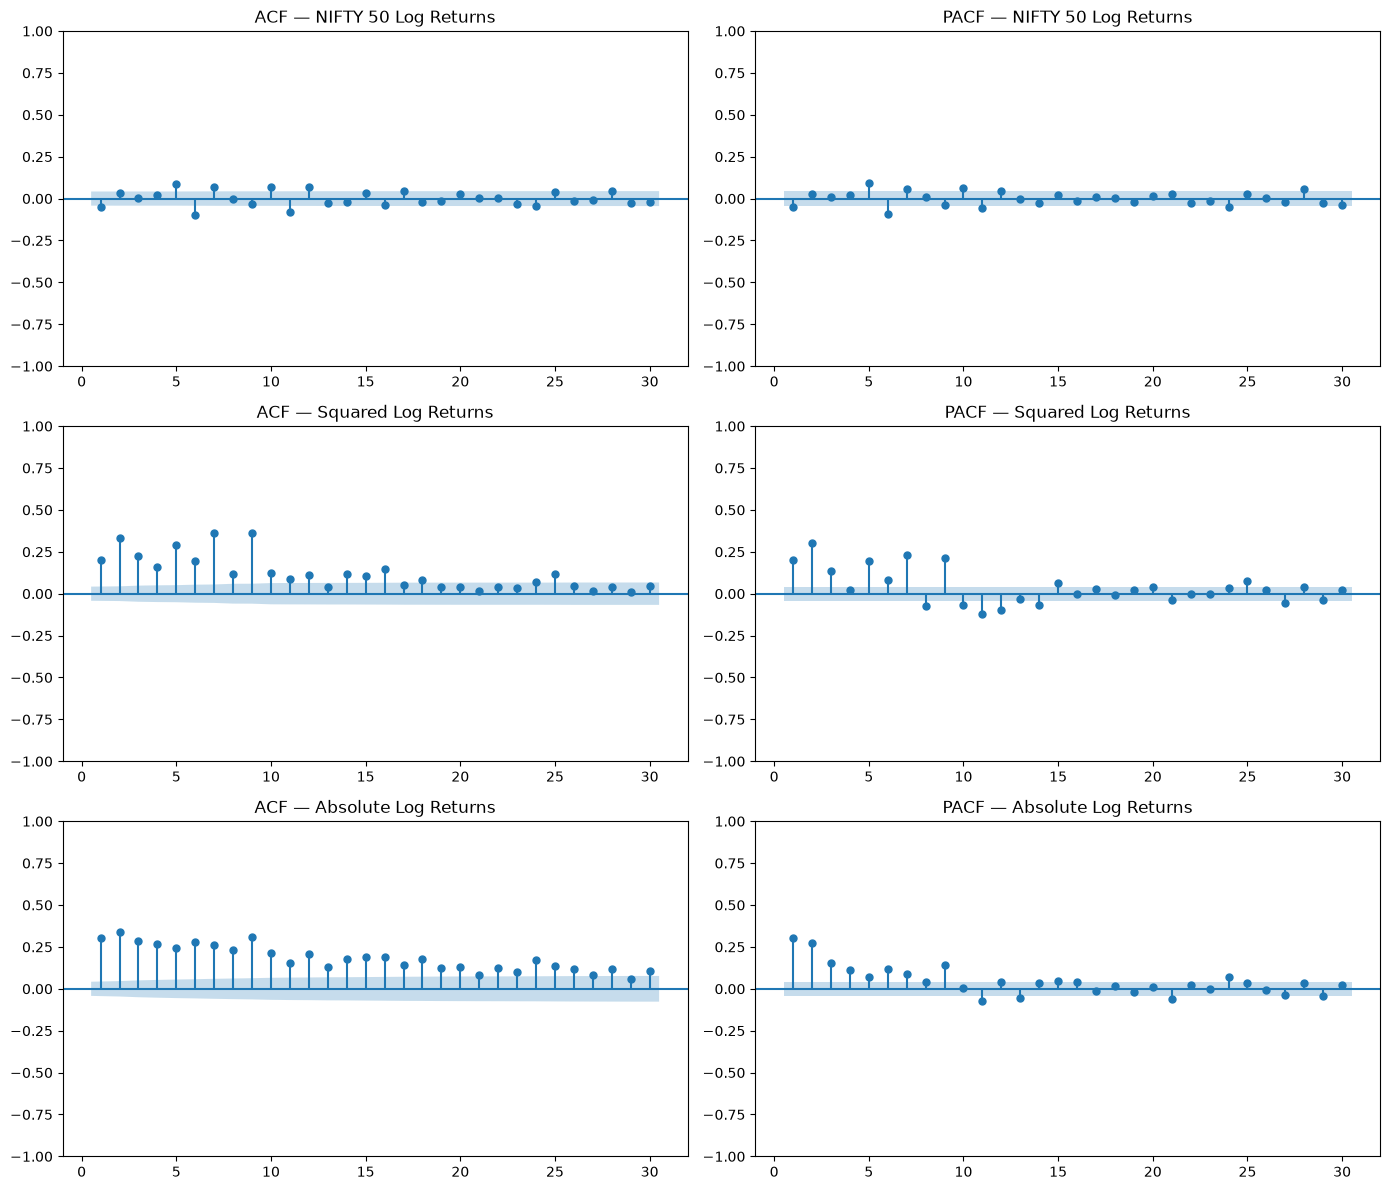

In [142]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

# Returns
plot_acf(
    returns,
    lags=30,
    ax=axes[0, 0],
    zero=False
)

plot_pacf(
    returns,
    lags=30,
    ax=axes[0, 1],
    zero=False,
    method="ywm"
)

axes[0, 0].set_title("ACF — NIFTY 50 Log Returns")
axes[0, 1].set_title("PACF — NIFTY 50 Log Returns")


# Squared returns
plot_acf(
    squared_returns,
    lags=30,
    ax=axes[1, 0],
    zero=False
)

plot_pacf(
    squared_returns,
    lags=30,
    ax=axes[1, 1],
    zero=False,
    method="ywm"
)

axes[1, 0].set_title("ACF — Squared Log Returns")
axes[1, 1].set_title("PACF — Squared Log Returns")


# Absolute returns
plot_acf(
    absolute_returns,
    lags=30,
    ax=axes[2, 0],
    zero=False
)

plot_pacf(
    absolute_returns,
    lags=30,
    ax=axes[2, 1],
    zero=False,
    method="ywm"
)

axes[2, 0].set_title("ACF — Absolute Log Returns")
axes[2, 1].set_title("PACF — Absolute Log Returns")


plt.tight_layout()

plt.savefig(
    RESEARCH_NIFTY_DIR / "nifty_acf_pacf_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 08 — Autocorrelation and Volatility Persistence Analysis

This section examines the temporal dependence structure of NIFTY 50 returns and volatility proxies.

We analyze:
- Log returns
- Squared log returns
- Absolute log returns

Autocorrelation in returns provides evidence about linear serial dependence, while autocorrelation in squared and absolute returns provides evidence of volatility clustering and persistence.

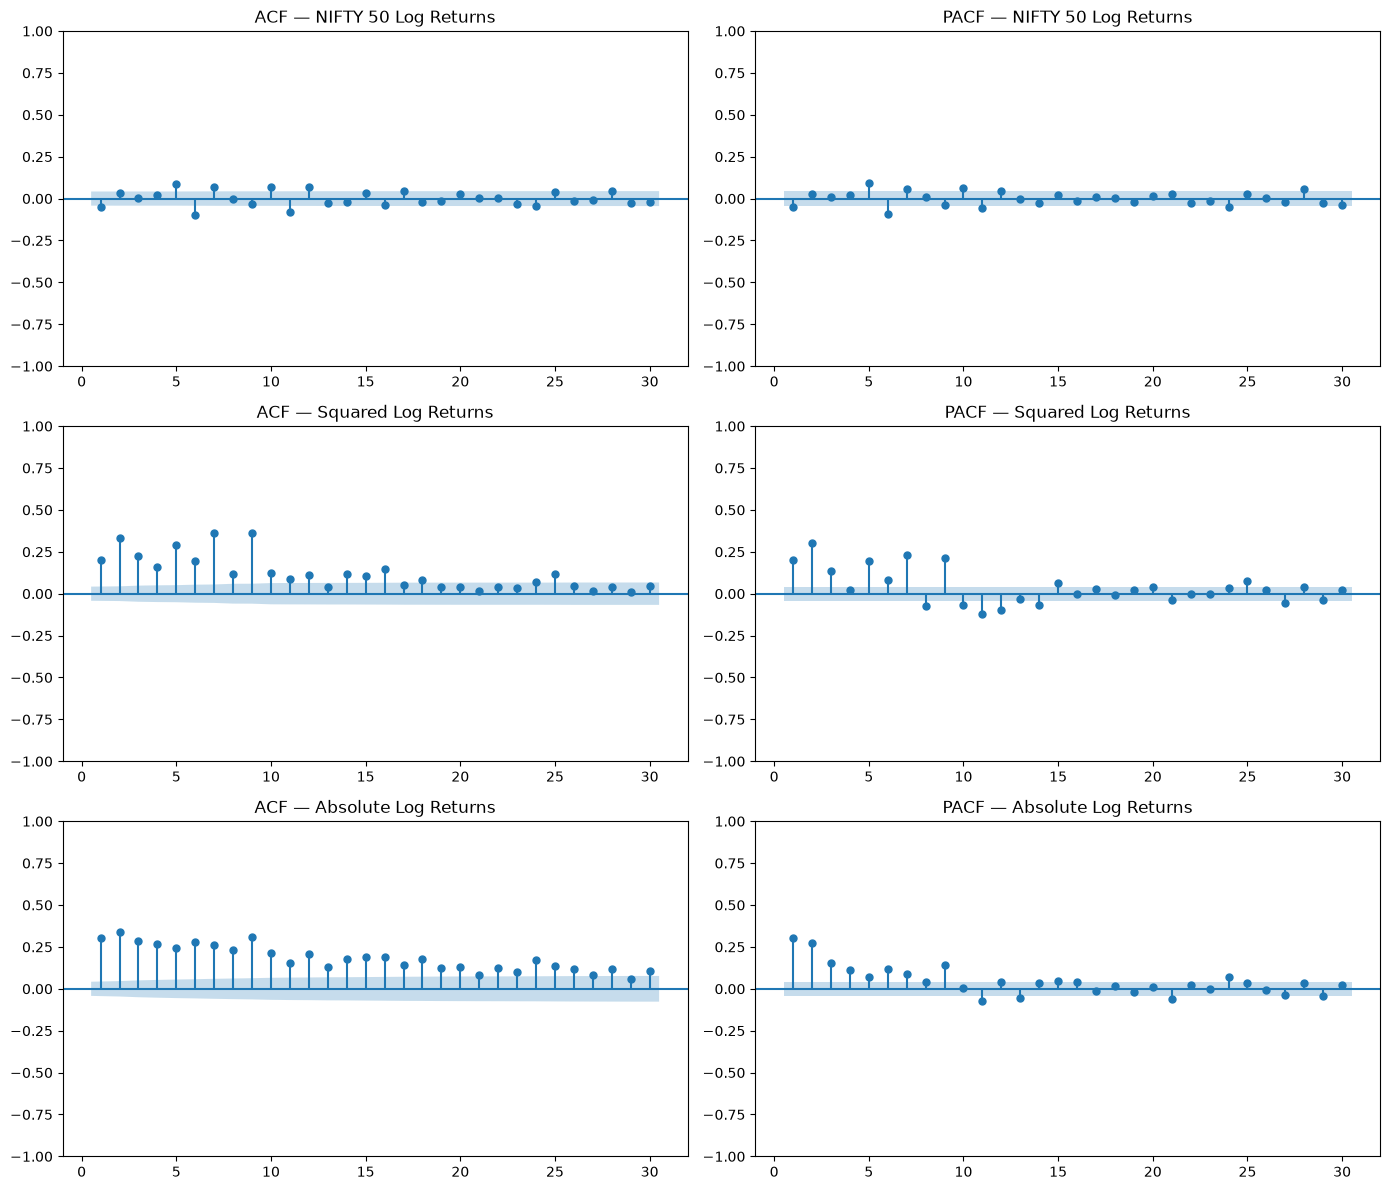

Saved ACF/PACF analysis to:
D:\DS Projects\Adaptive Market Risk Intelligence System\output\figures\research\nifty\nifty_acf_pacf_analysis.png


In [143]:
# [08.01] ACF/PACF — Return and volatility persistence

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

# Prepare series
returns = clean_nifty["Log_Return"].dropna()
squared_returns = returns ** 2
absolute_returns = returns.abs()

# Create figure
fig, axes = plt.subplots(
    3,
    2,
    figsize=(14, 12)
)

# ------------------------------------------------------------
# Log returns
# ------------------------------------------------------------

plot_acf(
    returns,
    lags=30,
    ax=axes[0, 0],
    zero=False
)

plot_pacf(
    returns,
    lags=30,
    ax=axes[0, 1],
    zero=False,
    method="ywm"
)

axes[0, 0].set_title("ACF — NIFTY 50 Log Returns")
axes[0, 1].set_title("PACF — NIFTY 50 Log Returns")


# ------------------------------------------------------------
# Squared log returns
# ------------------------------------------------------------

plot_acf(
    squared_returns,
    lags=30,
    ax=axes[1, 0],
    zero=False
)

plot_pacf(
    squared_returns,
    lags=30,
    ax=axes[1, 1],
    zero=False,
    method="ywm"
)

axes[1, 0].set_title("ACF — Squared Log Returns")
axes[1, 1].set_title("PACF — Squared Log Returns")


# ------------------------------------------------------------
# Absolute log returns
# ------------------------------------------------------------

plot_acf(
    absolute_returns,
    lags=30,
    ax=axes[2, 0],
    zero=False
)

plot_pacf(
    absolute_returns,
    lags=30,
    ax=axes[2, 1],
    zero=False,
    method="ywm"
)

axes[2, 0].set_title("ACF — Absolute Log Returns")
axes[2, 1].set_title("PACF — Absolute Log Returns")


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

plt.tight_layout()

acf_pacf_path = (
    RESEARCH_NIFTY_DIR /
    "nifty_acf_pacf_analysis.png"
)

plt.savefig(
    acf_pacf_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved ACF/PACF analysis to:")
print(acf_pacf_path)

# 09 — ARCH-LM Test for Conditional Heteroskedasticity

The ACF/PACF analysis suggested relatively weak serial dependence in NIFTY 50 returns but stronger persistence in squared and absolute returns.

This section formally tests whether the return series exhibits autoregressive conditional heteroskedasticity (ARCH) effects.

The ARCH-LM test evaluates whether the conditional variance of returns depends systematically on past squared innovations.

### Hypotheses

- **H₀:** There are no ARCH effects; the conditional variance is not systematically related to past squared returns.
- **H₁:** ARCH effects are present; the conditional variance depends on past squared returns.

A statistically significant test result provides evidence that a constant-variance model is inadequate and motivates the use of conditional-volatility models such as ARCH/GARCH.

In [144]:
# [09.01] ARCH-LM test

from statsmodels.stats.diagnostic import het_arch

# Use clean log returns
returns = clean_nifty["Log_Return"].dropna()

# Run ARCH-LM test
arch_lm_result = het_arch(
    returns,
    nlags=10
)

# Extract results
arch_lm_stat = arch_lm_result[0]
arch_lm_pvalue = arch_lm_result[1]
f_stat = arch_lm_result[2]
f_pvalue = arch_lm_result[3]

print("ARCH-LM Test Results")
print("-" * 40)

print(f"LM Statistic : {arch_lm_stat:.4f}")
print(f"LM p-value   : {arch_lm_pvalue:.6f}")
print(f"F Statistic  : {f_stat:.4f}")
print(f"F p-value    : {f_pvalue:.6f}")

ARCH-LM Test Results
----------------------------------------
LM Statistic : 577.2288
LM p-value   : 0.000000
F Statistic  : 78.6506
F p-value    : 0.000000


d:\DS Projects\Adaptive Market Risk Intelligence System\.venv\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [145]:
# [09.02] ARCH-LM interpretation

alpha_level = 0.05

if arch_lm_pvalue < alpha_level:
    print(
        "Conclusion: Reject H0 at the 5% significance level."
    )
    print(
        "There is statistical evidence of ARCH effects "
        "in NIFTY 50 returns."
    )
else:
    print(
        "Conclusion: Fail to reject H0 at the 5% significance level."
    )
    print(
        "There is insufficient statistical evidence of ARCH effects "
        "at this lag length."
    )

Conclusion: Reject H0 at the 5% significance level.
There is statistical evidence of ARCH effects in NIFTY 50 returns.


In [146]:
# [09.01] ARCH-LM test

from statsmodels.stats.diagnostic import het_arch

# Use clean log returns
returns = clean_nifty["Log_Return"].dropna()

# Run ARCH-LM test
arch_lm_result = het_arch(
    returns,
    nlags=10,
    store=False,
    ddof=0
)

# Extract results
arch_lm_stat = arch_lm_result[0]
arch_lm_pvalue = arch_lm_result[1]
f_stat = arch_lm_result[2]
f_pvalue = arch_lm_result[3]

print("ARCH-LM Test Results")
print("-" * 40)

print(f"LM Statistic : {arch_lm_stat:.4f}")
print(f"LM p-value   : {arch_lm_pvalue:.6f}")
print(f"F Statistic  : {f_stat:.4f}")
print(f"F p-value    : {f_pvalue:.6f}")

ARCH-LM Test Results
----------------------------------------
LM Statistic : 577.2288
LM p-value   : 0.000000
F Statistic  : 78.6506
F p-value    : 0.000000


In [147]:
# [09.02] ARCH-LM interpretation

alpha_level = 0.05

if arch_lm_pvalue < alpha_level:
    print("Decision: Reject H0 at the 5% significance level.")
    print(
        "Interpretation: There is strong statistical evidence "
        "of conditional heteroskedasticity (ARCH effects) "
        "in NIFTY 50 log returns."
    )
    print(
        "Implication: A constant-variance model is unlikely "
        "to adequately represent the time-varying volatility "
        "structure of the return series."
    )
else:
    print("Decision: Fail to reject H0 at the 5% significance level.")

Decision: Reject H0 at the 5% significance level.
Interpretation: There is strong statistical evidence of conditional heteroskedasticity (ARCH effects) in NIFTY 50 log returns.
Implication: A constant-variance model is unlikely to adequately represent the time-varying volatility structure of the return series.


# 10 — Asymmetry and Leverage Effect Analysis

The ARCH-LM test established strong evidence of conditional heteroskedasticity in NIFTY 50 returns.

The next question is whether volatility responds differently to positive and negative return shocks.

Standard GARCH models treat shocks symmetrically because the innovation enters the variance equation through its squared value:

εₜ₋₁²

Therefore, positive and negative shocks of equal magnitude have the same direct effect on conditional variance.

This section investigates whether negative shocks have a different relationship with subsequent volatility than positive shocks.

Evidence of asymmetry would motivate the investigation of asymmetric volatility models such as GJR-GARCH and EGARCH.

In [148]:
# [10.01] Positive and negative return shocks

returns = clean_nifty["Log_Return"].dropna().copy()

positive_shocks = returns.clip(lower=0)
negative_shocks = returns.clip(upper=0)

# Magnitude of negative shocks
negative_shock_magnitude = negative_shocks.abs()

print("Positive shocks:")
print(positive_shocks.describe())

print("\nNegative shock magnitudes:")
print(negative_shock_magnitude.describe())

Positive shocks:
count    2149.000000
mean        0.003759
std         0.006164
min         0.000000
25%         0.000000
50%         0.000624
75%         0.005937
max         0.084003
Name: Log_Return, dtype: float64

Negative shock magnitudes:
count    2149.000000
mean        0.003385
std         0.007143
min         0.000000
25%         0.000000
50%         0.000000
75%         0.004508
max         0.139038
Name: Log_Return, dtype: float64


In [149]:
# [10.02] Next-day volatility following positive and negative shocks

asymmetry_data = pd.DataFrame({
    "Return": returns,
    "Next_Day_Abs_Return": returns.abs().shift(-1)
}).dropna()

asymmetry_data["Shock_Type"] = np.where(
    asymmetry_data["Return"] >= 0,
    "Positive",
    "Negative"
)

positive_next_day_vol = asymmetry_data.loc[
    asymmetry_data["Shock_Type"] == "Positive",
    "Next_Day_Abs_Return"
]

negative_next_day_vol = asymmetry_data.loc[
    asymmetry_data["Shock_Type"] == "Negative",
    "Next_Day_Abs_Return"
]

print("Next-day absolute return following positive shocks:")
print(f"Mean: {positive_next_day_vol.mean():.6f}")
print(f"Median: {positive_next_day_vol.median():.6f}")

print("\nNext-day absolute return following negative shocks:")
print(f"Mean: {negative_next_day_vol.mean():.6f}")
print(f"Median: {negative_next_day_vol.median():.6f}")

Next-day absolute return following positive shocks:
Mean: 0.006532
Median: 0.004647

Next-day absolute return following negative shocks:
Mean: 0.007866
Median: 0.005932


In [150]:
# [10.03] Formal asymmetry regression

import statsmodels.api as sm

asymmetry_regression = pd.DataFrame({
    "Next_Day_Abs_Return": returns.abs().shift(-1),
    "Abs_Return": returns.abs(),
    "Negative_Shock": (returns < 0).astype(int)
})

asymmetry_regression["Negative_Interaction"] = (
    asymmetry_regression["Abs_Return"]
    * asymmetry_regression["Negative_Shock"]
)

asymmetry_regression = asymmetry_regression.dropna()

X = asymmetry_regression[
    [
        "Abs_Return",
        "Negative_Interaction"
    ]
]

X = sm.add_constant(X)

y = asymmetry_regression["Next_Day_Abs_Return"]

asymmetry_model = sm.OLS(y, X).fit()

print(asymmetry_model.summary())

                             OLS Regression Results                            
Dep. Variable:     Next_Day_Abs_Return   R-squared:                       0.091
Model:                             OLS   Adj. R-squared:                  0.091
Method:                  Least Squares   F-statistic:                     107.9
Date:                 Sat, 26 Sep 2026   Prob (F-statistic):           2.26e-45
Time:                         22:11:10   Log-Likelihood:                 7434.1
No. Observations:                 2148   AIC:                        -1.486e+04
Df Residuals:                     2145   BIC:                        -1.485e+04
Df Model:                            2                                         
Covariance Type:             nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                 

In [151]:
# [11.01] Imports for asymmetric volatility models

from arch import arch_model
import pandas as pd
import numpy as np

In [152]:
# [11.02] Prepare return series

returns_pct = (
    clean_nifty["Log_Return"]
    .dropna()
    * 100
)

print("Observations:", len(returns_pct))
print("Start:", returns_pct.index.min())
print("End:", returns_pct.index.max())

Observations: 2149
Start: 1
End: 2149


In [153]:
# [11.03] GJR-GARCH(1,1) with Student-t innovations

gjr_model = arch_model(
    returns_pct,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

gjr_result = gjr_model.fit(
    disp="off"
)

print(gjr_result.summary())

                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -2693.91
Distribution:      Standardized Student's t   AIC:                           5399.83
Method:                  Maximum Likelihood   BIC:                           5433.87
                                              No. Observations:                 2149
Date:                      Sat, Sep 26 2026   Df Residuals:                     2148
Time:                              22:11:11   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu  

In [154]:
# [11.04] GJR-GARCH parameter summary

gjr_params = gjr_result.params
gjr_pvalues = gjr_result.pvalues

print("GJR-GARCH parameters")
print("-" * 40)

for parameter in gjr_params.index:
    print(
        f"{parameter:>8} : "
        f"{gjr_params[parameter]:.6f} "
        f"(p={gjr_pvalues[parameter]:.6g})"
    )

GJR-GARCH parameters
----------------------------------------
      mu : 0.053709 (p=0.00154609)
   omega : 0.033338 (p=0.000869892)
alpha[1] : 0.002659 (p=0.834173)
gamma[1] : 0.153255 (p=2.39821e-06)
 beta[1] : 0.876854 (p=2.11617e-198)
      nu : 7.306064 (p=4.89056e-11)


In [155]:
# [11.05] EGARCH(1,1) with Student-t innovations

egarch_model = arch_model(
    returns_pct,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

egarch_result = egarch_model.fit(
    disp="off"
)

print(egarch_result.summary())

                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -2695.14
Distribution:      Standardized Student's t   AIC:                           5402.28
Method:                  Maximum Likelihood   BIC:                           5436.31
                                              No. Observations:                 2149
Date:                      Sat, Sep 26 2026   Df Residuals:                     2148
Time:                              22:11:11   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu  

In [156]:
# [11.06] In-sample model comparison

model_comparison = pd.DataFrame({
    "Model": [
        "GARCH-t",
        "GJR-GARCH-t",
        "EGARCH-t"
    ],
    "LogLik": [
        np.nan,
        gjr_result.loglikelihood,
        egarch_result.loglikelihood
    ],
    "AIC": [
        np.nan,
        gjr_result.aic,
        egarch_result.aic
    ],
    "BIC": [
        np.nan,
        gjr_result.bic,
        egarch_result.bic
    ]
})

print(model_comparison)

         Model       LogLik          AIC          BIC
0      GARCH-t          NaN          NaN          NaN
1  GJR-GARCH-t -2693.914532  5399.829064  5433.865611
2     EGARCH-t -2695.137940  5402.275879  5436.312427


In [157]:
print(garch_t_result.aic)
print(garch_t_result.bic)
print(garch_t_result.loglikelihood)

5447.803258052299
5476.167047535511
-2718.9016290261493


In [158]:
# [12.01] Prepare OOS data with trading-date index

# Make sure Date is the index
if "Date" in train_data.columns:
    train_data = train_data.copy()
    train_data["Date"] = pd.to_datetime(train_data["Date"])
    train_data = train_data.set_index("Date")

if "Date" in test_data.columns:
    test_data = test_data.copy()
    test_data["Date"] = pd.to_datetime(test_data["Date"])
    test_data = test_data.set_index("Date")

# Create return series
train_returns = train_data["Log_Return"].dropna() * 100
test_returns = test_data["Log_Return"].dropna() * 100

print("Training observations:", len(train_returns))
print(
    "Training period:",
    train_returns.index.min(),
    "to",
    train_returns.index.max()
)

print("\nTest observations:", len(test_returns))
print(
    "Test period:",
    test_returns.index.min(),
    "to",
    test_returns.index.max()
)

Training observations: 1476
Training period: 2018-01-03 00:00:00 to 2023-12-29 00:00:00

Test observations: 673
Test period: 2024-01-01 00:00:00 to 2026-09-22 00:00:00


In [159]:
# [12.01A] Verify OOS date structure

print("Training first 5 dates:")
print(train_returns.head())

print("\nTraining last 5 dates:")
print(train_returns.tail())

print("\nTest first 5 dates:")
print(test_returns.head())

print("\nTest last 5 dates:")
print(test_returns.tail())

Training first 5 dates:
Date
2018-01-03    0.009576
2018-01-04    0.588121
2018-01-05    0.513206
2018-01-08    0.611357
2018-01-09    0.126058
Name: Log_Return, dtype: float64

Training last 5 dates:
Date
2023-12-22    0.442910
2023-12-26    0.429763
2023-12-27    0.990355
2023-12-28    0.570756
2023-12-29   -0.217415
Name: Log_Return, dtype: float64

Test first 5 dates:
Date
2024-01-01    0.048306
2024-01-02   -0.350628
2024-01-03   -0.687545
2024-01-04    0.654302
2024-01-05    0.240728
Name: Log_Return, dtype: float64

Test last 5 dates:
Date
2026-09-16    0.427312
2026-09-17    0.228015
2026-09-18    0.325207
2026-09-21    0.290417
2026-09-22   -0.364976
Name: Log_Return, dtype: float64


In [160]:
# [12.02] Train GJR-GARCH-t on the training period

gjr_oos_model = arch_model(
    train_returns,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

gjr_oos_result = gjr_oos_model.fit(
    disp="off"
)

print(gjr_oos_result.summary())

                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -1913.96
Distribution:      Standardized Student's t   AIC:                           3839.92
Method:                  Maximum Likelihood   BIC:                           3871.70
                                              No. Observations:                 1476
Date:                      Sat, Sep 26 2026   Df Residuals:                     1475
Time:                              22:11:11   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

In [161]:
# [12.03] Train EGARCH-t on the training period

egarch_oos_model = arch_model(
    train_returns,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

egarch_oos_result = egarch_oos_model.fit(
    disp="off"
)

print(egarch_oos_result.summary())

                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -1917.20
Distribution:      Standardized Student's t   AIC:                           3846.39
Method:                  Maximum Likelihood   BIC:                           3878.18
                                              No. Observations:                 1476
Date:                      Sat, Sep 26 2026   Df Residuals:                     1475
Time:                              22:11:11   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

In [162]:
# [12.04] One-step-ahead GJR-GARCH-t OOS forecasts

# Combine the chronological return series.
# IMPORTANT:
# Parameters are still estimated only from the training sample.
all_returns_pct = pd.concat(
    [train_returns, test_returns]
)

# Create a model object using the complete chronological index.
# We will NOT refit this model.
gjr_forecast_model = arch_model(
    all_returns_pct,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

# Generate forecasts using the parameters estimated
# exclusively from the training sample.
gjr_forecast_result = gjr_forecast_model.forecast(
    params=gjr_oos_result.params,
    horizon=1,
    start=test_returns.index[0],
    reindex=True
)

# Extract one-step-ahead variance forecasts
gjr_variance = gjr_forecast_result.variance.iloc[:, 0]

# Keep only the OOS period
gjr_variance = gjr_variance.loc[test_returns.index]

# Convert:
# percentage-unit variance → percentage-unit volatility
# then percentage → decimal
gjr_oos_volatility = (
    np.sqrt(gjr_variance) / 100
)

print("Number of GJR-GARCH-t OOS forecasts:", len(gjr_oos_volatility))

print("\nFirst 10 forecasts:")
print(gjr_oos_volatility.head(10))

print("\nLast 5 forecasts:")
print(gjr_oos_volatility.tail())

Number of GJR-GARCH-t OOS forecasts: 673

First 10 forecasts:
Date
2024-01-01    0.006583
2024-01-02    0.006643
2024-01-03    0.007142
2024-01-04    0.006934
2024-01-05    0.006745
2024-01-08    0.007639
2024-01-09    0.007388
2024-01-10    0.007159
2024-01-11    0.006950
2024-01-12    0.006760
Name: h.1, dtype: float64

Last 5 forecasts:
Date
2026-09-16    0.008519
2026-09-17    0.008196
2026-09-18    0.007899
2026-09-21    0.007626
2026-09-22    0.007579
Name: h.1, dtype: float64


In [163]:
# [12.05] One-step-ahead EGARCH-t OOS forecasts

# Combine the chronological return series.
# Parameters remain estimated only on the training sample.
all_returns_pct = pd.concat(
    [train_returns, test_returns]
)

# Create the EGARCH model using the complete chronological index.
# IMPORTANT: This model is NOT refitted.
egarch_forecast_model = arch_model(
    all_returns_pct,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

# Generate one-step-ahead forecasts using parameters
# estimated exclusively from the training period.
egarch_forecast_result = egarch_forecast_model.forecast(
    params=egarch_oos_result.params,
    horizon=1,
    start=test_returns.index[0],
    reindex=True
)

# Extract the one-step-ahead variance forecasts.
egarch_variance = egarch_forecast_result.variance.iloc[:, 0]

# Keep only the OOS testing period.
egarch_variance = egarch_variance.loc[test_returns.index]

# Convert variance → volatility → decimal units.
egarch_oos_volatility = (
    np.sqrt(egarch_variance) / 100
)

print("Number of EGARCH-t OOS forecasts:", len(egarch_oos_volatility))

print("\nFirst 10 forecasts:")
print(egarch_oos_volatility.head(10))

print("\nLast 5 forecasts:")
print(egarch_oos_volatility.tail())

Number of EGARCH-t OOS forecasts: 673

First 10 forecasts:
Date
2024-01-01    0.005899
2024-01-02    0.006179
2024-01-03    0.006909
2024-01-04    0.006681
2024-01-05    0.006374
2024-01-08    0.007424
2024-01-09    0.007035
2024-01-10    0.006723
2024-01-11    0.006388
2024-01-12    0.006318
Name: h.1, dtype: float64

Last 5 forecasts:
Date
2026-09-16    0.009103
2026-09-17    0.008589
2026-09-18    0.008142
2026-09-21    0.007726
2026-09-22    0.007867
Name: h.1, dtype: float64


In [164]:
# [12.05A] Verify EGARCH OOS date alignment

print("Test returns:")
print("Count:", len(test_returns))
print("First:", test_returns.index.min())
print("Last:", test_returns.index.max())

print("\nEGARCH forecasts:")
print("Count:", len(egarch_oos_volatility))
print("First:", egarch_oos_volatility.index.min())
print("Last:", egarch_oos_volatility.index.max())

print("\nDates in EGARCH forecast but not in test returns:")
print(
    egarch_oos_volatility.index.difference(test_returns.index)
)

print("\nDates in test returns but not in EGARCH forecast:")
print(
    test_returns.index.difference(egarch_oos_volatility.index)
)

Test returns:
Count: 673
First: 2024-01-01 00:00:00
Last: 2026-09-22 00:00:00

EGARCH forecasts:
Count: 673
First: 2024-01-01 00:00:00
Last: 2026-09-22 00:00:00

Dates in EGARCH forecast but not in test returns:
DatetimeIndex([], dtype='datetime64[s]', name='Date', freq=None)

Dates in test returns but not in EGARCH forecast:
DatetimeIndex([], dtype='datetime64[s]', name='Date', freq=None)


In [165]:
# [12.05B] Inspect current test_data structure

print("test_data columns:")
print(test_data.columns.tolist())

print("\nLast 10 rows:")
print(test_data.tail(10))

print("\nIndex:")
print(test_data.index.min(), "to", test_data.index.max())

print("\nShape:")
print(test_data.shape)

test_data columns:
['Log_Return', 'Simple_Return', 'GARCH_T_Volatility', 'EWMA_OneStep_Forecast']

Last 10 rows:
            Log_Return  Simple_Return  GARCH_T_Volatility  \
Date                                                        
2026-09-08   -0.006076      -0.006058            0.006169   
2026-09-09   -0.008652      -0.008614            0.006394   
2026-09-10    0.001974       0.001976            0.006894   
2026-09-11   -0.003401      -0.003395            0.006666   
2026-09-15   -0.012017      -0.011945            0.006596   
2026-09-16    0.004273       0.004282            0.007564   
2026-09-17    0.002280       0.002283            0.007340   
2026-09-18    0.003252       0.003257            0.007076   
2026-09-21    0.002904       0.002908            0.006861   
2026-09-22   -0.003650      -0.003643            0.006656   

            EWMA_OneStep_Forecast  
Date                               
2026-09-08               0.004961  
2026-09-09               0.005035  
2026-09-10

In [166]:
# [12.05C] Inspect the final observations in clean_nifty

print("clean_nifty columns:")
print(clean_nifty.columns.tolist())

print("\nLast 10 observations:")
print(clean_nifty.tail(10))

clean_nifty columns:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Simple_Return', 'Log_Return', 'Squared_Return', 'Absolute_Return', 'Rolling_Vol_5D', 'Rolling_Vol_5D_Annualized', 'EWMA_Variance', 'EWMA_Volatility', 'EWMA_Volatility_Annualized', 'GARCH_Volatility', 'GARCH_Volatility_Annualized']

Last 10 observations:
           Date          Open          High           Low         Close  \
2140 2026-09-08  23743.099609  23758.949219  23623.099609  23635.099609   
2141 2026-09-09  23522.050781  23571.550781  23431.500000  23431.500000   
2142 2026-09-10  23446.599609  23494.949219  23380.099609  23477.800781   
2143 2026-09-11  23270.300781  23448.099609  23231.400391  23398.099609   
2144 2026-09-15  23576.150391  23592.849609  23118.599609  23118.599609   
2145 2026-09-16  23201.599609  23284.750000  23116.099609  23217.599609   
2146 2026-09-17  23195.250000  23363.550781  23193.650391  23270.599609   
2147 2026-09-18  23334.699219  23389.150391  23286.599609  23346.400391  

In [167]:
# [12.05D] Verify the final observations in clean_nifty

print(
    clean_nifty[
        ["Log_Return", "Simple_Return"]
    ].tail(10)
)

      Log_Return  Simple_Return
2140   -0.006076      -0.006058
2141   -0.008652      -0.008614
2142    0.001974       0.001976
2143   -0.003401      -0.003395
2144   -0.012017      -0.011945
2145    0.004273       0.004282
2146    0.002280       0.002283
2147    0.003252       0.003257
2148    0.002904       0.002908
2149   -0.003650      -0.003643


In [168]:
# [12.06] Add asymmetric volatility forecasts to test_data

test_data = test_data.copy()

test_data["GJR_GARCH_T_Volatility"] = (
    gjr_oos_volatility.reindex(test_data.index)
)

test_data["EGARCH_T_Volatility"] = (
    egarch_oos_volatility.reindex(test_data.index)
)

print("Test data shape:", test_data.shape)

print("\nColumns:")
print(test_data.columns.tolist())

print("\nMissing values:")
print(
    test_data[
        [
            "GARCH_T_Volatility",
            "EWMA_OneStep_Forecast",
            "GJR_GARCH_T_Volatility",
            "EGARCH_T_Volatility"
        ]
    ].isna().sum()
)

print("\nFirst 5 observations:")
print(test_data.head())

Test data shape: (673, 6)

Columns:
['Log_Return', 'Simple_Return', 'GARCH_T_Volatility', 'EWMA_OneStep_Forecast', 'GJR_GARCH_T_Volatility', 'EGARCH_T_Volatility']

Missing values:
GARCH_T_Volatility        0
EWMA_OneStep_Forecast     0
GJR_GARCH_T_Volatility    0
EGARCH_T_Volatility       0
dtype: int64

First 5 observations:
            Log_Return  Simple_Return  GARCH_T_Volatility  \
Date                                                        
2024-01-01    0.000483       0.000483            0.007547   
2024-01-02   -0.003506      -0.003500            0.007256   
2024-01-03   -0.006875      -0.006852            0.007127   
2024-01-04    0.006543       0.006564            0.007294   
2024-01-05    0.002407       0.002410            0.007232   

            EWMA_OneStep_Forecast  GJR_GARCH_T_Volatility  EGARCH_T_Volatility  
Date                                                                            
2024-01-01               0.011568                0.006583             0.005899  


In [169]:
# [12.07] Five-model OOS volatility evaluation

evaluation_data = test_data.copy()

# One-day realized-volatility proxy
evaluation_data["Actual_Volatility"] = (
    evaluation_data["Log_Return"].abs()
)

# Historical 20-day volatility forecast
evaluation_data["Historical_Volatility_20D"] = (
    pd.concat([
        train_data["Log_Return"],
        test_data["Log_Return"]
    ])
    .rolling(window=20)
    .std()
    .shift(1)
    .loc[test_data.index]
)

# Keep observations where all forecasts are available
evaluation_data = evaluation_data.dropna(
    subset=[
        "Actual_Volatility",
        "Historical_Volatility_20D",
        "EWMA_OneStep_Forecast",
        "GARCH_T_Volatility",
        "GJR_GARCH_T_Volatility",
        "EGARCH_T_Volatility"
    ]
)

models = {
    "Historical 20D": "Historical_Volatility_20D",
    "EWMA (λ=0.94)": "EWMA_OneStep_Forecast",
    "GARCH-t": "GARCH_T_Volatility",
    "GJR-GARCH-t": "GJR_GARCH_T_Volatility",
    "EGARCH-t": "EGARCH_T_Volatility"
}

results = []

actual = evaluation_data["Actual_Volatility"]

for model_name, forecast_column in models.items():

    forecast = evaluation_data[forecast_column]

    mae = np.mean(
        np.abs(actual - forecast)
    )

    rmse = np.sqrt(
        np.mean((actual - forecast) ** 2)
    )

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

oos_results = pd.DataFrame(results)

print("Evaluation observations:", len(evaluation_data))

print("\nOOS evaluation:")
print(oos_results.to_string(index=False))

Evaluation observations: 673

OOS evaluation:
         Model      MAE     RMSE
Historical 20D 0.004923 0.006564
 EWMA (λ=0.94) 0.004924 0.006419
       GARCH-t 0.004966 0.006359
   GJR-GARCH-t 0.004626 0.005818
      EGARCH-t 0.004628 0.005796


In [170]:
# [12.08] Pairwise forecast-loss comparison

# Absolute forecast error for each model
loss_data = pd.DataFrame(index=evaluation_data.index)

for model_name, forecast_column in models.items():
    loss_data[model_name] = (
        evaluation_data["Actual_Volatility"]
        - evaluation_data[forecast_column]
    ).abs()

print("Loss data shape:", loss_data.shape)

print("\nMean absolute forecast error:")
print(
    loss_data.mean()
    .sort_values()
)

Loss data shape: (673, 5)

Mean absolute forecast error:
GJR-GARCH-t       0.004626
EGARCH-t          0.004628
Historical 20D    0.004923
EWMA (λ=0.94)     0.004924
GARCH-t           0.004966
dtype: float64


In [171]:
# [12.09] Check available Diebold-Mariano implementation

import statsmodels

print("statsmodels version:", statsmodels.__version__)

try:
    from statsmodels.stats.diagnostic import acorr_ljungbox
    print("statsmodels diagnostic module available.")
except ImportError:
    print("Diagnostic module unavailable.")

statsmodels version: 0.15.0
statsmodels diagnostic module available.


In [172]:
# [12.10] Diebold-Mariano-style pairwise forecast comparison

import numpy as np
import pandas as pd
from scipy import stats


def dm_test(loss_1, loss_2):
    """
    Diebold-Mariano-style test for equal predictive accuracy.

    H0: The two forecasts have equal expected loss.
    H1: The forecasts have different expected loss.

    Uses a two-sided t-test on the loss differential.
    For the current one-day-ahead forecasts, observations do not
    overlap across forecast horizons.
    """

    loss_1 = pd.Series(loss_1).dropna()
    loss_2 = pd.Series(loss_2).dropna()

    common_index = loss_1.index.intersection(loss_2.index)

    loss_1 = loss_1.loc[common_index]
    loss_2 = loss_2.loc[common_index]

    differential = loss_1 - loss_2

    mean_difference = differential.mean()
    standard_error = differential.std(ddof=1) / np.sqrt(len(differential))

    test_statistic = mean_difference / standard_error
    p_value = 2 * stats.t.sf(
        np.abs(test_statistic),
        df=len(differential) - 1
    )

    return {
        "Mean_Loss_Difference": mean_difference,
        "DM_Statistic": test_statistic,
        "P_Value": p_value,
        "Observations": len(differential)
    }


# Create absolute-error and squared-error losses
absolute_loss = pd.DataFrame(index=evaluation_data.index)
squared_loss = pd.DataFrame(index=evaluation_data.index)

for model_name, forecast_column in models.items():

    forecast_error = (
        evaluation_data["Actual_Volatility"]
        - evaluation_data[forecast_column]
    )

    absolute_loss[model_name] = forecast_error.abs()
    squared_loss[model_name] = forecast_error ** 2


# Model pairs to compare
model_pairs = [
    ("GJR-GARCH-t", "Historical 20D"),
    ("GJR-GARCH-t", "EWMA (λ=0.94)"),
    ("GJR-GARCH-t", "GARCH-t"),
    ("GJR-GARCH-t", "EGARCH-t"),
]


# Absolute-error comparison
dm_mae_results = []

for model_1, model_2 in model_pairs:

    result = dm_test(
        absolute_loss[model_1],
        absolute_loss[model_2]
    )

    result["Model_1"] = model_1
    result["Model_2"] = model_2

    dm_mae_results.append(result)


dm_mae_results = pd.DataFrame(dm_mae_results)

print("Diebold-Mariano-style comparison using absolute error:")
print(
    dm_mae_results[
        [
            "Model_1",
            "Model_2",
            "Mean_Loss_Difference",
            "DM_Statistic",
            "P_Value",
            "Observations"
        ]
    ].to_string(index=False)
)

Diebold-Mariano-style comparison using absolute error:


    Model_1        Model_2  Mean_Loss_Difference  DM_Statistic      P_Value  Observations
GJR-GARCH-t Historical 20D             -0.000297     -3.320545 9.470043e-04           673
GJR-GARCH-t  EWMA (λ=0.94)             -0.000298     -4.158207 3.623024e-05           673
GJR-GARCH-t        GARCH-t             -0.000340     -7.235234 1.271671e-12           673
GJR-GARCH-t       EGARCH-t             -0.000002     -0.061526 9.509589e-01           673


In [173]:
# [12.11] Diebold-Mariano-style comparison using squared error

dm_rmse_results = []

for model_1, model_2 in model_pairs:

    result = dm_test(
        squared_loss[model_1],
        squared_loss[model_2]
    )

    result["Model_1"] = model_1
    result["Model_2"] = model_2

    dm_rmse_results.append(result)


dm_rmse_results = pd.DataFrame(dm_rmse_results)

print("Diebold-Mariano-style comparison using squared error:")
print(
    dm_rmse_results[
        [
            "Model_1",
            "Model_2",
            "Mean_Loss_Difference",
            "DM_Statistic",
            "P_Value",
            "Observations"
        ]
    ].to_string(index=False)
)

Diebold-Mariano-style comparison using squared error:
    Model_1        Model_2  Mean_Loss_Difference  DM_Statistic  P_Value  Observations
GJR-GARCH-t Historical 20D         -9.238013e-06     -3.750714 0.000192           673
GJR-GARCH-t  EWMA (λ=0.94)         -7.353685e-06     -3.320333 0.000948           673
GJR-GARCH-t        GARCH-t         -6.596034e-06     -3.586401 0.000360           673
GJR-GARCH-t       EGARCH-t          2.479523e-07      0.326160 0.744405           673


In [174]:
# [12.12] HAC-adjusted forecast loss comparison

from statsmodels.stats.sandwich_covariance import cov_hac
import statsmodels.api as sm
from scipy import stats
import numpy as np


def dm_test_hac(loss_1, loss_2, maxlags=5):
    """
    HAC-adjusted Diebold-Mariano-style test.

    H0:
        Mean loss differential = 0

    H1:
        Mean loss differential != 0

    The loss differential is:
        d_t = loss_1,t - loss_2,t

    HAC/Newey-West covariance is used to allow for
    serial dependence in the loss differential.
    """

    loss_1 = pd.Series(loss_1).dropna()
    loss_2 = pd.Series(loss_2).dropna()

    common_index = loss_1.index.intersection(loss_2.index)

    loss_1 = loss_1.loc[common_index]
    loss_2 = loss_2.loc[common_index]

    differential = (loss_1 - loss_2).dropna()

    # Regression of loss differential on a constant
    X = np.ones((len(differential), 1))
    model = sm.OLS(differential.values, X).fit()

    # HAC covariance matrix
    hac_cov = cov_hac(
        model,
        nlags=maxlags
    )

    mean_difference = model.params[0]
    standard_error = np.sqrt(hac_cov[0, 0])

    test_statistic = mean_difference / standard_error

    p_value = 2 * stats.t.sf(
        np.abs(test_statistic),
        df=len(differential) - 1
    )

    return {
        "Mean_Loss_Difference": mean_difference,
        "DM_HAC_Statistic": test_statistic,
        "P_Value": p_value,
        "Observations": len(differential)
    }


# ---------------------------------------------------------
# HAC comparison using absolute-error loss
# ---------------------------------------------------------

hac_mae_results = []

for model_1, model_2 in model_pairs:

    result = dm_test_hac(
        absolute_loss[model_1],
        absolute_loss[model_2],
        maxlags=5
    )

    result["Model_1"] = model_1
    result["Model_2"] = model_2

    hac_mae_results.append(result)


hac_mae_results = pd.DataFrame(hac_mae_results)


print("HAC-adjusted comparison using absolute-error loss:")
print(
    hac_mae_results[
        [
            "Model_1",
            "Model_2",
            "Mean_Loss_Difference",
            "DM_HAC_Statistic",
            "P_Value",
            "Observations"
        ]
    ].to_string(index=False)
)

HAC-adjusted comparison using absolute-error loss:
    Model_1        Model_2  Mean_Loss_Difference  DM_HAC_Statistic      P_Value  Observations
GJR-GARCH-t Historical 20D             -0.000297         -2.163145 3.088192e-02           673
GJR-GARCH-t  EWMA (λ=0.94)             -0.000298         -3.013920 2.676027e-03           673
GJR-GARCH-t        GARCH-t             -0.000340         -5.953850 4.220209e-09           673
GJR-GARCH-t       EGARCH-t             -0.000002         -0.034828 9.722269e-01           673


In [175]:
# [12.13] Equal-weight GJR + EGARCH volatility ensemble

evaluation_data["GJR_EGARCH_Ensemble"] = (
    0.5 * evaluation_data["GJR_GARCH_T_Volatility"]
    + 0.5 * evaluation_data["EGARCH_T_Volatility"]
)

ensemble_mae = np.mean(
    np.abs(
        evaluation_data["Actual_Volatility"]
        - evaluation_data["GJR_EGARCH_Ensemble"]
    )
)

ensemble_rmse = np.sqrt(
    np.mean(
        (
            evaluation_data["Actual_Volatility"]
            - evaluation_data["GJR_EGARCH_Ensemble"]
        ) ** 2
    )
)

print("GJR + EGARCH Equal-Weight Ensemble")
print("----------------------------------")
print(f"MAE :  {ensemble_mae:.6f}")
print(f"RMSE: {ensemble_rmse:.6f}")

print("\nPercentage:")
print(f"MAE :  {ensemble_mae * 100:.4f}%")
print(f"RMSE: {ensemble_rmse * 100:.4f}%")

GJR + EGARCH Equal-Weight Ensemble
----------------------------------
MAE :  0.004623
RMSE: 0.005793

Percentage:
MAE :  0.4623%
RMSE: 0.5793%


In [176]:
# [12.14] HAC-adjusted ensemble comparison

ensemble_loss_absolute = (
    evaluation_data["Actual_Volatility"]
    - evaluation_data["GJR_EGARCH_Ensemble"]
).abs()

ensemble_loss_squared = (
    evaluation_data["Actual_Volatility"]
    - evaluation_data["GJR_EGARCH_Ensemble"]
) ** 2


ensemble_comparisons = [
    ("GJR + EGARCH", "Historical 20D", "Historical_Volatility_20D"),
    ("GJR + EGARCH", "EWMA (λ=0.94)", "EWMA_OneStep_Forecast"),
    ("GJR + EGARCH", "GARCH-t", "GARCH_T_Volatility"),
    ("GJR + EGARCH", "GJR-GARCH-t", "GJR_GARCH_T_Volatility"),
    ("GJR + EGARCH", "EGARCH-t", "EGARCH_T_Volatility"),
]


ensemble_hac_results = []

for ensemble_name, comparison_name, comparison_column in ensemble_comparisons:

    comparison_loss = (
        evaluation_data["Actual_Volatility"]
        - evaluation_data[comparison_column]
    ).abs()

    result = dm_test_hac(
        ensemble_loss_absolute,
        comparison_loss,
        maxlags=5
    )

    result["Model_1"] = ensemble_name
    result["Model_2"] = comparison_name

    ensemble_hac_results.append(result)


ensemble_hac_results = pd.DataFrame(ensemble_hac_results)

print("HAC-adjusted ensemble comparison using absolute-error loss:")
print(
    ensemble_hac_results[
        [
            "Model_1",
            "Model_2",
            "Mean_Loss_Difference",
            "DM_HAC_Statistic",
            "P_Value",
            "Observations"
        ]
    ].to_string(index=False)
)

HAC-adjusted ensemble comparison using absolute-error loss:
     Model_1        Model_2  Mean_Loss_Difference  DM_HAC_Statistic      P_Value  Observations
GJR + EGARCH Historical 20D             -0.000300         -2.022928 4.347601e-02           673
GJR + EGARCH  EWMA (λ=0.94)             -0.000301         -2.814452 5.029038e-03           673
GJR + EGARCH        GARCH-t             -0.000343         -5.348343 1.218215e-07           673
GJR + EGARCH    GJR-GARCH-t             -0.000003         -0.109904 9.125182e-01           673
GJR + EGARCH       EGARCH-t             -0.000005         -0.182001 8.556367e-01           673


## Forecast Combination — Research Plan

**Why?**  
GJR-GARCH-t and EGARCH-t currently give the best OOS results. I will test whether combining different forecasts can improve stability and accuracy.

**Methods to test:**
- Equal weights
- Linear rank weights
- Reciprocal rank weights
- Exponential rank weights
- Inverse-loss weights
- Softmax weights

**Rules:**
- Determine weights using past/validation data only.
- Do not use final OOS results to choose weights.
- Compare against individual models and simple benchmarks.
- Evaluate using MAE, RMSE and HAC-adjusted tests.

**Current result:**  
GJR + EGARCH equal-weight ensemble:
- MAE = **0.4623%**
- RMSE = **0.5793%**

The improvement is small and not yet statistically significant.

**Next:**  
Test the mathematical weighting methods on a separate validation period, then evaluate the chosen weights on the final OOS period.

### 12.15 Forecast Combination — Equal Weighting

The GJR-GARCH-t and EGARCH-t models produce very similar forecasts but may capture volatility differently.

To test whether combining them improves forecast robustness, I first use a simple equal-weight ensemble.

Each model receives the same weight:

**Combined Forecast = 0.5 × GJR-GARCH-t + 0.5 × EGARCH-t**

This method does not use model performance to assign weights, making it a simple baseline for forecast combination.

I will compare the ensemble with the individual models using MAE and RMSE.

In [177]:
evaluation_data["GJR_EGARCH_Ensemble"] = (
    0.5 * evaluation_data["GJR_GARCH_T_Volatility"]
    + 0.5 * evaluation_data["EGARCH_T_Volatility"]
)

ensemble_mae = np.mean(
    np.abs(
        evaluation_data["Actual_Volatility"]
        - evaluation_data["GJR_EGARCH_Ensemble"]
    )
)

ensemble_rmse = np.sqrt(
    np.mean(
        (
            evaluation_data["Actual_Volatility"]
            - evaluation_data["GJR_EGARCH_Ensemble"]
        ) ** 2
    )
)

print(f"Equal-weight Ensemble MAE:  {ensemble_mae:.6f}")
print(f"Equal-weight Ensemble RMSE: {ensemble_rmse:.6f}")

Equal-weight Ensemble MAE:  0.004623
Equal-weight Ensemble RMSE: 0.005793


### Result and Interpretation

The equal-weight ensemble produced:

- MAE: **0.4623%**
- RMSE: **0.5793%**

The ensemble performs slightly differently from the individual GJR-GARCH-t and EGARCH-t models. However, numerical improvement alone does not establish that the combination is statistically superior.

**Decision:** Keep the equal-weight ensemble as a baseline and test more structured weighting methods next.

### 12.16 Forecast Combination — Linear Rank Weighting

Equal weighting gives every model the same importance.

Here, models are ranked by their validation performance. Better-ranked models receive larger weights.

For 5 models, the weights are proportional to:

**5 : 4 : 3 : 2 : 1**

The weights are then normalized so that their total equals 1.

The weights will be determined using validation data, not the final OOS test period.

In [178]:
print(evaluation_data.columns)
print(evaluation_data.shape)


Index(['Log_Return', 'Simple_Return', 'GARCH_T_Volatility',
       'EWMA_OneStep_Forecast', 'GJR_GARCH_T_Volatility',
       'EGARCH_T_Volatility', 'Actual_Volatility', 'Historical_Volatility_20D',
       'GJR_EGARCH_Ensemble'],
      dtype='str')
(673, 9)


### 12.16 Linear Rank Weighting — Validation Setup

To assign different weights to the models, their past forecasting performance must first be compared.

The 2018–2023 training period will therefore be divided into:

- Training period: 2018–2021
- Validation period: 2022–2023
- Final OOS test period: 2024–2026

Model performance on the validation period will determine the ranking and weights.

The final 2024–2026 OOS period will remain untouched until the weights are fixed.

### 12.16.1 Generate Validation Forecasts

The 2018–2021 data will be used to estimate the model parameters.

The models will then generate forecasts for 2022–2023.

These forecasts will be evaluated against the actual 2022–2023 volatility and used only to determine model ranking and combination weights.

In [179]:
# ---------------------------------------------------------
# Validation period: 2022-01-01 to 2023-12-31
# Final OOS period: 2024-01-01 onward
# ---------------------------------------------------------

validation_train = clean_nifty[
    clean_nifty["Date"] < "2022-01-01"
].copy()

validation_data = clean_nifty[
    (clean_nifty["Date"] >= "2022-01-01") &
    (clean_nifty["Date"] < "2024-01-01")
].copy()

print("Model estimation period:")
print(validation_train["Date"].min(), "to", validation_train["Date"].max())

print("\nValidation period:")
print(validation_data["Date"].min(), "to", validation_data["Date"].max())

print("\nObservations:")
print("Estimation:", len(validation_train))
print("Validation:", len(validation_data))

Model estimation period:
2018-01-02 00:00:00 to 2021-12-31 00:00:00

Validation period:
2022-01-03 00:00:00 to 2023-12-29 00:00:00

Observations:
Estimation: 984
Validation: 493


### 12.16.2 Historical Volatility and EWMA Validation Forecasts

Before fitting the GARCH-family models, two simple volatility methods are generated as benchmark forecasts.

- Historical volatility uses the previous 20 trading days.
- EWMA uses a decay factor of 0.94, giving greater importance to recent returns.

These forecasts provide simple benchmarks against which the more complex models can be evaluated.

In [180]:
# ---------------------------------------------------------
# Historical 20D + EWMA validation forecasts
# ---------------------------------------------------------

all_returns = clean_nifty.set_index("Date")["Log_Return"]

validation_forecasts = validation_data.set_index("Date")[
    ["Log_Return"]
].copy()

# Actual one-day volatility proxy
validation_forecasts["Actual_Volatility"] = (
    validation_forecasts["Log_Return"].abs()
)


# ---------------------------------------------------------
# Historical 20D volatility
# ---------------------------------------------------------

historical_20d = (
    all_returns
    .rolling(window=20)
    .std()
    .shift(1)
)

validation_forecasts["Historical_20D"] = (
    historical_20d.reindex(validation_forecasts.index)
)


# ---------------------------------------------------------
# EWMA volatility
# ---------------------------------------------------------

lambda_ewma = 0.94

# Start from the variance of the estimation period
estimation_returns = all_returns[
    all_returns.index < pd.Timestamp("2022-01-01")
]

previous_variance = estimation_returns.var()

ewma_validation = []

for date in validation_forecasts.index:

    # Forecast variance for this date
    forecast_variance = (
        lambda_ewma * previous_variance
        + (1 - lambda_ewma) *
        estimation_returns.iloc[-1] ** 2
    )

    ewma_validation.append(np.sqrt(forecast_variance))

    # After observing the current validation return,
    # update the variance for the next day
    current_return = all_returns.loc[date]

    previous_variance = forecast_variance

    estimation_returns = pd.concat([
        estimation_returns,
        pd.Series([current_return], index=[date])
    ])

validation_forecasts["EWMA"] = ewma_validation


# ---------------------------------------------------------
# Remove observations without enough historical data
# ---------------------------------------------------------

validation_forecasts = validation_forecasts.dropna()

print(validation_forecasts.head())

print("\nShape:", validation_forecasts.shape)

print("\nMissing values:")
print(validation_forecasts.isna().sum())

            Log_Return  Actual_Volatility  Historical_20D      EWMA
Date                                                               
2022-01-03    0.015532           0.015532        0.010488  0.012499
2022-01-04    0.010135           0.010135        0.010187  0.012701
2022-01-05    0.006717           0.006717        0.009880  0.012562
2022-01-06   -0.010056           0.010056        0.009305  0.012290
2022-01-07    0.003757           0.003757        0.009634  0.012167

Shape: (493, 4)

Missing values:
Log_Return           0
Actual_Volatility    0
Historical_20D       0
EWMA                 0
dtype: int64


### 12.16.3 Validation Benchmark Check

The Historical 20D and EWMA forecasts were successfully generated for all 493 validation observations.

Both benchmarks are available without missing values and will be used as reference models for evaluating the GARCH-family forecasts.

The validation dataset is now ready for the next stage: GARCH-t, GJR-GARCH-t and EGARCH-t.

### 12.16.4 GARCH-t Validation Forecast

A GARCH(1,1) model with Student-t innovations is fitted using only the 2018–2021 estimation period.

The Student-t distribution is used because financial returns can have heavier tails than a normal distribution.

The fitted model will then generate one-step-ahead volatility forecasts for the 2022–2023 validation period.

In [181]:
# ---------------------------------------------------------
# GARCH(1,1)-t validation model
# ---------------------------------------------------------

from arch import arch_model
import numpy as np

# Estimation-period returns
train_returns_validation = (
    validation_train["Log_Return"] * 100
)

# Remove non-finite observations required by the model
train_returns_validation = train_returns_validation[
    np.isfinite(train_returns_validation)
]

print("Observations used:", len(train_returns_validation))
print("Missing values:", train_returns_validation.isna().sum())
print("Infinite values:", np.isinf(train_returns_validation).sum())


# Fit GARCH(1,1)-t
garch_validation_model = arch_model(
    train_returns_validation,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=0,
    q=1,
    dist="t",
    rescale=False
)

garch_validation_result = garch_validation_model.fit(
    disp="off"
)

print(garch_validation_result.summary())

Observations used: 983
Missing values: 0
Infinite values: 0
                        Constant Mean - GARCH Model Results                         
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -1339.10
Distribution:      Standardized Student's t   AIC:                           2688.20
Method:                  Maximum Likelihood   BIC:                           2712.65
                                              No. Observations:                  983
Date:                      Sat, Sep 26 2026   Df Residuals:                      982
Time:                              22:11:12   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
-------------------------

### 12.16.5 Generate GARCH-t Validation Forecasts

The GARCH-t model estimated on 2018–2021 will now be used to generate one-step-ahead volatility forecasts for every trading day in 2022–2023.

After each day's return is observed, the variance is updated before forecasting the next day. This preserves the chronological information available to the model and avoids look-ahead bias.

In [182]:
# ---------------------------------------------------------
# Recursive one-step-ahead GARCH-t forecasts
# ---------------------------------------------------------

mu = garch_validation_result.params["mu"]
omega = garch_validation_result.params["omega"]
alpha = garch_validation_result.params["alpha[1]"]
beta = garch_validation_result.params["beta[1]"]

# Last known return and variance from the estimation period
last_return = train_returns_validation.iloc[-1]

previous_variance = (
    garch_validation_result
    .conditional_volatility
    .iloc[-1] ** 2
)

garch_validation_forecasts = []

for date in validation_forecasts.index:

    # Forecast variance for the current date
    forecast_variance = (
        omega
        + alpha * (last_return - mu) ** 2
        + beta * previous_variance
    )

    forecast_volatility = np.sqrt(forecast_variance)

    # Convert percentage units back to decimal units
    garch_validation_forecasts.append(
        forecast_volatility / 100
    )

    # Observe today's return and update for next day
    current_return = (
        validation_forecasts.loc[date, "Log_Return"] * 100
    )

    previous_variance = forecast_variance
    last_return = current_return


validation_forecasts["GARCH_t"] = garch_validation_forecasts

print(
    validation_forecasts[
        [
            "Log_Return",
            "Actual_Volatility",
            "Historical_20D",
            "EWMA",
            "GARCH_t"
        ]
    ].head()
)

print("\nMissing values:")
print(validation_forecasts.isna().sum())

            Log_Return  Actual_Volatility  Historical_20D      EWMA   GARCH_t
Date                                                                         
2022-01-03    0.015532           0.015532        0.010488  0.012499  0.009016
2022-01-04    0.010135           0.010135        0.010187  0.012701  0.009811
2022-01-05    0.006717           0.006717        0.009880  0.012562  0.009765
2022-01-06   -0.010056           0.010056        0.009305  0.012290  0.009442
2022-01-07    0.003757           0.003757        0.009634  0.012167  0.009682

Missing values:
Log_Return           0
Actual_Volatility    0
Historical_20D       0
EWMA                 0
GARCH_t              0
dtype: int64


### 12.16.6 GARCH-t Validation Result

The GARCH-t model successfully generated one-step-ahead forecasts for all 493 validation observations.

The forecasts will be compared with the Historical 20D and EWMA benchmarks, and later with the asymmetric GARCH models.

**Next:** Generate GJR-GARCH-t validation forecasts to test whether asymmetric volatility responses improve forecasting performance.

### 12.16.7 GJR-GARCH-t Validation Forecast

GJR-GARCH-t extends the standard GARCH model by allowing negative and positive shocks to have different effects on future volatility.

The model is estimated using only 2018–2021 data and then used to generate one-step-ahead forecasts for 2022–2023.

In [183]:
# ---------------------------------------------------------
# GJR-GARCH(1,1)-t validation model
# ---------------------------------------------------------

gjr_validation_model = arch_model(
    train_returns_validation,
    mean="Constant",
    vol="GARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

gjr_validation_result = gjr_validation_model.fit(
    disp="off"
)

print(gjr_validation_result.summary())

                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -1322.28
Distribution:      Standardized Student's t   AIC:                           2656.55
Method:                  Maximum Likelihood   BIC:                           2685.89
                                              No. Observations:                  983
Date:                      Sat, Sep 26 2026   Df Residuals:                      982
Time:                              22:11:12   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

### 12.16.8 Generate GJR-GARCH-t Validation Forecasts

The fitted GJR-GARCH-t model will now generate one-step-ahead forecasts for 2022–2023.

The forecast is updated sequentially after each observed return, preserving the chronological information available at each point in time.

In [184]:
# ---------------------------------------------------------
# Recursive one-step-ahead GJR-GARCH-t forecasts
# ---------------------------------------------------------

mu = gjr_validation_result.params["mu"]
omega = gjr_validation_result.params["omega"]
alpha = gjr_validation_result.params["alpha[1]"]
gamma = gjr_validation_result.params["gamma[1]"]
beta = gjr_validation_result.params["beta[1]"]

last_return = train_returns_validation.iloc[-1]

previous_variance = (
    gjr_validation_result
    .conditional_volatility
    .iloc[-1] ** 2
)

gjr_validation_forecasts = []

for date in validation_forecasts.index:

    # Indicator for a negative previous shock
    negative_shock = 1 if last_return < mu else 0

    forecast_variance = (
        omega
        + alpha * (last_return - mu) ** 2
        + gamma * negative_shock * (last_return - mu) ** 2
        + beta * previous_variance
    )

    forecast_volatility = np.sqrt(forecast_variance)

    # Convert percentage units back to decimal units
    gjr_validation_forecasts.append(
        forecast_volatility / 100
    )

    # Observe today's return and update the model
    current_return = (
        validation_forecasts.loc[date, "Log_Return"] * 100
    )

    previous_variance = forecast_variance
    last_return = current_return


validation_forecasts["GJR_GARCH_t"] = (
    gjr_validation_forecasts
)

print(
    validation_forecasts[
        [
            "Log_Return",
            "Actual_Volatility",
            "Historical_20D",
            "EWMA",
            "GARCH_t",
            "GJR_GARCH_t"
        ]
    ].head()
)

print("\nMissing values:")
print(validation_forecasts.isna().sum())

            Log_Return  Actual_Volatility  Historical_20D      EWMA   GARCH_t  \
Date                                                                            
2022-01-03    0.015532           0.015532        0.010488  0.012499  0.009016   
2022-01-04    0.010135           0.010135        0.010187  0.012701  0.009811   
2022-01-05    0.006717           0.006717        0.009880  0.012562  0.009765   
2022-01-06   -0.010056           0.010056        0.009305  0.012290  0.009442   
2022-01-07    0.003757           0.003757        0.009634  0.012167  0.009682   

            GJR_GARCH_t  
Date                     
2022-01-03     0.009443  
2022-01-04     0.009035  
2022-01-05     0.008660  
2022-01-06     0.008317  
2022-01-07     0.009159  

Missing values:
Log_Return           0
Actual_Volatility    0
Historical_20D       0
EWMA                 0
GARCH_t              0
GJR_GARCH_t          0
dtype: int64


### 12.16.9 GJR-GARCH-t Validation Result

The GJR-GARCH-t model successfully generated forecasts for all 493 validation observations.

The model allows negative and positive shocks to affect future volatility differently.

The final validation comparison will include Historical 20D, EWMA, GARCH-t, GJR-GARCH-t and EGARCH-t.

### 12.16.10 EGARCH-t Validation Forecast

EGARCH models volatility in logarithmic variance form, allowing asymmetric responses to shocks without imposing the same variance constraints as standard GARCH.

The model is estimated using 2018–2021 data and used to generate one-step-ahead forecasts for 2022–2023.

In [185]:
# ---------------------------------------------------------
# EGARCH(1,1)-t validation model
# ---------------------------------------------------------

egarch_validation_model = arch_model(
    train_returns_validation,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

egarch_validation_result = egarch_validation_model.fit(
    disp="off"
)

print(egarch_validation_result.summary())

                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -1323.09
Distribution:      Standardized Student's t   AIC:                           2658.18
Method:                  Maximum Likelihood   BIC:                           2687.53
                                              No. Observations:                  983
Date:                      Sat, Sep 26 2026   Df Residuals:                      982
Time:                              22:11:12   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

### 12.16.11 EGARCH-t Validation Forecast

The EGARCH-t model estimated on 2018–2021 data will generate one-step-ahead volatility forecasts for 2022–2023.

The validation period will remain separate from the final 2024–2026 out-of-sample period.

### 12.16.11A EGARCH Validation Index Check

The EGARCH model requires a chronological DatetimeIndex for date-based forecasting.

The validation series will therefore be explicitly converted to a sorted DatetimeIndex before generating forecasts.

In [186]:
# ---------------------------------------------------------
# Prepare chronological DatetimeIndex for EGARCH forecasting
# ---------------------------------------------------------

train_returns_validation.index = pd.to_datetime(
    train_returns_validation.index
)

validation_returns = (
    validation_data
    .set_index("Date")["Log_Return"]
    .copy()
)

validation_returns.index = pd.to_datetime(
    validation_returns.index
)

all_returns_validation_pct = pd.concat([
    train_returns_validation,
    validation_returns * 100
])

all_returns_validation_pct = (
    all_returns_validation_pct
    .sort_index()
)

print("Index type:", type(all_returns_validation_pct.index))
print("Index start:", all_returns_validation_pct.index.min())
print("Index end:", all_returns_validation_pct.index.max())
print("Validation start:", validation_forecasts.index[0])
print("Validation end:", validation_forecasts.index[-1])

Index type: <class 'pandas.DatetimeIndex'>
Index start: 1970-01-01 00:00:00.000000001
Index end: 2023-12-29 00:00:00
Validation start: 2022-01-03 00:00:00
Validation end: 2023-12-29 00:00:00


### 12.16.11B Reconstruct EGARCH Training Index

The previous index conversion interpreted the existing training index incorrectly.

The training returns will be rebuilt directly from the original NIFTY date column to preserve the true trading dates.

In [187]:
# ---------------------------------------------------------
# Rebuild validation estimation and validation return series
# using the original NIFTY dates
# ---------------------------------------------------------

validation_train = clean_nifty[
    clean_nifty["Date"] < "2022-01-01"
].copy()

validation_data = clean_nifty[
    (clean_nifty["Date"] >= "2022-01-01") &
    (clean_nifty["Date"] < "2024-01-01")
].copy()

# Make sure Date is a true Datetime column
validation_train["Date"] = pd.to_datetime(
    validation_train["Date"]
)

validation_data["Date"] = pd.to_datetime(
    validation_data["Date"]
)

# Build estimation-period returns
train_returns_validation = (
    validation_train
    .set_index("Date")["Log_Return"]
    .dropna()
    * 100
)

# Build validation-period returns
validation_returns = (
    validation_data
    .set_index("Date")["Log_Return"]
    .dropna()
    * 100
)

# Combine chronologically
all_returns_validation_pct = pd.concat([
    train_returns_validation,
    validation_returns
]).sort_index()

print("Training index:")
print(train_returns_validation.index.min())
print(train_returns_validation.index.max())

print("\nValidation index:")
print(validation_returns.index.min())
print(validation_returns.index.max())

print("\nCombined index:")
print(all_returns_validation_pct.index.min())
print(all_returns_validation_pct.index.max())

print("\nIndex type:")
print(type(all_returns_validation_pct.index))

Training index:
2018-01-03 00:00:00
2021-12-31 00:00:00

Validation index:
2022-01-03 00:00:00
2023-12-29 00:00:00

Combined index:
2018-01-03 00:00:00
2023-12-29 00:00:00

Index type:
<class 'pandas.DatetimeIndex'>


### 12.16.11C Refit EGARCH-t on the Corrected Estimation Data

The EGARCH-t model will be re-estimated using the correctly indexed 2018–2021 return series.

These parameters will then be fixed while generating the 2022–2023 validation forecasts.

In [188]:
# ---------------------------------------------------------
# EGARCH(1,1)-t validation model
# ---------------------------------------------------------

egarch_validation_model = arch_model(
    train_returns_validation,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

egarch_validation_result = egarch_validation_model.fit(
    disp="off"
)

print(egarch_validation_result.summary())

                        Constant Mean - EGARCH Model Results                        
Dep. Variable:                   Log_Return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           EGARCH   Log-Likelihood:               -1323.09
Distribution:      Standardized Student's t   AIC:                           2658.18
Method:                  Maximum Likelihood   BIC:                           2687.53
                                              No. Observations:                  983
Date:                      Sat, Sep 26 2026   Df Residuals:                      982
Time:                              22:11:12   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

### 12.16.11D Generate EGARCH-t Validation Forecasts

The fitted EGARCH-t parameters will now be held fixed.

One-step-ahead forecasts will be generated for each trading day in 2022–2023, using only information available before that day's return.

The forecasts will be aligned by chronological position with the 493 known validation trading dates.

In [189]:
# ---------------------------------------------------------
# Generate EGARCH-t validation forecasts
# ---------------------------------------------------------

egarch_forecast_result = egarch_validation_model.forecast(
    params=egarch_validation_result.params,
    horizon=1,
    start=len(train_returns_validation),
    reindex=False
)

egarch_variance = egarch_forecast_result.variance.iloc[:, 0]

print("Number of EGARCH forecasts:", len(egarch_variance))
print("Validation observations:", len(validation_returns))
print("Forecast index type:", type(egarch_variance.index))

Number of EGARCH forecasts: 0
Validation observations: 493
Forecast index type: <class 'pandas.DatetimeIndex'>


### 12.16.11E EGARCH-t Validation Forecasts

The EGARCH-t parameters estimated from 2018–2021 will be kept fixed.

A chronological 2018–2023 return series will be used only to provide the forecasting timeline.

The 2022–2023 observations will therefore affect the recursive forecasts only after each day's return becomes observable.

In [190]:
# ---------------------------------------------------------
# EGARCH-t validation forecasting
# Fixed parameters estimated from 2018–2021
# ---------------------------------------------------------

egarch_validation_forecast_model = arch_model(
    all_returns_validation_pct,
    mean="Constant",
    vol="EGARCH",
    p=1,
    o=1,
    q=1,
    dist="t",
    rescale=False
)

egarch_validation_forecast_result = (
    egarch_validation_forecast_model.forecast(
        params=egarch_validation_result.params,
        horizon=1,
        start=validation_returns.index[0],
        reindex=True
    )
)

egarch_variance = (
    egarch_validation_forecast_result
    .variance
    .iloc[:, 0]
)

print("Total forecast rows:", len(egarch_variance))
print("Validation dates:", len(validation_returns))

print("\nForecast date range:")
print(egarch_variance.index.min())
print(egarch_variance.index.max())

Total forecast rows: 1476
Validation dates: 493

Forecast date range:
2018-01-03 00:00:00
2023-12-29 00:00:00


### 12.16.11F Extract EGARCH-t Validation Forecasts

Only forecasts corresponding to the 2022–2023 validation period will be retained.

The final 2024–2026 out-of-sample period remains untouched.

In [191]:
# ---------------------------------------------------------
# Extract only 2022–2023 EGARCH-t forecasts
# ---------------------------------------------------------

egarch_variance_validation = (
    egarch_variance
    .reindex(validation_returns.index)
)

validation_forecasts["EGARCH_t"] = (
    np.sqrt(egarch_variance_validation) / 100
)

print(
    validation_forecasts[
        [
            "Log_Return",
            "Actual_Volatility",
            "Historical_20D",
            "EWMA",
            "GARCH_t",
            "GJR_GARCH_t",
            "EGARCH_t"
        ]
    ].head()
)

print("\nShape:", validation_forecasts.shape)

print("\nMissing values:")
print(
    validation_forecasts[
        [
            "Historical_20D",
            "EWMA",
            "GARCH_t",
            "GJR_GARCH_t",
            "EGARCH_t"
        ]
    ].isna().sum()
)

print("\nEGARCH forecast range:")
print(
    validation_forecasts["EGARCH_t"].min(),
    "to",
    validation_forecasts["EGARCH_t"].max()
)

            Log_Return  Actual_Volatility  Historical_20D      EWMA   GARCH_t  \
Date                                                                            
2022-01-03    0.015532           0.015532        0.010488  0.012499  0.009016   
2022-01-04    0.010135           0.010135        0.010187  0.012701  0.009811   
2022-01-05    0.006717           0.006717        0.009880  0.012562  0.009765   
2022-01-06   -0.010056           0.010056        0.009305  0.012290  0.009442   
2022-01-07    0.003757           0.003757        0.009634  0.012167  0.009682   

            GJR_GARCH_t  EGARCH_t  
Date                               
2022-01-03     0.009443  0.009120  
2022-01-04     0.009035  0.008711  
2022-01-05     0.008660  0.008285  
2022-01-06     0.008317  0.009428  
2022-01-07     0.009159  0.008891  

Shape: (493, 7)

Missing values:
Historical_20D    0
EWMA              0
GARCH_t           0
GJR_GARCH_t       0
EGARCH_t          0
dtype: int64

EGARCH forecast range:
0.0047212

### 12.16.12 Validation Forecast Comparison

The five volatility forecasting approaches will be evaluated on the 2022–2023 validation period.

MAE will be used as the primary ranking metric because the current target is an absolute-return volatility proxy.

RMSE will be reported as a secondary metric to capture larger forecast errors.

The final 2024–2026 out-of-sample period will not be used for model selection.

In [192]:
# ---------------------------------------------------------
# Validation forecast evaluation
# ---------------------------------------------------------

validation_evaluation = validation_forecasts.copy()

models_validation = {
    "Historical 20D": "Historical_20D",
    "EWMA (λ=0.94)": "EWMA",
    "GARCH-t": "GARCH_t",
    "GJR-GARCH-t": "GJR_GARCH_t",
    "EGARCH-t": "EGARCH_t"
}

validation_results = []

for model_name, column in models_validation.items():

    errors = (
        validation_evaluation["Actual_Volatility"]
        - validation_evaluation[column]
    )

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))

    validation_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse
    })

validation_results = pd.DataFrame(validation_results)

# Rank primarily by MAE
validation_results["MAE_Rank"] = (
    validation_results["MAE"]
    .rank(method="min")
    .astype(int)
)

validation_results = validation_results.sort_values(
    "MAE_Rank"
).reset_index(drop=True)

print(validation_results.to_string(index=False))

print("\nPercentage form:")
print(
    validation_results[
        ["Model", "MAE", "RMSE", "MAE_Rank"]
    ].assign(
        MAE=lambda x: x["MAE"] * 100,
        RMSE=lambda x: x["RMSE"] * 100
    ).to_string(index=False)
)

         Model      MAE     RMSE  MAE_Rank
      EGARCH-t 0.004593 0.005713         1
Historical 20D 0.004643 0.006024         2
 EWMA (λ=0.94) 0.004644 0.005970         3
   GJR-GARCH-t 0.004778 0.006052         4
       GARCH-t 0.004851 0.006099         5

Percentage form:
         Model      MAE     RMSE  MAE_Rank
      EGARCH-t 0.459323 0.571346         1
Historical 20D 0.464292 0.602399         2
 EWMA (λ=0.94) 0.464446 0.596982         3
   GJR-GARCH-t 0.477774 0.605220         4
       GARCH-t 0.485124 0.609910         5


### 12.16.13 Validation Pairwise Loss Comparison

The validation forecast losses will be compared pairwise to determine whether differences between models are large relative to the variation in forecast errors.

The analysis will use absolute forecast error as the primary loss.

This provides statistical context before validation performance is used to determine forecast-combination weights.

In [194]:
# ---------------------------------------------------------
# Validation pairwise loss comparison
# ---------------------------------------------------------

def validation_loss_comparison(
    data,
    model_1,
    model_2
):
    loss_1 = np.abs(
        data["Actual_Volatility"] - data[model_1]
    )

    loss_2 = np.abs(
        data["Actual_Volatility"] - data[model_2]
    )

    differential = loss_1 - loss_2

    t_stat, p_value = stats.ttest_1samp(
        differential,
        0
    )

    return {
        "Model 1": model_1,
        "Model 2": model_2,
        "Mean Loss Difference": differential.mean(),
        "t-statistic": t_stat,
        "p-value": p_value
    }


comparisons = [
    ("EGARCH_t", "Historical_20D"),
    ("EGARCH_t", "EWMA"),
    ("EGARCH_t", "GJR_GARCH_t"),
    ("EGARCH_t", "GARCH_t")
]

validation_pairwise_results = []

for model_1, model_2 in comparisons:

    result = validation_loss_comparison(
        validation_evaluation,
        model_1,
        model_2
    )

    validation_pairwise_results.append(result)

validation_pairwise_results = pd.DataFrame(
    validation_pairwise_results
)

print(
    validation_pairwise_results.to_string(
        index=False
    )
)

 Model 1        Model 2  Mean Loss Difference  t-statistic  p-value
EGARCH_t Historical_20D             -0.000050    -0.534063 0.593539
EGARCH_t           EWMA             -0.000051    -0.583782 0.559635
EGARCH_t    GJR_GARCH_t             -0.000185    -3.810355 0.000156
EGARCH_t        GARCH_t             -0.000258    -3.835364 0.000142


### 12.16.14 HAC-Adjusted Validation Loss Comparison

The validation loss differences will now be tested using a HAC-adjusted
standard error to account for possible serial dependence in forecast losses.

The comparison uses absolute forecast error as the primary loss function.

This is a robustness check of the ordinary t-test results. The validation
period is used only for model-development and weighting decisions; the final
2024–2026 OOS period remains untouched.

In [195]:
import statsmodels.api as sm
from statsmodels.stats.sandwich_covariance import cov_hac
from scipy import stats
import numpy as np
import pandas as pd


def validation_loss_comparison_hac(
    data,
    model_1,
    model_2,
    maxlags=5
):
    loss_1 = np.abs(
        data["Actual_Volatility"] - data[model_1]
    )

    loss_2 = np.abs(
        data["Actual_Volatility"] - data[model_2]
    )

    differential = (
        loss_1 - loss_2
    ).dropna()

    X = np.ones(
        (len(differential), 1)
    )

    model = sm.OLS(
        differential.values,
        X
    ).fit()

    hac_covariance = cov_hac(
        model,
        nlags=maxlags
    )

    mean_difference = model.params[0]

    standard_error = np.sqrt(
        hac_covariance[0, 0]
    )

    t_statistic = (
        mean_difference /
        standard_error
    )

    p_value = (
        2 *
        stats.t.sf(
            np.abs(t_statistic),
            df=len(differential) - 1
        )
    )

    return {
        "Model 1": model_1,
        "Model 2": model_2,
        "Mean Loss Difference": mean_difference,
        "HAC Standard Error": standard_error,
        "t-statistic": t_statistic,
        "p-value": p_value,
        "HAC Lags": maxlags
    }


comparisons = [
    ("EGARCH_t", "Historical_20D"),
    ("EGARCH_t", "EWMA"),
    ("EGARCH_t", "GJR_GARCH_t"),
    ("EGARCH_t", "GARCH_t")
]


validation_hac_results = []

for model_1, model_2 in comparisons:

    result = validation_loss_comparison_hac(
        validation_evaluation,
        model_1,
        model_2,
        maxlags=5
    )

    validation_hac_results.append(result)


validation_hac_results = pd.DataFrame(
    validation_hac_results
)

print(
    validation_hac_results.to_string(
        index=False
    )
)

 Model 1        Model 2  Mean Loss Difference  HAC Standard Error  t-statistic  p-value  HAC Lags
EGARCH_t Historical_20D             -0.000050            0.000122    -0.407917 0.683512         5
EGARCH_t           EWMA             -0.000051            0.000114    -0.448569 0.653940         5
EGARCH_t    GJR_GARCH_t             -0.000185            0.000055    -3.334289 0.000920         5
EGARCH_t        GARCH_t             -0.000258            0.000075    -3.443336 0.000624         5


### 12.16.15 Linear Rank-Weighted Forecast Combination

The validation-period model ranking will be converted into fixed linear rank
weights.

The best validation model receives the largest weight, with progressively
smaller weights assigned to lower-ranked models.

The weights are determined entirely from the validation period and will be
frozen before evaluating the combination on the final 2024–2026 OOS period.

This provides a simple mathematical benchmark before testing more complex
weighting schemes.

In [196]:
# Validation ranking from the previously completed evaluation
validation_ranked_models = [
    ("EGARCH_t", 5),
    ("Historical_20D", 4),
    ("EWMA", 3),
    ("GJR_GARCH_t", 2),
    ("GARCH_t", 1)
]

total_rank_weight = sum(
    weight for _, weight in validation_ranked_models
)

linear_rank_weights = {
    model: weight / total_rank_weight
    for model, weight in validation_ranked_models
}

print("Linear rank weights:")

for model, weight in linear_rank_weights.items():
    print(
        f"{model}: {weight:.4f} "
        f"({weight * 100:.2f}%)"
    )

Linear rank weights:
EGARCH_t: 0.3333 (33.33%)
Historical_20D: 0.2667 (26.67%)
EWMA: 0.2000 (20.00%)
GJR_GARCH_t: 0.1333 (13.33%)
GARCH_t: 0.0667 (6.67%)


### 12.16.16 Linear Rank-Weighted Forecast on Final OOS Data

The linear rank weights selected from the 2022–2023 validation period are
now applied to the five model forecasts in the untouched 2024–2026 OOS period.

No weights are optimized using the final OOS observations.

The resulting ensemble will be evaluated using MAE and RMSE and compared
with the individual models and the previously tested equal-weight
GJR-GARCH + EGARCH ensemble.

In [197]:
# Apply the frozen validation-derived weights
evaluation_data["Linear_Rank_Ensemble"] = (
    linear_rank_weights["EGARCH_t"]
    * evaluation_data["EGARCH_T_Volatility"]
    + linear_rank_weights["Historical_20D"]
    * evaluation_data["Historical_Volatility_20D"]
    + linear_rank_weights["EWMA"]
    * evaluation_data["EWMA_OneStep_Forecast"]
    + linear_rank_weights["GJR_GARCH_t"]
    * evaluation_data["GJR_GARCH_T_Volatility"]
    + linear_rank_weights["GARCH_t"]
    * evaluation_data["GARCH_T_Volatility"]
)

# Calculate OOS errors
linear_rank_errors = (
    evaluation_data["Actual_Volatility"]
    - evaluation_data["Linear_Rank_Ensemble"]
)

linear_rank_mae = np.mean(
    np.abs(linear_rank_errors)
)

linear_rank_rmse = np.sqrt(
    np.mean(linear_rank_errors ** 2)
)

print("Linear Rank Ensemble OOS Performance")
print("------------------------------------")
print(f"MAE:  {linear_rank_mae:.6f}")
print(f"RMSE: {linear_rank_rmse:.6f}")

print("\nPercentage form")
print("----------------")
print(f"MAE:  {linear_rank_mae * 100:.4f}%")
print(f"RMSE: {linear_rank_rmse * 100:.4f}%")

Linear Rank Ensemble OOS Performance
------------------------------------
MAE:  0.004734
RMSE: 0.006054

Percentage form
----------------
MAE:  0.4734%
RMSE: 0.6054%


### 12.16.17 Correct HAC-Adjusted Linear Rank Comparison

The previous HAC comparison produced a loss difference inconsistent with the
direct MAE calculation. The previous results are therefore discarded.

A dedicated HAC procedure will now be used where the loss differential is
explicitly defined as:

absolute error of Model 1 minus absolute error of Model 2.

This ensures that the statistical test and the reported MAE use exactly the
same loss function and observations.

In [203]:
import statsmodels.api as sm
from statsmodels.stats.sandwich_covariance import cov_hac
from scipy import stats
import numpy as np


def hac_absolute_loss_test(
    data,
    model_1,
    model_2,
    maxlags=5
):
    actual = data["Actual_Volatility"]

    loss_1 = np.abs(
        actual - data[model_1]
    )

    loss_2 = np.abs(
        actual - data[model_2]
    )

    common = pd.concat(
        [loss_1, loss_2],
        axis=1
    ).dropna()

    loss_1 = common.iloc[:, 0]
    loss_2 = common.iloc[:, 1]

    differential = loss_1 - loss_2

    X = np.ones(
        (len(differential), 1)
    )

    ols_model = sm.OLS(
        differential.values,
        X
    ).fit()

    hac_covariance = cov_hac(
        ols_model,
        nlags=maxlags
    )

    mean_difference = differential.mean()

    standard_error = np.sqrt(
        hac_covariance[0, 0]
    )

    test_statistic = (
        mean_difference /
        standard_error
    )

    p_value = (
        2
        * stats.t.sf(
            np.abs(test_statistic),
            df=len(differential) - 1
        )
    )

    return {
        "Model 1": model_1,
        "Model 2": model_2,
        "Mean_Loss_Difference": mean_difference,
        "HAC_Standard_Error": standard_error,
        "HAC_Statistic": test_statistic,
        "P_Value": p_value,
        "Observations": len(differential)
    }

In [202]:
# Directly calculate the absolute-loss difference
linear_rank_loss = np.abs(
    evaluation_data["Actual_Volatility"]
    - evaluation_data["Linear_Rank_Ensemble"]
)

egarch_loss = np.abs(
    evaluation_data["Actual_Volatility"]
    - evaluation_data["EGARCH_T_Volatility"]
)

direct_difference = (
    linear_rank_loss - egarch_loss
)

print("Direct Linear Rank MAE:")
print(linear_rank_loss.mean())

print("\nDirect EGARCH MAE:")
print(egarch_loss.mean())

print("\nDirect mean loss difference:")
print(direct_difference.mean())

print("\nHAC function result:")
print(
    dm_test_hac(
        evaluation_data["Linear_Rank_Ensemble"],
        evaluation_data["EGARCH_T_Volatility"],
        maxlags=5
    )
)

Direct Linear Rank MAE:
0.0047341729638147425

Direct EGARCH MAE:
0.0046275976129684536

Direct mean loss difference:
0.0001065753508462886

HAC function result:
{'Mean_Loss_Difference': np.float64(-0.00031320809395651747), 'DM_HAC_Statistic': np.float64(-3.142830208435206), 'P_Value': np.float64(0.001746818341777769), 'Observations': 673}


In [204]:
linear_rank_comparisons = [
    ("Linear_Rank_Ensemble", "Historical_Volatility_20D"),
    ("Linear_Rank_Ensemble", "EWMA_OneStep_Forecast"),
    ("Linear_Rank_Ensemble", "GARCH_T_Volatility"),
    ("Linear_Rank_Ensemble", "GJR_GARCH_T_Volatility"),
    ("Linear_Rank_Ensemble", "EGARCH_T_Volatility"),
    ("Linear_Rank_Ensemble", "GJR_EGARCH_Ensemble")
]

linear_rank_hac_results = []

for model_1, model_2 in linear_rank_comparisons:

    result = hac_absolute_loss_test(
        evaluation_data,
        model_1,
        model_2,
        maxlags=5
    )

    linear_rank_hac_results.append(result)


linear_rank_hac_results = pd.DataFrame(
    linear_rank_hac_results
)

print(
    linear_rank_hac_results.to_string(
        index=False
    )
)

             Model 1                   Model 2  Mean_Loss_Difference  HAC_Standard_Error  HAC_Statistic      P_Value  Observations
Linear_Rank_Ensemble Historical_Volatility_20D             -0.000188            0.000091      -2.060119 3.977166e-02           673
Linear_Rank_Ensemble     EWMA_OneStep_Forecast             -0.000190            0.000058      -3.280425 1.090045e-03           673
Linear_Rank_Ensemble        GARCH_T_Volatility             -0.000232            0.000036      -6.455016 2.073062e-10           673
Linear_Rank_Ensemble    GJR_GARCH_T_Volatility              0.000108            0.000056       1.944057 5.230563e-02           673
Linear_Rank_Ensemble       EGARCH_T_Volatility              0.000107            0.000076       1.406349 1.600828e-01           673
Linear_Rank_Ensemble       GJR_EGARCH_Ensemble              0.000112            0.000061       1.826616 6.820104e-02           673


### 12.16.18 Rank-Reciprocal Forecast Combination

The same validation ranking will be converted into rank-reciprocal weights.

Each model receives a weight proportional to the reciprocal of its validation
rank.

This gives greater emphasis to higher-ranked models than linear rank weighting
while remaining independent of the final OOS observations.

The resulting weights will be frozen before final OOS evaluation.

In [205]:
# Rank-reciprocal weights
rank_reciprocal_weights = {}

for rank, (model, _) in enumerate(
    validation_ranked_models,
    start=1
):
    rank_reciprocal_weights[model] = 1 / rank


# Normalize weights so they sum to 1
total_reciprocal_weight = sum(
    rank_reciprocal_weights.values()
)

rank_reciprocal_weights = {
    model: weight / total_reciprocal_weight
    for model, weight in rank_reciprocal_weights.items()
}


print("Rank-reciprocal weights:")

for model, weight in rank_reciprocal_weights.items():
    print(
        f"{model}: {weight:.4f} "
        f"({weight * 100:.2f}%)"
    )

print(
    "\nWeight sum:",
    sum(rank_reciprocal_weights.values())
)

Rank-reciprocal weights:
EGARCH_t: 0.4380 (43.80%)
Historical_20D: 0.2190 (21.90%)
EWMA: 0.1460 (14.60%)
GJR_GARCH_t: 0.1095 (10.95%)
GARCH_t: 0.0876 (8.76%)

Weight sum: 1.0


### 12.16.19 Rank-Reciprocal Ensemble on Final OOS Data

The rank-reciprocal weights determined from the 2022–2023 validation period
are now applied to the untouched 2024–2026 OOS forecasts.

No parameters are optimized using the final OOS observations.

Performance will be evaluated using MAE and RMSE and compared with the
individual models and previously tested ensemble methods.

In [206]:
evaluation_data["Rank_Reciprocal_Ensemble"] = (
    rank_reciprocal_weights["EGARCH_t"]
    * evaluation_data["EGARCH_T_Volatility"]
    + rank_reciprocal_weights["Historical_20D"]
    * evaluation_data["Historical_Volatility_20D"]
    + rank_reciprocal_weights["EWMA"]
    * evaluation_data["EWMA_OneStep_Forecast"]
    + rank_reciprocal_weights["GJR_GARCH_t"]
    * evaluation_data["GJR_GARCH_T_Volatility"]
    + rank_reciprocal_weights["GARCH_t"]
    * evaluation_data["GARCH_T_Volatility"]
)

rank_reciprocal_errors = (
    evaluation_data["Actual_Volatility"]
    - evaluation_data["Rank_Reciprocal_Ensemble"]
)

rank_reciprocal_mae = np.mean(
    np.abs(rank_reciprocal_errors)
)

rank_reciprocal_rmse = np.sqrt(
    np.mean(rank_reciprocal_errors ** 2)
)

print("Rank-Reciprocal Ensemble OOS Performance")
print("-----------------------------------------")
print(f"MAE:  {rank_reciprocal_mae:.6f}")
print(f"RMSE: {rank_reciprocal_rmse:.6f}")

print("\nPercentage form")
print("----------------")
print(f"MAE:  {rank_reciprocal_mae * 100:.4f}%")
print(f"RMSE: {rank_reciprocal_rmse * 100:.4f}%")

Rank-Reciprocal Ensemble OOS Performance
-----------------------------------------
MAE:  0.004715
RMSE: 0.006001

Percentage form
----------------
MAE:  0.4715%
RMSE: 0.6001%


### 12.16.20 HAC-Adjusted Rank-Reciprocal Comparison

The rank-reciprocal ensemble will be compared with the individual models and
the equal-weight asymmetric ensemble using the corrected HAC-adjusted
absolute-loss test.

The loss differential is explicitly defined as:

absolute error of the rank-reciprocal ensemble minus absolute error of the
comparison model.

This provides statistical context for the observed OOS performance.

In [207]:
rank_reciprocal_comparisons = [
    ("Rank_Reciprocal_Ensemble", "Historical_Volatility_20D"),
    ("Rank_Reciprocal_Ensemble", "EWMA_OneStep_Forecast"),
    ("Rank_Reciprocal_Ensemble", "GARCH_T_Volatility"),
    ("Rank_Reciprocal_Ensemble", "GJR_GARCH_T_Volatility"),
    ("Rank_Reciprocal_Ensemble", "EGARCH_T_Volatility"),
    ("Rank_Reciprocal_Ensemble", "GJR_EGARCH_Ensemble")
]

rank_reciprocal_hac_results = []

for model_1, model_2 in rank_reciprocal_comparisons:

    result = hac_absolute_loss_test(
        evaluation_data,
        model_1,
        model_2,
        maxlags=5
    )

    rank_reciprocal_hac_results.append(result)


rank_reciprocal_hac_results = pd.DataFrame(
    rank_reciprocal_hac_results
)

print(
    rank_reciprocal_hac_results.to_string(
        index=False
    )
)

                 Model 1                   Model 2  Mean_Loss_Difference  HAC_Standard_Error  HAC_Statistic      P_Value  Observations
Rank_Reciprocal_Ensemble Historical_Volatility_20D             -0.000208            0.000103      -2.008489 4.499098e-02           673
Rank_Reciprocal_Ensemble     EWMA_OneStep_Forecast             -0.000209            0.000067      -3.120464 1.882988e-03           673
Rank_Reciprocal_Ensemble        GARCH_T_Volatility             -0.000251            0.000036      -7.063953 4.054217e-12           673
Rank_Reciprocal_Ensemble    GJR_GARCH_T_Volatility              0.000089            0.000047       1.880725 6.044154e-02           673
Rank_Reciprocal_Ensemble       EGARCH_T_Volatility              0.000087            0.000063       1.389302 1.652010e-01           673
Rank_Reciprocal_Ensemble       GJR_EGARCH_Ensemble              0.000092            0.000049       1.887073 5.958122e-02           673


### 12.16.21 Exponential Rank Weighting

An exponential rank-weighting scheme will be tested to control how strongly
the validation ranking concentrates forecast weight toward higher-ranked
models.

Weights are defined as:

w_r ∝ exp(-λ(r - 1))

A small predetermined grid of λ values will be evaluated using the validation
period only.

The selected λ will then be frozen before evaluating the resulting ensemble
on the final 2024–2026 OOS period.

In [208]:
lambda_values = [
    0.25,
    0.50,
    0.75,
    1.00
]

exponential_rank_weights = {}

for lambda_value in lambda_values:

    raw_weights = {}

    for rank, (model, _) in enumerate(
        validation_ranked_models,
        start=1
    ):
        raw_weights[model] = np.exp(
            -lambda_value * (rank - 1)
        )

    total_weight = sum(
        raw_weights.values()
    )

    normalized_weights = {
        model: weight / total_weight
        for model, weight in raw_weights.items()
    }

    exponential_rank_weights[lambda_value] = (
        normalized_weights
    )


for lambda_value, weights in exponential_rank_weights.items():

    print(f"\nλ = {lambda_value}")

    for model, weight in weights.items():
        print(
            f"{model}: "
            f"{weight:.4f} "
            f"({weight * 100:.2f}%)"
        )

    print(
        "Weight sum:",
        sum(weights.values())
    )


λ = 0.25
EGARCH_t: 0.3100 (31.00%)
Historical_20D: 0.2414 (24.14%)
EWMA: 0.1880 (18.80%)
GJR_GARCH_t: 0.1464 (14.64%)
GARCH_t: 0.1141 (11.41%)
Weight sum: 1.0

λ = 0.5
EGARCH_t: 0.4287 (42.87%)
Historical_20D: 0.2600 (26.00%)
EWMA: 0.1577 (15.77%)
GJR_GARCH_t: 0.0956 (9.56%)
GARCH_t: 0.0580 (5.80%)
Weight sum: 1.0

λ = 0.75
EGARCH_t: 0.5403 (54.03%)
Historical_20D: 0.2552 (25.52%)
EWMA: 0.1206 (12.06%)
GJR_GARCH_t: 0.0570 (5.70%)
GARCH_t: 0.0269 (2.69%)
Weight sum: 1.0

λ = 1.0
EGARCH_t: 0.6364 (63.64%)
Historical_20D: 0.2341 (23.41%)
EWMA: 0.0861 (8.61%)
GJR_GARCH_t: 0.0317 (3.17%)
GARCH_t: 0.0117 (1.17%)
Weight sum: 1.0


### 12.16.22 Validation Selection of Exponential-Rank Concentration

The candidate λ values will be evaluated using only the 2022–2023 validation
period.

MAE and RMSE will be used to assess the resulting validation forecasts.

The λ selected from this validation experiment will be frozen before the
final 2024–2026 OOS evaluation.

No final OOS observations will be used to select λ.

In [209]:
validation_exponential_results = []

for lambda_value, weights in exponential_rank_weights.items():

    validation_evaluation[
        f"Exp_Rank_{lambda_value}"
    ] = (
        weights["EGARCH_t"]
        * validation_evaluation["EGARCH_t"]
        + weights["Historical_20D"]
        * validation_evaluation["Historical_20D"]
        + weights["EWMA"]
        * validation_evaluation["EWMA"]
        + weights["GJR_GARCH_t"]
        * validation_evaluation["GJR_GARCH_t"]
        + weights["GARCH_t"]
        * validation_evaluation["GARCH_t"]
    )

    errors = (
        validation_evaluation["Actual_Volatility"]
        - validation_evaluation[f"Exp_Rank_{lambda_value}"]
    )

    validation_exponential_results.append({
        "Lambda": lambda_value,
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors ** 2))
    })


validation_exponential_results = pd.DataFrame(
    validation_exponential_results
)

print(
    validation_exponential_results.to_string(
        index=False
    )
)

 Lambda      MAE     RMSE
   0.25 0.004606 0.005835
   0.50 0.004576 0.005790
   0.75 0.004560 0.005756
   1.00 0.004553 0.005733


### 12.16.23 Exponential-Rank Ensemble on Final OOS Data

The exponential-rank concentration parameter selected from the validation
period is λ = 1.00.

Its corresponding model weights are now frozen and applied to the untouched
2024–2026 final OOS forecasts.

No final OOS observations are used to modify λ or the model weights.

The resulting ensemble will be evaluated using MAE and RMSE.

In [210]:
selected_lambda = 1.00

selected_exp_weights = exponential_rank_weights[
    selected_lambda
]

evaluation_data["Exponential_Rank_Ensemble"] = (
    selected_exp_weights["EGARCH_t"]
    * evaluation_data["EGARCH_T_Volatility"]
    + selected_exp_weights["Historical_20D"]
    * evaluation_data["Historical_Volatility_20D"]
    + selected_exp_weights["EWMA"]
    * evaluation_data["EWMA_OneStep_Forecast"]
    + selected_exp_weights["GJR_GARCH_t"]
    * evaluation_data["GJR_GARCH_T_Volatility"]
    + selected_exp_weights["GARCH_t"]
    * evaluation_data["GARCH_T_Volatility"]
)

exponential_rank_errors = (
    evaluation_data["Actual_Volatility"]
    - evaluation_data["Exponential_Rank_Ensemble"]
)

exponential_rank_mae = np.mean(
    np.abs(exponential_rank_errors)
)

exponential_rank_rmse = np.sqrt(
    np.mean(exponential_rank_errors ** 2)
)

print("Selected λ:", selected_lambda)

print("\nFrozen weights")
print("--------------")

for model, weight in selected_exp_weights.items():
    print(
        f"{model}: "
        f"{weight:.4f} "
        f"({weight * 100:.2f}%)"
    )

print("\nFinal OOS Performance")
print("---------------------")
print(f"MAE:  {exponential_rank_mae:.6f}")
print(f"RMSE: {exponential_rank_rmse:.6f}")

print("\nPercentage form")
print("----------------")
print(f"MAE:  {exponential_rank_mae * 100:.4f}%")
print(f"RMSE: {exponential_rank_rmse * 100:.4f}%")

Selected λ: 1.0

Frozen weights
--------------
EGARCH_t: 0.6364 (63.64%)
Historical_20D: 0.2341 (23.41%)
EWMA: 0.0861 (8.61%)
GJR_GARCH_t: 0.0317 (3.17%)
GARCH_t: 0.0117 (1.17%)

Final OOS Performance
---------------------
MAE:  0.004677
RMSE: 0.005931

Percentage form
----------------
MAE:  0.4677%
RMSE: 0.5931%


### 12.16.24 Statistical Comparison of the Selected Exponential-Rank Ensemble

The exponential-rank ensemble with λ = 1.00 was selected exclusively using
the 2022–2023 validation period and then evaluated once on the untouched
2024–2026 final OOS period.

The final OOS MAE and RMSE do not establish whether differences between the
ensemble and competing forecasts are statistically distinguishable.

Therefore, HAC-adjusted mean absolute-loss differentials will be evaluated
against the historical-volatility, EWMA, GARCH-t, GJR-GARCH-t, EGARCH-t, and
equal-weight GJR-EGARCH forecasts.

The final OOS results will not be used to modify the ensemble weights.

In [211]:
exp_rank_hac_results = []

comparison_models = [
    "Historical_Volatility_20D",
    "EWMA_OneStep_Forecast",
    "GARCH_T_Volatility",
    "GJR_GARCH_T_Volatility",
    "EGARCH_T_Volatility",
    "GJR_EGARCH_Ensemble"
]

for model in comparison_models:
    result = hac_absolute_loss_test(
        evaluation_data,
        "Exponential_Rank_Ensemble",
        model,
        maxlags=5
    )
    
    exp_rank_hac_results.append(result)

exp_rank_hac_results = pd.DataFrame(
    exp_rank_hac_results
)

print(
    exp_rank_hac_results.to_string(index=False)
)

                  Model 1                   Model 2  Mean_Loss_Difference  HAC_Standard_Error  HAC_Statistic      P_Value  Observations
Exponential_Rank_Ensemble Historical_Volatility_20D             -0.000246            0.000114      -2.164675 3.076397e-02           673
Exponential_Rank_Ensemble     EWMA_OneStep_Forecast             -0.000247            0.000078      -3.155364 1.674538e-03           673
Exponential_Rank_Ensemble        GARCH_T_Volatility             -0.000289            0.000044      -6.575870 9.721295e-11           673
Exponential_Rank_Ensemble    GJR_GARCH_T_Volatility              0.000051            0.000045       1.123650 2.615629e-01           673
Exponential_Rank_Ensemble       EGARCH_T_Volatility              0.000049            0.000051       0.970885 3.319550e-01           673
Exponential_Rank_Ensemble       GJR_EGARCH_Ensemble              0.000054            0.000040       1.355219 1.758032e-01           673
